# Playstyle Feature Engineering

## Decoding Winger Playstyles

The previous notebooks established:

1. the underlying FBref dataset;
2. the canonical winger population;
3. additional behavioural variables from a second FBref-derived source.

This notebook converts those raw statistics into a candidate representation of **attacking winger playstyle**.

The central methodological principle is:

> **Style tells us what a player tends to do. Quality tells us how well those actions work.**

The initial feature matrix is therefore constructed primarily from behavioural tendencies such as:

- where a player operates;
- how he receives possession;
- whether he progresses through carrying or passing;
- how often he attacks defenders;
- how he enters or supplies the penalty area;
- how he crosses;
- how frequently and from where he shoots.

Variables measuring execution or output — such as goals, assists, passing completion, finishing efficiency and take-on success — are deliberately kept outside the initial style-discovery matrix.

The complete conceptual specification is documented separately in:

`docs/feature_taxonomy.md`

This notebook implements and empirically evaluates that specification.

In [188]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_PATH = "fbref_2017_2024_wingers_enriched.parquet"

df = pd.read_parquet(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1396, 119)


,player,nation,pos,squad,comp,age,born,Matches Played,Minutes,Goals,Assists,Goals & Assists,Non-Penalty Goals,Penalty Kicks Made,Expected Goals,Non-Penalty Expected Goals,Progressive Carries,Progressive Passes,Goals per 90,Assists per 90,Tackles Attempted,Tackles Won,Dribblers Tackled %,Shots blocked,Passes blocked,Interceptions,Clearances,Errors made,Goals Against,Goals Against per 90,Saves,Save %,Clean Sheets,Clean Sheet %,Penalty Save %,Passes Completed,Passes Attempted,Pass Completion %,Progressive Passing Distance,Short Pass Completion %,Medium Pass Completion %,Long Pass Completion %,Key passes,Passes into Final 3rd,Passes into Penalty Area,Touches in Defensive Penalty Area,Take-ons Attempted,Successful Take-ons %,Tackled During Take-on %,Carries into Final 3rd,Carries into Penalty Area,Times Dispossessed,Total Shots,Shots on Target %,Shots on Target per 90,Goals per shot,Goals per shot on target,Aerial Duels Won %,Shot Creating Actions per 90,Goal Creating Actions per 90,Crosses Stopped,season,player_id,fifa_version,name_norm,club_norm,fifa_player_id,match_method,primary_position,club_position,is_winger,position_source,manual_position,is_winger_manual,source,notes,league_norm,Touches_Touches,Touches_Live,Touches_Def 3rd,Touches_Mid 3rd,Touches_Att 3rd,Touches_Att Pen,Receiving_Rec,Receiving_PrgR,Progression_PrgR,Total_Att,Short_Att,Medium_Att,Long_Att,Pass Types_Crs,Pass Types_TB,Pass Types_Sw,CrsPA_,Carries_Carries,Carries_PrgDist,Carries_TotDist,Carries_Mis,Carries_Dis,Standard_Dist,Standard_FK,Expected_npxG/Sh,Expected_xAG,Expected_xA,SCA Types_PassLive,SCA Types_PassDead,SCA Types_TO,SCA Types_Sh,SCA Types_Fld,SCA Types_Def,SCA_SCA,Aerial Duels_Won,Aerial Duels_Lost,Tackles_Att 3rd,Take-Ons_Att,Take-Ons_Succ,Take-Ons_Succ%,Take-Ons_Tkld,Take-Ons_Tkld%
0,Marc Albrighton,England,MF,Leicester City,Premier League,27,1989,34,2538,2,7,9,2,0,1.6,1.6,64,114,0.07,0.25,52,33,0.0,4,28,27,34,0,0,0.0,0,0.0,0,0.0,0.0,771,1298,59.4,5905,83.7,63.5,36.2,46,98,36,54,95,54.7,45.3,43,6,38,20,30.0,0.21,0.10,0.33,42.3,2.80,0.39,0.0,2017-2018,Marc Albrighton_1989,18,marc albrighton,leicester city,183130.0,automatic,LM,LM,True,FIFA,<NA>,<NA>,<NA>,NaN,Premier League,1581.0,1581.0,302.0,701.0,601.0,34.0,988.0,162.0,162.0,1298.0,436.0,408.0,337.0,217.0,11.0,20.0,19.0,846.0,2154.0,5041.0,47.0,38.0,20.5,1.0,0.08,5.7,4.7,51.0,15.0,9.0,1.0,3.0,0.0,79.0,11.0,15.0,7.0,95.0,52.0,54.7,43.0,45.3
1,Romain Amalfitano,France,MF,Dijon,Ligue 1,27,1989,33,2703,0,3,3,0,0,0.3,0.3,50,146,0.00,0.10,59,37,0.0,7,22,85,35,2,0,0.0,0,0.0,0,0.0,0.0,1148,1412,81.3,6357,88.9,89.6,64.4,23,121,23,61,71,66.2,33.8,35,3,48,12,0.0,0.00,0.00,0.00,31.0,1.76,0.13,0.0,2017-2018,Romain Amalfitano_1989,18,romain amalfitano,dijon,198817.0,automatic,RM,RCM,True,FIFA,<NA>,<NA>,<NA>,NaN,Ligue 1,1742.0,1742.0,409.0,1178.0,180.0,6.0,1183.0,46.0,46.0,1412.0,505.0,537.0,281.0,20.0,8.0,26.0,4.0,1140.0,3002.0,6763.0,56.0,48.0,29.1,0.0,0.03,1.8,2.0,44.0,3.0,2.0,1.0,3.0,0.0,53.0,13.0,29.0,3.0,71.0,47.0,66.2,24.0,33.8
2,Amath,Senegal,MF,Getafe,La Liga,21,1996,37,2859,3,3,6,3,0,4.4,4.4,66,66,0.09,0.09,78,53,0.0,3,33,33,20,0,0,0.0,0,0.0,0,0.0,0.0,390,596,65.4,1699,73.3,70.8,50.9,23,47,17,19,98,43.9,56.1,58,31,67,42,31.0,0.41,0.07,0.23,28.8,1.92,0.13,0.0,2017-2018,Amath_1996,18,amath,getafe,233631.0,automatic,ST,LM,True,FIFA,<NA>,<NA>,<NA>,NaN,La Liga,1017.0,1017.0,186.0,427.0,436.0,78.0,599.0,158.0,158.0,596.0,288.0,171.0,57.0,21.0,3.0,7.0,3.0,629.0,2023.0,4501.0,91.0,67.0,17.6,0.0,0.11,2.7,1.5,36.0,0.0,12.0,3.0,9.0,1.0,61.0,19.0,47.0,18.0,98.0,43.0,43.9,55.0,56.1
3,Nordin Amrabat,Morocco,FW,Leganés,La Liga,30,1987,30,1623,2,4,6,2,0,3.7,3.7,87,50,0.11,0.22,19,10,0.0,0,13,5,2,0,0,0.0,0,0.0,0,0.0,0.0,296,481,61.5,981,80.5,62.9,32.7,23,20,17,5,71,56.3,43.7,56,31,80,37,45.9,0.94,0.05,0.12,34.3,2.94,0.39,0.0,2017-2018,Nordin Amrabat_1987,18,nordin amrabat,leganes,183108.0,manual,RM,SUB,True,FIFA,<NA>,<NA>,<NA>,NaN,La Liga,697.0,697.0,52.0,232.0,432.0,51.0,584.0,146.0,146.0,481.0,215.0,151.0,49.0,61.0

## 1. Input Validation

The enriched dataset should preserve the canonical analytical grain:

> **player × club × season**

Before constructing any features, the dataset is checked again for:

- expected row count;
- duplicate canonical observations;
- missing identity fields;
- season coverage.

Feature engineering should never silently change the underlying player population.

In [189]:
print("Rows:", len(df))
print("Columns:", df.shape[1])

duplicate_count = df.duplicated(
    subset=["player_id", "squad", "season"]
).sum()

print("Duplicate player_id × squad × season observations:", duplicate_count)

print("\nMissing identity values:")
display(
    df[
        ["player", "player_id", "squad", "season", "Minutes"]
    ].isna().sum()
)

print("\nSeason distribution:")
display(
    df["season"]
    .value_counts()
    .sort_index()
)

Rows: 1396
Columns: 119
Duplicate player_id × squad × season observations: 0

Missing identity values:


,0
player,0
player_id,0
squad,0
season,0
Minutes,0



Season distribution:


,count
season,
2017-2018,226
2018-2019,202
2019-2020,175
2020-2021,205
2021-2022,185
2022-2023,213
2023-2024,190


In [190]:
assert len(df) == 1396
assert duplicate_count == 0

assert df["player"].notna().all()
assert df["player_id"].notna().all()
assert df["squad"].notna().all()
assert df["season"].notna().all()
assert df["Minutes"].notna().all()

print("Input validation passed.")

Input validation passed.


## 2. Feature-Engineering Conventions

Three broad forms of attacking-style features are used.

### Per-90 volume

Per-90 features describe how frequently a behaviour actually occurs during match time.

For an action \(A\):

$$
A_{90} = \frac{A}{Minutes} \times 90
$$


Example:

`Take-ons Attempted /90`

This answers:

> How much of this behaviour does the player actually perform during matches?

---

### Behavioural shares

Share features describe the orientation of a player's involvement.

Example:

$$
\frac{Progressive\ Receptions}{Total\ Receptions}
$$


This answers:

> When the player receives possession, how often is the reception progressive?

Shares are stored internally as proportions between 0 and 1 rather than percentages.

---

### Opportunity-adjusted rates

Some behaviours are normalized by a conceptually relevant opportunity or involvement measure.

Example:

$$
\frac{TakeOns}{LiveBallTouches} \times 100
$$


This answers:

> How frequently does the player attempt a take-on per 100 live-ball touches?

These are used only when the denominator has a defensible relationship to the action.

---

No ratio is created merely because the required columns are available.

Where a denominator is zero or missing, the engineered feature is left as missing rather than assigning an artificial value.

In [191]:
def per90(series, minutes):
    """
    Convert a seasonal action total into a per-90 rate.
    """
    return np.where(
        minutes > 0,
        series / minutes * 90,
        np.nan
    )


def safe_ratio(numerator, denominator):
    """
    Calculate a ratio only when the denominator is positive.
    """
    return np.where(
        denominator > 0,
        numerator / denominator,
        np.nan
    )


def per_100(numerator, denominator):
    """
    Calculate an event rate per 100 denominator events.
    """
    return safe_ratio(numerator, denominator) * 100

In [192]:
identity_cols = [
    "player",
    "player_id",
    "squad",
    "comp",
    "season",
    "age",
    "born",
    "Minutes"
]

feature_df = df[identity_cols].copy()

print(feature_df.shape)
display(feature_df.head())

(1396, 8)


,player,player_id,squad,comp,season,age,born,Minutes
0,Marc Albrighton,Marc Albrighton_1989,Leicester City,Premier League,2017-2018,27,1989,2538
1,Romain Amalfitano,Romain Amalfitano_1989,Dijon,Ligue 1,2017-2018,27,1989,2703
2,Amath,Amath_1996,Getafe,La Liga,2017-2018,21,1996,2859
3,Nordin Amrabat,Nordin Amrabat_1987,Leganés,La Liga,2017-2018,30,1987,1623
4,Felipe Anderson,Felipe Anderson_1993,Lazio,Serie A,2017-2018,24,1993,1162


# 3. Territory and Positional Involvement

The first feature family describes **where a winger tends to interact with possession**.

Raw touch counts are not used directly because they are strongly influenced by team possession and overall involvement.

Instead, territorial shares are constructed.

Three candidate features are evaluated:

### Attacking-third touch share

$$
\frac{Touches_{Att3rd}}
{Touches_{Total}}
$$

Interpretation:

> How advanced is the player's overall involvement?

---

### Box penetration touch share

$$
\frac{Touches_{AttPen}}
{Touches_{Att3rd}}
$$

Interpretation:

> Once involved in advanced areas, how strongly does the player's involvement extend into the penalty area?

---

### Box touch share

$$
\frac{Touches_{AttPen}}
{Touches_{Total}}
$$

Interpretation:

> What proportion of the player's total involvement occurs inside the opposition penalty area?

The third feature is currently classified as **Secondary**, because it may largely reproduce information already contained in the first two features.

In [193]:
territory_source_cols = [
    "Touches_Touches",
    "Touches_Att 3rd",
    "Touches_Att Pen"
]

missing_cols = [
    col for col in territory_source_cols
    if col not in df.columns
]

print("Missing territory source columns:", missing_cols)

assert len(missing_cols) == 0

Missing territory source columns: []


In [194]:
display(
    df[
        [
            "player",
            "squad",
            "season",
            "Minutes"
        ] + territory_source_cols
    ].head(10)
)

,player,squad,season,Minutes,Touches_Touches,Touches_Att 3rd,Touches_Att Pen
0,Marc Albrighton,Leicester City,2017-2018,2538,1581.0,601.0,34.0
1,Romain Amalfitano,Dijon,2017-2018,2703,1742.0,180.0,6.0
2,Amath,Getafe,2017-2018,2859,1017.0,436.0,78.0
3,Nordin Amrabat,Leganés,2017-2018,1623,697.0,432.0,51.0
4,Felipe Anderson,Lazio,2017-2018,1162,930.0,513.0,65.0
5,Michail Antonio,West Ham,2017-2018,1354,731.0,348.0,39.0
6,Luiz Araújo,Lille,2017-2018,2018,1020.0,434.0,55.0
7,Scott Arfield,Burnley,2017-2018,1333,517.0,174.0,28.0
8,Marko Arnautović,West Ham,2017-2018,2313,1051.0,609.0,150.0
9,Iago Aspas,Celta Vigo,2017-2018,2936,1633.0,814.0,176.0


In [195]:
feature_df["attacking_third_touch_share"] = safe_ratio(
    df["Touches_Att 3rd"],
    df["Touches_Touches"]
)

feature_df["box_penetration_touch_share"] = safe_ratio(
    df["Touches_Att Pen"],
    df["Touches_Att 3rd"]
)

feature_df["box_touch_share"] = safe_ratio(
    df["Touches_Att Pen"],
    df["Touches_Touches"]
)

In [196]:
territory_features = [
    "attacking_third_touch_share",
    "box_penetration_touch_share",
    "box_touch_share"
]

display(
    feature_df[
        [
            "player",
            "squad",
            "season"
        ] + territory_features
    ].head(10)
)

,player,squad,season,attacking_third_touch_share,box_penetration_touch_share,box_touch_share
0,Marc Albrighton,Leicester City,2017-2018,0.380139,0.056572,0.021505
1,Romain Amalfitano,Dijon,2017-2018,0.103330,0.033333,0.003444
2,Amath,Getafe,2017-2018,0.428712,0.178899,0.076696
3,Nordin Amrabat,Leganés,2017-2018,0.619799,0.118056,0.073171
4,Felipe Anderson,Lazio,2017-2018,0.551613,0.126706,0.069892
5,Michail Antonio,West Ham,2017-2018,0.476060,0.112069,0.053352
6,Luiz Araújo,Lille,2017-2018,0.425490,0.126728,0.053922
7,Scott Arfield,Burnley,2017-2018,0.336557,0.160920,0.054159
8,Marko Arnautović,West Ham,2017-2018,0.579448,0.246305,0.142721
9,Iago Aspas,Celta Vigo,2017-2018,0.498469,0.216216,0.107777


In [197]:
feature_df[territory_features].describe().T

,count,mean,std,min,25%,50%,75%,max
attacking_third_touch_share,1396.0,0.472888,0.087398,0.103330,0.418016,0.476388,0.529920,0.714984
box_penetration_touch_share,1396.0,0.159187,0.058283,0.027027,0.117582,0.150891,0.198677,0.365979
box_touch_share,1396.0,0.077344,0.035925,0.003444,0.050207,0.071672,0.101135,0.225865


In [198]:
print("Missing values:")
display(
    feature_df[territory_features]
    .isna()
    .sum()
    .to_frame("missing")
)

Missing values:


,missing
attacking_third_touch_share,0
box_penetration_touch_share,0
box_touch_share,0


In [199]:
for col in territory_features:
    invalid = (
        (feature_df[col] < 0) |
        (feature_df[col] > 1)
    )

    print(
        col,
        "invalid values:",
        invalid.sum()
    )

attacking_third_touch_share invalid values: 0
box_penetration_touch_share invalid values: 0
box_touch_share invalid values: 0


In [200]:
for col in territory_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest values:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest values:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col)
        .head(10)
    )


ATTACKING_THIRD_TOUCH_SHARE

Highest values:


,player,squad,season,Minutes,attacking_third_touch_share
397,Leroy Sané,Manchester City,2018-2019,1867,0.714984
843,Arnaut Danjuma,Villarreal,2021-2022,1472,0.712204
1251,Jeremy Doku,Manchester City,2023-2024,1595,0.710594
1087,Vinicius Júnior,Real Madrid,2022-2023,2823,0.696721
1282,Vinicius Júnior,Real Madrid,2023-2024,1864,0.692817
1043,Ousmane Dembélé,Barcelona,2022-2023,1410,0.690682
1092,Justin Kluivert,Valencia,2022-2023,1447,0.687822
395,Mohamed Salah,Liverpool,2018-2019,3250,0.683648
563,Mohamed Salah,Liverpool,2019-2020,2876,0.683480
964,Mohamed Salah,Liverpool,2021-2022,2762,0.680412



Lowest values:


,player,squad,season,Minutes,attacking_third_touch_share
1,Romain Amalfitano,Dijon,2017-2018,2703,0.103330
527,Jon Moncayola,Osasuna,2019-2020,1496,0.138260
58,Oghenekaro Etebo,Las Palmas,2017-2018,1215,0.155150
681,Jeff Hendrick,Newcastle Utd,2020-2021,1422,0.176380
1025,Hicham Boudaoui,Nice,2022-2023,1875,0.196559
110,Paul Lasne,Montpellier,2017-2018,3062,0.198495
302,Janik Haberer,Freiburg,2018-2019,2340,0.210412
569,Suat Serdar,Schalke 04,2019-2020,1599,0.241787
835,Pierrick Capelle,Angers,2021-2022,1193,0.241979
443,Benjamin Bourigeaud,Rennes,2019-2020,1903,0.242257



BOX_PENETRATION_TOUCH_SHARE

Highest values:


,player,squad,season,Minutes,box_penetration_touch_share
713,Rafa Mir,Huesca,2020-2021,2877,0.365979
1246,Ermedin Demirović,Augsburg,2023-2024,2873,0.350427
1114,Sadio Mané,Bayern Munich,2022-2023,1425,0.346667
798,Hwang Ui-jo,Bordeaux,2020-2021,2503,0.340299
1108,José Luis Morales,Villarreal,2022-2023,1211,0.339056
178,Cristiano Ronaldo,Real Madrid,2017-2018,2285,0.335219
1263,Alejandro Garnacho,Manchester Utd,2023-2024,2565,0.334683
1390,Yoane Wissa,Brentford,2023-2024,2493,0.333333
130,Kylian Mbappé,Paris S-G,2017-2018,2094,0.317195
843,Arnaut Danjuma,Villarreal,2021-2022,1472,0.317136


... (2 outputs left out)


BOX_TOUCH_SHARE

Highest values:


,player,squad,season,Minutes,box_touch_share
843,Arnaut Danjuma,Villarreal,2021-2022,1472,0.225865
178,Cristiano Ronaldo,Real Madrid,2017-2018,2285,0.218031
563,Mohamed Salah,Liverpool,2019-2020,2876,0.212719
1114,Sadio Mané,Bayern Munich,2022-2023,1425,0.209003
522,Kylian Mbappé,Paris S-G,2019-2020,1513,0.198901
1108,José Luis Morales,Villarreal,2022-2023,1211,0.196517
1251,Jeremy Doku,Manchester City,2023-2024,1595,0.194660
964,Mohamed Salah,Liverpool,2021-2022,2762,0.193943
130,Kylian Mbappé,Paris S-G,2017-2018,2094,0.193680
1263,Alejandro Garnacho,Manchester Utd,2023-2024,2565,0.189024



Lowest values:


,player,squad,season,Minutes,box_touch_share
1,Romain Amalfitano,Dijon,2017-2018,2703,0.003444
58,Oghenekaro Etebo,Las Palmas,2017-2018,1215,0.006519
783,Denis Suárez,Celta Vigo,2020-2021,2852,0.006905
527,Jon Moncayola,Osasuna,2019-2020,1496,0.008343
443,Benjamin Bourigeaud,Rennes,2019-2020,1903,0.009635
28,Chris Brunt,West Brom,2017-2018,1920,0.010293
1017,Mickaël Barreto,Ajaccio,2022-2023,1325,0.010357
331,Koke,Atlético Madrid,2018-2019,2586,0.011563
110,Paul Lasne,Montpellier,2017-2018,3062,0.012230
106,Koke,Atlético Madrid,2017-2018,2756,0.012726


### Role Heterogeneity in Territorial Features

Inspection of the extreme observations suggests that the engineered territorial variables behave sensibly, but also reveal an expected source of variation within the winger population.

Some classified wingers also spent substantial time in more advanced forward roles, producing unusually high penalty-area involvement. Others operated more like traditional wide midfielders and therefore recorded substantially deeper territorial profiles.

This is treated as **role heterogeneity rather than measurement error**.

No adjustment is made at this stage because these differences may represent genuine attacking style. Later sensitivity analysis will test whether the final style structure remains stable when compared with a stricter positional subset.

### Territory Feature Status

At this stage, all three territorial variables remain **candidate features**.

Their conceptual status is:

| Feature | Status | Intended interpretation |
|---|---|---|
| `attacking_third_touch_share` | Core | How advanced the player's involvement tends to be |
| `box_penetration_touch_share` | Core | How strongly advanced involvement extends into the penalty area |
| `box_touch_share` | Secondary | Overall proportion of involvement occurring inside the penalty area |

No feature is removed at this point solely because it appears related to another feature.

Redundancy will be evaluated later across the complete candidate feature set.

The immediate objective is only to verify that each engineered variable is mathematically valid and football-interpretable.

# 4. Receiving Behaviour

Territorial involvement describes where a player operates, but it does not fully describe **how possession reaches him**.

Progressive receptions introduce an off-ball component to the playstyle representation.

A player who is frequently found through progressive passes may:

- occupy advanced positions;
- make forward runs;
- position himself between or beyond defensive lines;
- act as an outlet for direct progression.

This can distinguish such players from wingers who receive mainly during general possession circulation.

Two candidate features are constructed:

### Progressive Receptions per 90

$$
PrgR_{90} = \frac{Progressive\ Receptions}{Minutes} \times 90
$$


Interpretation:

> How frequently does the player actually receive progressive passes during matches?

This retains the real match-level volume of progressive receiving, but remains sensitive to team possession and teammate passing ability.

### Progressive Reception Share

$$
Progressive\ Reception\ Share
=
\frac{Progressive\ Receptions}{Total\ Receptions}
$$


Interpretation:

> When the player receives possession, how often is that reception progressive?

This partially controls for general involvement and therefore provides a more role-oriented view of receiving behaviour.

Both are retained initially because volume and propensity describe different aspects of the same behaviour.

In [201]:
receiving_source_cols = [
    "Receiving_Rec",
    "Receiving_PrgR",
    "Progression_PrgR"
]

missing_cols = [
    col for col in receiving_source_cols
    if col not in df.columns
]

print("Missing receiving source columns:", missing_cols)

assert len(missing_cols) == 0

Missing receiving source columns: []


In [202]:
prgr_check = pd.DataFrame({
    "Receiving_PrgR": df["Receiving_PrgR"],
    "Progression_PrgR": df["Progression_PrgR"]
})

same_prgr = np.isclose(
    prgr_check["Receiving_PrgR"],
    prgr_check["Progression_PrgR"],
    equal_nan=True
)

print("Rows:", len(prgr_check))
print("Exact/equivalent matches:", same_prgr.sum())
print("Differences:", (~same_prgr).sum())
print("Match rate:", round(same_prgr.mean() * 100, 2), "%")

Rows: 1396
Exact/equivalent matches: 1396
Differences: 0
Match rate: 100.0 %


### Progressive Reception Source Validation

The donor dataset contains progressive receptions under both `Receiving_PrgR` and `Progression_PrgR`.

The two fields were compared directly and found to contain the same underlying statistic.

`Receiving_PrgR` is therefore used as the canonical source because its naming explicitly identifies the statistic as a receiving measure.

The duplicate field is not used to construct an additional feature.

In [203]:
feature_df["progressive_receptions_p90"] = per90(
    df["Receiving_PrgR"],
    df["Minutes"]
)

feature_df["progressive_reception_share"] = safe_ratio(
    df["Receiving_PrgR"],
    df["Receiving_Rec"]
)

In [204]:
receiving_features = [
    "progressive_receptions_p90",
    "progressive_reception_share"
]

In [205]:
display(
    feature_df[
        [
            "player",
            "squad",
            "season"
        ] + receiving_features
    ].head(10)
)

,player,squad,season,progressive_receptions_p90,progressive_reception_share
0,Marc Albrighton,Leicester City,2017-2018,5.744681,0.163968
1,Romain Amalfitano,Dijon,2017-2018,1.531632,0.038884
2,Amath,Getafe,2017-2018,4.973767,0.263773
3,Nordin Amrabat,Leganés,2017-2018,8.096118,0.250000
4,Felipe Anderson,Lazio,2017-2018,10.843373,0.210526
5,Michail Antonio,West Ham,2017-2018,7.776957,0.219512
6,Luiz Araújo,Lille,2017-2018,6.778989,0.202937
7,Scott Arfield,Burnley,2017-2018,3.173293,0.163194
8,Marko Arnautović,West Ham,2017-2018,9.027237,0.312668
9,Iago Aspas,Celta Vigo,2017-2018,9.012262,0.229329


In [206]:
display(
    feature_df[receiving_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
progressive_receptions_p90,1396.0,7.533262,2.591188,0.987203,5.798504,7.268931,8.969275,19.674419
progressive_reception_share,1396.0,0.220765,0.067478,0.025274,0.173842,0.223238,0.266042,0.412500


In [207]:
display(
    feature_df[receiving_features]
    .isna()
    .sum()
    .to_frame("missing")
)

,missing
progressive_receptions_p90,0
progressive_reception_share,0


In [208]:
invalid_share = (
    (feature_df["progressive_reception_share"] < 0) |
    (feature_df["progressive_reception_share"] > 1)
)

print(
    "Invalid progressive reception shares:",
    invalid_share.sum()
)

Invalid progressive reception shares: 0


In [209]:
print(
    "Rows with zero total receptions:",
    (df["Receiving_Rec"] == 0).sum()
)

display(
    df.loc[
        df["Receiving_Rec"] == 0,
        [
            "player",
            "squad",
            "season",
            "Minutes",
            "Receiving_Rec",
            "Receiving_PrgR"
        ]
    ].head(20)
)

Rows with zero total receptions: 0


,player,squad,season,Minutes,Receiving_Rec,Receiving_PrgR


In [210]:
for col in receiving_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest values:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest values:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col)
        .head(10)
    )


PROGRESSIVE_RECEPTIONS_P90

Highest values:


,player,squad,season,Minutes,progressive_receptions_p90
456,Kingsley Coman,Bayern Munich,2019-2020,1505,19.674419
86,Lorenzo Insigne,Napoli,2017-2018,3090,19.631068
1040,Kingsley Coman,Bayern Munich,2022-2023,1409,18.907026
1251,Jeremy Doku,Manchester City,2023-2024,1595,16.645768
397,Leroy Sané,Manchester City,2018-2019,1867,16.438136
890,Vinicius Júnior,Real Madrid,2021-2022,2690,16.226766
265,Kingsley Coman,Bayern Munich,2018-2019,1378,15.936139
1087,Vinicius Júnior,Real Madrid,2022-2023,2823,15.781084
43,Kingsley Coman,Bayern Munich,2017-2018,1153,15.767563
1356,Bukayo Saka,Arsenal,2023-2024,2919,15.662898



Lowest values:


,player,squad,season,Minutes,progressive_receptions_p90
779,Carlos Soler,Valencia,2020-2021,2735,0.987203
58,Oghenekaro Etebo,Las Palmas,2017-2018,1215,1.333333
681,Jeff Hendrick,Newcastle Utd,2020-2021,1422,1.518987
1,Romain Amalfitano,Dijon,2017-2018,2703,1.531632
527,Jon Moncayola,Osasuna,2019-2020,1496,1.624332
28,Chris Brunt,West Brom,2017-2018,1920,1.734375
59,Fayçal Fajr,Getafe,2017-2018,2385,1.773585
297,Moi Gómez,Huesca,2018-2019,3055,1.797054
1167,Óscar Rodríguez Arnaiz,Celta Vigo,2022-2023,1775,1.876056
244,Antonin Bobichon,Nîmes,2018-2019,2153,1.881096



PROGRESSIVE_RECEPTION_SHARE

Highest values:


,player,squad,season,Minutes,progressive_reception_share
1003,Christopher Antwi-Adjei,Bochum,2022-2023,1981,0.412500
456,Kingsley Coman,Bayern Munich,2019-2020,1505,0.402693
267,Maxwel Cornet,Lyon,2018-2019,1281,0.401623
1281,Brennan Johnson,Tottenham,2023-2024,2085,0.391711
1216,Takuma Asano,Bochum,2023-2024,1986,0.390187
843,Arnaut Danjuma,Villarreal,2021-2022,1472,0.388262
477,Ignatius Ganago,Nice,2019-2020,1239,0.386598
1171,Bukayo Saka,Arsenal,2022-2023,3181,0.382072
1367,Moses Simon,Nantes,2023-2024,1788,0.381462
748,Portu,Real Sociedad,2020-2021,2184,0.380682



Lowest values:


,player,squad,season,Minutes,progressive_reception_share
779,Carlos Soler,Valencia,2020-2021,2735,0.025274
58,Oghenekaro Etebo,Las Palmas,2017-2018,1215,0.031469
1,Romain Amalfitano,Dijon,2017-2018,2703,0.038884
1167,Óscar Rodríguez Arnaiz,Celta Vigo,2022-2023,1775,0.042383
331,Koke,Atlético Madrid,2018-2019,2586,0.042629
1025,Hicham Boudaoui,Nice,2022-2023,1875,0.051402
783,Denis Suárez,Celta Vigo,2020-2021,2852,0.051971
1068,Moi Gómez,Osasuna,2022-2023,2453,0.053729
297,Moi Gómez,Huesca,2018-2019,3055,0.054562
28,Chris Brunt,West Brom,2017-2018,1920,0.055723


# 5. Carrying and Dribbling

Carrying and dribbling are related but should not be treated as a single behaviour.

This project separates three concepts:

### Carry progression

How frequently the player advances possession while carrying the ball.

### Territorial penetration

How frequently the player personally carries possession into advanced or dangerous areas.

### 1v1 engagement

How frequently the player actively attempts to beat an opponent through a take-on.

This distinction matters because a player may progress possession through open space without frequently attempting take-ons, while another may repeatedly attack defenders from relatively static positions.

The candidate features in this family are:

| Feature | Status | Interpretation |
|---|---|---|
| `progressive_carries_p90` | Core | Match-level carrying progression volume |
| `progressive_carry_share` | Core | How progressive the player's carries tend to be |
| `carries_into_box_p90` | Core | Frequency of carrying possession into the penalty area |
| `carries_into_final_third_p90` | Secondary | Frequency of carrying possession into the final third |
| `take_ons_p90` | Core | Match-level 1v1 attempt volume |
| `take_ons_per_100_live_touches` | Core | 1v1 tendency conditional on live-ball involvement |
| `avg_progressive_carry_distance` | Secondary | Typical distance gained by each progressive carry |

The objective is not to keep all seven features automatically. Several may later prove redundant.

In [211]:
carrying_source_cols = [
    "Progressive Carries",
    "Carries into Final 3rd",
    "Carries into Penalty Area",
    "Carries_Carries",
    "Carries_PrgDist",
    "Take-ons Attempted",
    "Take-Ons_Att",
    "Touches_Live"
]

missing_cols = [
    col for col in carrying_source_cols
    if col not in df.columns
]

print("Missing carrying/dribbling source columns:", missing_cols)

assert len(missing_cols) == 0

Missing carrying/dribbling source columns: []


In [212]:
display(
    df[
        [
            "player",
            "squad",
            "season",
            "Minutes"
        ] + carrying_source_cols
    ].sample(10, random_state=42)
)

,player,squad,season,Minutes,Progressive Carries,Carries into Final 3rd,Carries into Penalty Area,Carries_Carries,Carries_PrgDist,Take-ons Attempted,Take-Ons_Att,Touches_Live
798,Hwang Ui-jo,Bordeaux,2020-2021,2503,42,26,29,467.0,1046.0,54,54.0,748.0
1022,Álex Berenguer,Athletic Club,2022-2023,2297,73,54,35,716.0,2024.0,85,85.0,1298.0
873,Emmanuel Gyasi,Spezia,2021-2022,3035,44,38,17,767.0,1567.0,55,55.0,1272.0
619,Leonardo Bittencourt,Werder Bremen,2020-2021,1514,40,29,6,501.0,1274.0,29,29.0,904.0
1367,Moses Simon,Nantes,2023-2024,1788,146,53,55,571.0,2905.0,89,89.0,705.0
762,James Rodríguez,Everton,2020-2021,1764,36,28,7,827.0,1573.0,48,48.0,1313.0
1185,Crysencio Summerville,Leeds United,2022-2023,1426,51,27,19,420.0,1326.0,60,60.0,637.0
618,Steven Bergwijn,Tottenham,2020-2021,1208,32,31,11,354.0,999.0,45,45.0,556.0
297,Moi Gómez,Huesca,2018-2019,3055,52,45,2,986.0,2656.0,55,55.0,1789.0
438,Álex Berenguer,Torino,2019-2020,1823,97,58,24,672.0,2827.0,104,104.0,1061.0


In [213]:
takeon_check = pd.DataFrame({
    "original": pd.to_numeric(
        df["Take-ons Attempted"],
        errors="coerce"
    ),
    "donor": pd.to_numeric(
        df["Take-Ons_Att"],
        errors="coerce"
    )
})

takeon_same = np.isclose(
    takeon_check["original"],
    takeon_check["donor"],
    equal_nan=True
)

print("Rows:", len(takeon_check))
print("Matches:", takeon_same.sum())
print("Differences:", (~takeon_same).sum())
print("Match rate:", round(takeon_same.mean() * 100, 2), "%")

Rows: 1396
Matches: 1391
Differences: 5
Match rate: 99.64 %


In [214]:
takeon_differences = df.loc[
    ~takeon_same,
    [
        "player",
        "squad",
        "season",
        "Minutes",
        "Take-ons Attempted",
        "Take-Ons_Att"
    ]
].copy()

print("Differences by season:")

display(
    takeon_differences["season"]
    .value_counts()
    .sort_index()
    .to_frame("differences")
)

display(takeon_differences.head(30))

Differences by season:


,differences
season,
2020-2021,3
2022-2023,2


,player,squad,season,Minutes,Take-ons Attempted,Take-Ons_Att
610,Enis Bardhi,Levante,2020-2021,1682,57,58.0
760,Luis Rioja,Alavés,2020-2021,2090,72,73.0
777,Moses Simon,Nantes,2020-2021,2324,95,94.0
1118,Gabriel Martinelli,Arsenal,2022-2023,2789,132,133.0
1171,Bukayo Saka,Arsenal,2022-2023,3181,161,164.0


### Take-On Source Validation

Take-on attempts are available independently in both the canonical and donor datasets.

Because take-on statistics were previously identified as a potential area of historical definition change, the two sources are compared before feature construction.

The original `Take-ons Attempted` field remains the canonical source used for feature engineering.

Differences in the donor version are retained as a diagnostic rather than being automatically reconciled. Season-level stability of take-on features will be examined explicitly later in the notebook.

In [215]:
feature_df["progressive_carries_p90"] = per90(
    df["Progressive Carries"],
    df["Minutes"]
)

feature_df["progressive_carry_share"] = safe_ratio(
    df["Progressive Carries"],
    df["Carries_Carries"]
)

feature_df["carries_into_box_p90"] = per90(
    df["Carries into Penalty Area"],
    df["Minutes"]
)

feature_df["carries_into_final_third_p90"] = per90(
    df["Carries into Final 3rd"],
    df["Minutes"]
)

feature_df["take_ons_p90"] = per90(
    df["Take-ons Attempted"],
    df["Minutes"]
)

feature_df["take_ons_per_100_live_touches"] = per_100(
    df["Take-ons Attempted"],
    df["Touches_Live"]
)

feature_df["avg_progressive_carry_distance"] = safe_ratio(
    df["Carries_PrgDist"],
    df["Progressive Carries"]
)

In [216]:
carrying_features = [
    "progressive_carries_p90",
    "progressive_carry_share",
    "carries_into_box_p90",
    "carries_into_final_third_p90",
    "take_ons_p90",
    "take_ons_per_100_live_touches",
    "avg_progressive_carry_distance"
]

In [217]:
display(
    feature_df[carrying_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
progressive_carries_p90,1396.0,3.319767,1.389195,0.411168,2.377556,3.167669,4.088935,12.300940
progressive_carry_share,1396.0,0.107964,0.037455,0.018561,0.080316,0.105960,0.133363,0.266385
carries_into_box_p90,1396.0,1.145156,0.758759,0.000000,0.592524,1.017769,1.537969,8.294671
carries_into_final_third_p90,1396.0,2.244430,0.909408,0.061771,1.631275,2.123377,2.754768,7.054871
take_ons_p90,1396.0,3.402627,1.572581,0.245734,2.276371,3.214580,4.221134,11.084431
take_ons_per_100_live_touches,1396.0,7.163644,3.308213,0.677966,4.752985,6.844081,9.090909,23.498695
avg_progressive_carry_distance,1396.0,31.138256,7.712011,17.974359,26.616113,29.406292,33.527090,91.000000


In [218]:
invalid_progressive_share = (
    (feature_df["progressive_carry_share"] < 0) |
    (feature_df["progressive_carry_share"] > 1)
)

print(
    "Invalid progressive carry shares:",
    invalid_progressive_share.sum()
)

Invalid progressive carry shares: 0


In [219]:
print(
    "Rows with zero total carries:",
    (df["Carries_Carries"] == 0).sum()
)

Rows with zero total carries: 0


In [220]:
print(
    "Rows with zero progressive carries:",
    (df["Progressive Carries"] == 0).sum()
)

Rows with zero progressive carries: 0


In [221]:
feature_df["avg_progressive_carry_distance"].describe(
    percentiles=[
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

,avg_progressive_carry_distance
count,1396.000000
mean,31.138256
std,7.712011
min,17.974359
1%,21.549866
5%,23.268935
10%,24.430731
25%,26.616113
50%,29.406292
75%,33.527090


In [222]:
progression_carry_features = [
    "progressive_carries_p90",
    "progressive_carry_share",
    "avg_progressive_carry_distance"
]

for col in progression_carry_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col)
        .head(10)
    )


PROGRESSIVE_CARRIES_P90

Highest:


,player,squad,season,Minutes,progressive_carries_p90
1251,Jeremy Doku,Manchester City,2023-2024,1595,12.300940
1245,Ousmane Dembélé,Paris S-G,2023-2024,1506,9.561753
585,Adama Traoré,Wolves,2019-2020,2605,8.706334
387,Franck Ribéry,Bayern Munich,2018-2019,1174,8.586031
306,Eden Hazard,Chelsea,2018-2019,2923,8.498118
844,Ousmane Dembélé,Barcelona,2021-2022,1409,8.176011
1043,Ousmane Dembélé,Barcelona,2022-2023,1410,7.914894
359,Neymar,Paris S-G,2018-2019,1439,7.817929
158,Diego Perotti,Roma,2017-2018,1609,7.663145
143,Neymar,Paris S-G,2017-2018,1786,7.659574



Lowest:


,player,squad,season,Minutes,progressive_carries_p90
863,Valère Germain,Montpellier,2021-2022,1970,0.411168
681,Jeff Hendrick,Newcastle Utd,2020-2021,1422,0.443038
527,Jon Moncayola,Osasuna,2019-2020,1496,0.481283
1204,Simon Zoller,Bochum,2022-2023,1457,0.617708
931,Nolito,Celta Vigo,2021-2022,1384,0.650289
414,Mattias Svanberg,Bologna,2018-2019,1176,0.688776
425,James Ward-Prowse,Southampton,2018-2019,1945,0.694087
627,Josh Brownhill,Burnley,2020-2021,2813,0.703875
328,Sebastian Kerk,Nürnberg,2018-2019,1179,0.763359
71,Janik Haberer,Freiburg,2017-2018,2748,0.818777



PROGRESSIVE_CARRY_SHARE

Highest:


,player,squad,season,Minutes,progressive_carry_share
585,Adama Traoré,Wolves,2019-2020,2605,0.266385
107,Yevhen Konoplyanka,Schalke 04,2017-2018,1562,0.260241
794,Adama Traoré,Wolves,2020-2021,2649,0.259172
1367,Moses Simon,Nantes,2023-2024,1788,0.255692
1251,Jeremy Doku,Manchester City,2023-2024,1595,0.248009
571,Moses Simon,Nantes,2019-2020,2177,0.220183
81,Marcel Heller,Augsburg,2017-2018,1299,0.219331
880,Gerrit Holtmann,Bochum,2021-2022,1840,0.210390
962,Allan Saint-Maximin,Newcastle Utd,2021-2022,2804,0.209546
1394,Bryan Zaragoza,Granada,2023-2024,1638,0.207469


... (2 outputs left out)


AVG_PROGRESSIVE_CARRY_DISTANCE

Highest:


,player,squad,season,Minutes,avg_progressive_carry_distance
331,Koke,Atlético Madrid,2018-2019,2586,91.000000
1067,Angel Gomes,Lille,2022-2023,2816,89.564103
1025,Hicham Boudaoui,Nice,2022-2023,1875,79.435897
681,Jeff Hendrick,Newcastle Utd,2020-2021,1422,78.285714
1058,Alexis Flips,Reims,2022-2023,1978,77.565217
1026,Benjamin Bourigeaud,Rennes,2022-2023,3065,76.700000
58,Oghenekaro Etebo,Las Palmas,2017-2018,1215,75.050000
1034,Pierrick Capelle,Angers,2022-2023,1428,74.687500
779,Carlos Soler,Valencia,2020-2021,2735,74.608696
1068,Moi Gómez,Osasuna,2022-2023,2453,74.054054



Lowest:


,player,squad,season,Minutes,avg_progressive_carry_distance
897,Jérémy Le Douaron,Brest,2021-2022,1446,17.974359
670,Karlan Grant,West Brom,2020-2021,1127,18.285714
1108,José Luis Morales,Villarreal,2022-2023,1211,19.225000
1063,Álvaro García,Rayo Vallecano,2022-2023,2870,19.284483
900,Aaron Lennon,Burnley,2021-2022,1551,19.421053
777,Moses Simon,Nantes,2020-2021,2324,19.871795
1367,Moses Simon,Nantes,2023-2024,1788,19.897260
1011,Leon Bailey,Aston Villa,2022-2023,1967,20.070588
389,Marco Richter,Augsburg,2018-2019,1426,20.105263
363,Karim Onisiwo,Mainz 05,2018-2019,1161,20.472222


### Progressive Carry Distance Diagnostic

The initially proposed feature:

`Carries_PrgDist / Progressive Carries`

was intended to approximate average progressive-carry distance.

Extreme-value inspection showed that this interpretation was invalid. Players with very low progressive-carry shares appeared with implausibly large values, including values approaching 90 yards per supposed progressive carry.

The issue arises because the two source statistics use different constructions:

- `Progressive Carrying Distance` measures forward distance accumulated while carrying;
- `Progressive Carries` counts carries satisfying a separate progression threshold.

The numerator is therefore not the summed distance of only the events counted in the denominator.

The engineered ratio was removed rather than retained under a misleading interpretation.

This illustrates why candidate features are subjected to football and definition-level sanity checks before entering the final style matrix.

In [223]:
feature_df.drop(
    columns=["avg_progressive_carry_distance"],
    inplace=True
)

carrying_features.remove(
    "avg_progressive_carry_distance"
)

### Progressive Distance per Carry

The initial attempt to estimate average progressive-carry length using:

`Progressive Carrying Distance / Progressive Carries`

was rejected because the numerator and denominator are based on different underlying constructions.

A more defensible distance-based feature is:

$$
Progressive\ Distance\ per\ Carry
=
\frac{Progressive\ Carrying\ Distance}
{Total\ Carries}
$$

This measures the average amount of forward distance generated across the player's overall carrying activity.

Interpretation:

> **How much forward territory does the player typically gain per carry?**

This differs from `progressive_carry_share`:

- `progressive_carry_share` measures how often carries qualify as progressive events;
- `progressive_distance_per_carry` measures how much forward distance is generated across carrying activity.

The feature is retained as **Secondary** because it may still overlap with other carrying-progression measures and can be influenced by role, starting position, and transition context.

In [224]:
feature_df["progressive_distance_per_carry"] = safe_ratio(
    df["Carries_PrgDist"],
    df["Carries_Carries"]
)

In [225]:
carrying_features.append(
    "progressive_distance_per_carry"
)

In [226]:
display(
    feature_df["progressive_distance_per_carry"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

,progressive_distance_per_carry
count,1396.000000
mean,3.159744
std,0.756429
min,1.184080
1%,1.648768
5%,2.012127
10%,2.208699
25%,2.636874
50%,3.112754
75%,3.628646


In [227]:
print("Highest:")
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "Minutes",
            "progressive_distance_per_carry"
        ]
    ]
    .sort_values(
        "progressive_distance_per_carry",
        ascending=False
    )
    .head(10)
)

print("Lowest:")
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "Minutes",
            "progressive_distance_per_carry"
        ]
    ]
    .sort_values(
        "progressive_distance_per_carry"
    )
    .head(10)
)

Highest:


,player,squad,season,Minutes,progressive_distance_per_carry
562,Allan Saint-Maximin,Newcastle Utd,2019-2020,1863,6.253247
794,Adama Traoré,Wolves,2020-2021,2649,6.158580
585,Adama Traoré,Wolves,2019-2020,2605,5.952431
780,Riccardo Sottil,Cagliari,2020-2021,1184,5.842246
107,Yevhen Konoplyanka,Schalke 04,2017-2018,1562,5.807229
180,Allan Saint-Maximin,Nice,2017-2018,2246,5.645833
898,Rafael Leão,Milan,2021-2022,2605,5.564356
1251,Jeremy Doku,Manchester City,2023-2024,1595,5.556314
974,Riccardo Sottil,Fiorentina,2021-2022,1239,5.493703
1329,Wilson Odobert,Burnley,2023-2024,2098,5.355963


Lowest:


,player,squad,season,Minutes,progressive_distance_per_carry
1204,Simon Zoller,Bochum,2022-2023,1457,1.184080
863,Valère Germain,Montpellier,2021-2022,1970,1.269341
769,Mama Samba Baldé,Dijon,2020-2021,2161,1.500000
1262,Rubén García,Osasuna,2023-2024,1547,1.543340
681,Jeff Hendrick,Newcastle Utd,2020-2021,1422,1.561254
1335,Mikel Oyarzabal,Real Sociedad,2023-2024,2156,1.587766
365,Yuya Osako,Werder Bremen,2018-2019,1346,1.589202
73,André Hahn,Hamburger SV,2017-2018,1358,1.596026
931,Nolito,Celta Vigo,2021-2022,1384,1.601023
507,Koke,Atlético Madrid,2019-2020,2698,1.615314


In [228]:
penetration_features = [
    "carries_into_final_third_p90",
    "carries_into_box_p90"
]

for col in penetration_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col)
        .head(10)
    )


CARRIES_INTO_FINAL_THIRD_P90

Highest:


,player,squad,season,Minutes,carries_into_final_third_p90
143,Neymar,Paris S-G,2017-2018,1786,7.054871
712,Lionel Messi,Barcelona,2020-2021,3023,6.609328
525,Lionel Messi,Barcelona,2019-2020,2880,6.343750
1245,Ousmane Dembélé,Paris S-G,2023-2024,1506,6.274900
723,Neymar,Paris S-G,2020-2021,1415,6.233216
4,Felipe Anderson,Lazio,2017-2018,1162,6.196213
529,Neymar,Paris S-G,2019-2020,1318,6.145675
274,Ousmane Dembélé,Barcelona,2018-2019,1661,5.906081
149,Mesut Özil,Arsenal,2017-2018,2163,5.825243
352,Lionel Messi,Barcelona,2018-2019,2713,5.573166



Lowest:


,player,squad,season,Minutes,carries_into_final_third_p90
1204,Simon Zoller,Bochum,2022-2023,1457,0.061771
334,Aaron Lennon,Burnley,2018-2019,1215,0.370370
77,Martin Harnik,Hannover 96,2017-2018,1888,0.476695
59,Fayçal Fajr,Getafe,2017-2018,2385,0.490566
527,Jon Moncayola,Osasuna,2019-2020,1496,0.541444
863,Valère Germain,Montpellier,2021-2022,1970,0.548223
900,Aaron Lennon,Burnley,2021-2022,1551,0.580271
918,Édgar Méndez,Alavés,2021-2022,1614,0.613383
1246,Ermedin Demirović,Augsburg,2023-2024,2873,0.626523
670,Karlan Grant,West Brom,2020-2021,1127,0.638864



CARRIES_INTO_BOX_P90

Highest:


,player,squad,season,Minutes,carries_into_box_p90
1251,Jeremy Doku,Manchester City,2023-2024,1595,8.294671
502,Vinicius Júnior,Real Madrid,2019-2020,1364,4.552786
1087,Vinicius Júnior,Real Madrid,2022-2023,2823,4.463337
387,Franck Ribéry,Bayern Munich,2018-2019,1174,4.293015
1282,Vinicius Júnior,Real Madrid,2023-2024,1864,4.248927
522,Kylian Mbappé,Paris S-G,2019-2020,1513,3.925975
869,Jack Grealish,Manchester City,2021-2022,1914,3.902821
1314,Kaoru Mitoma,Brighton,2023-2024,1486,3.755047
838,Samuel Chukwueze,Villarreal,2021-2022,1333,3.713428
890,Vinicius Júnior,Real Madrid,2021-2022,2690,3.680297



Lowest:


,player,squad,season,Minutes,carries_into_box_p90
770,Frédéric Sammaritano,Dijon,2020-2021,1130,0.000000
443,Benjamin Bourigeaud,Rennes,2019-2020,1903,0.000000
1017,Mickaël Barreto,Ajaccio,2022-2023,1325,0.000000
414,Mattias Svanberg,Bologna,2018-2019,1176,0.000000
59,Fayçal Fajr,Getafe,2017-2018,2385,0.037736
863,Valère Germain,Montpellier,2021-2022,1970,0.045685
68,Anthony Gonçalves,Strasbourg,2017-2018,1757,0.051224
1208,Iván Alejo,Cádiz,2023-2024,1692,0.053191
297,Moi Gómez,Huesca,2018-2019,3055,0.058920
527,Jon Moncayola,Osasuna,2019-2020,1496,0.060160


In [229]:
takeon_features = [
    "take_ons_p90",
    "take_ons_per_100_live_touches"
]

for col in takeon_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col)
        .head(10)
    )


TAKE_ONS_P90

Highest:


,player,squad,season,Minutes,take_ons_p90
1051,Jeremy Doku,Rennes,2022-2023,1291,11.084431
143,Neymar,Paris S-G,2017-2018,1786,10.683091
529,Neymar,Paris S-G,2019-2020,1318,10.106222
723,Neymar,Paris S-G,2020-2021,1415,9.858657
1087,Vinicius Júnior,Real Madrid,2022-2023,2823,9.755579
249,Sofiane Boufal,Celta Vigo,2018-2019,2085,9.669065
1251,Jeremy Doku,Manchester City,2023-2024,1595,9.536050
4,Felipe Anderson,Lazio,2017-2018,1162,8.829604
562,Allan Saint-Maximin,Newcastle Utd,2019-2020,1863,8.695652
585,Adama Traoré,Wolves,2019-2020,2605,8.499040



Lowest:


,player,squad,season,Minutes,take_ons_p90
858,Ryan Fraser,Newcastle Utd,2021-2022,1465,0.245734
863,Valère Germain,Montpellier,2021-2022,1970,0.319797
1204,Simon Zoller,Bochum,2022-2023,1457,0.432395
425,James Ward-Prowse,Southampton,2018-2019,1945,0.508997
328,Sebastian Kerk,Nürnberg,2018-2019,1179,0.534351
1333,Remi Oudin,Lecce,2023-2024,1819,0.544255
331,Koke,Atlético Madrid,2018-2019,2586,0.591647
527,Jon Moncayola,Osasuna,2019-2020,1496,0.661765
627,Josh Brownhill,Burnley,2020-2021,2813,0.671881
485,Pascal Groß,Brighton,2019-2020,1796,0.701559



TAKE_ONS_PER_100_LIVE_TOUCHES

Highest:


,player,squad,season,Minutes,take_ons_per_100_live_touches
562,Allan Saint-Maximin,Newcastle Utd,2019-2020,1863,23.498695
764,Allan Saint-Maximin,Newcastle Utd,2020-2021,1560,21.771772
1051,Jeremy Doku,Rennes,2022-2023,1291,21.370968
962,Allan Saint-Maximin,Newcastle Utd,2021-2022,2804,20.740103
1394,Bryan Zaragoza,Granada,2023-2024,1638,18.998527
585,Adama Traoré,Wolves,2019-2020,2605,18.426966
838,Samuel Chukwueze,Villarreal,2021-2022,1333,18.355360
246,Jeremie Boga,Sassuolo,2018-2019,1443,18.262150
1087,Vinicius Júnior,Real Madrid,2022-2023,2823,17.915691
394,Allan Saint-Maximin,Nice,2018-2019,2900,17.910448



Lowest:


,player,squad,season,Minutes,take_ons_per_100_live_touches
858,Ryan Fraser,Newcastle Utd,2021-2022,1465,0.677966
331,Koke,Atlético Madrid,2018-2019,2586,0.728051
425,James Ward-Prowse,Southampton,2018-2019,1945,0.966608
863,Valère Germain,Montpellier,2021-2022,1970,1.062215
507,Koke,Atlético Madrid,2019-2020,2698,1.083744
443,Benjamin Bourigeaud,Rennes,2019-2020,1903,1.101170
106,Koke,Atlético Madrid,2017-2018,2756,1.108374
1333,Remi Oudin,Lecce,2023-2024,1819,1.117886
485,Pascal Groß,Brighton,2019-2020,1796,1.125402
328,Sebastian Kerk,Nürnberg,2018-2019,1179,1.170569


In [230]:
feature_df["take_ons_p90_pct"] = (
    feature_df["take_ons_p90"]
    .rank(pct=True)
)

feature_df["take_ons_touch_pct"] = (
    feature_df["take_ons_per_100_live_touches"]
    .rank(pct=True)
)

feature_df["take_on_rank_gap"] = (
    feature_df["take_ons_touch_pct"] -
    feature_df["take_ons_p90_pct"]
)

display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "take_ons_p90",
            "take_ons_per_100_live_touches",
            "take_ons_p90_pct",
            "take_ons_touch_pct",
            "take_on_rank_gap"
        ]
    ]
    .sort_values("take_on_rank_gap", ascending=False)
    .head(15)
)

,player,squad,season,take_ons_p90,take_ons_per_100_live_touches,take_ons_p90_pct,take_ons_touch_pct,take_on_rank_gap
1086,Brennan Johnson,Nott'ham Forest,2022-2023,2.699387,10.958904,0.356017,0.876791,0.520774
251,Martin Braithwaite,Leganés,2018-2019,2.118402,8.571429,0.213467,0.704155,0.490688
1028,Martin Braithwaite,Espanyol,2022-2023,1.942182,7.614943,0.167622,0.595989,0.428367
905,Anthony Lozano,Cádiz,2021-2022,3.175837,11.238095,0.489255,0.887536,0.398281
1180,Abdallah Sima,Angers,2022-2023,2.450980,8.488964,0.295845,0.693410,0.397564
1201,Yoane Wissa,Brentford,2022-2023,2.465753,8.510638,0.301934,0.697350,0.395415
166,Robin Quaison,Mainz 05,2017-2018,2.427253,8.333333,0.287966,0.675143,0.387178
798,Hwang Ui-jo,Bordeaux,2020-2021,1.941670,7.219251,0.166905,0.550860,0.383954
548,Benito Raman,Schalke 04,2019-2020,2.248595,7.751938,0.244269,0.615330,0.371060
1390,Yoane Wissa,Brentford,2023-2024,1.877256,6.924101,0.153295,0.510029,0.356734


In [231]:
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "take_ons_p90",
            "take_ons_per_100_live_touches",
            "take_ons_p90_pct",
            "take_ons_touch_pct",
            "take_on_rank_gap"
        ]
    ]
    .sort_values("take_on_rank_gap")
    .head(15)
)

,player,squad,season,take_ons_p90,take_ons_per_100_live_touches,take_ons_p90_pct,take_ons_touch_pct,take_on_rank_gap
1131,Neymar,Paris S-G,2022-2023,5.592233,6.539510,0.914756,0.459169,-0.455587
919,Lionel Messi,Paris S-G,2021-2022,4.138412,5.243644,0.728510,0.307307,-0.421203
314,Isco,Real Madrid,2018-2019,3.699664,4.410441,0.625358,0.212751,-0.412607
470,Paulo Dybala,Juventus,2019-2020,4.468677,5.840611,0.789398,0.385387,-0.404011
271,Philippe Coutinho,Barcelona,2018-2019,4.013875,5.235602,0.706304,0.305158,-0.401146
86,Lorenzo Insigne,Napoli,2017-2018,3.378641,3.848706,0.547278,0.157593,-0.389685
903,Ruben Loftus-Cheek,Chelsea,2021-2022,3.873745,5.119454,0.664040,0.288682,-0.375358
171,Franck Ribéry,Bayern Munich,2017-2018,4.937656,6.769231,0.853868,0.490688,-0.363181
29,Rémy Cabella,Saint-Étienne,2017-2018,3.864542,5.198285,0.661891,0.299427,-0.362464
445,Emi Buendía,Norwich City,2019-2020,5.186688,7.019278,0.880372,0.524355,-0.356017


### Volume vs Propensity in Take-On Behaviour

The comparison between `take_ons_p90` and `take_ons_per_100_live_touches` confirms that the two measures capture different aspects of dribbling behaviour.

Some players record relatively modest take-on volume per 90 because they are less involved in possession overall, but attempt take-ons very frequently when they do receive the ball. Others accumulate high take-on totals largely within much broader, high-volume possession roles.

This supports retaining both measures at the candidate-feature stage:

- `take_ons_p90` captures the **match-level volume** of 1v1 behaviour;
- `take_ons_per_100_live_touches` captures the **propensity to attempt a take-on when involved**.

The two should therefore not be treated as interchangeable measures.

In [232]:
feature_df.drop(
    columns=[
        "take_ons_p90_pct",
        "take_ons_touch_pct",
        "take_on_rank_gap"
    ],
    inplace=True
)

# 6. Passing and Progression

Passing behaviour can represent several different aspects of winger style:

1. **general circulation involvement** — how much the player participates in passing;
2. **progressive passing** — how frequently the player advances possession through passes;
3. **territorial penetration** — how frequently passes enter advanced areas or the penalty area;
4. **passing profile** — the types of passes the player tends to choose;
5. **chance creation** — how frequently the player's passes directly lead to shots.

As with carrying and dribbling, match-level volume and behavioural orientation are treated as distinct concepts.

The candidate features in this family are:

| Feature | Status | Interpretation |
|---|---|---|
| `passes_attempted_p90` | Secondary | General passing involvement |
| `progressive_passes_p90` | Core | Match-level progression through passing |
| `progressive_pass_share` | Core | How progressively oriented the player's passing is |
| `passes_into_box_p90` | Core | Frequency of passing possession into the penalty area |
| `passes_into_final_third_p90` | Secondary | Frequency of passing possession into the final third |
| `crosses_p90` | Core | Match-level crossing volume |
| `cross_pass_share` | Core | How cross-oriented the player's passing repertoire is |
| `long_pass_share` | Secondary | Preference for longer distribution |
| `key_passes_p90` | Secondary | Frequency of passes directly leading to shots |

Several of these variables are expected to overlap. They remain in the candidate pool until redundancy is assessed across the complete feature set.

In [233]:
passing_source_cols = [
    "Passes Attempted",
    "Progressive Passes",
    "Passes into Final 3rd",
    "Passes into Penalty Area",
    "Key passes",
    "Total_Att",
    "Long_Att",
    "Pass Types_Crs"
]

missing_cols = [
    col for col in passing_source_cols
    if col not in df.columns
]

print("Missing passing source columns:", missing_cols)

assert len(missing_cols) == 0

Missing passing source columns: []


In [234]:
display(
    df[
        [
            "player",
            "squad",
            "season",
            "Minutes"
        ] + passing_source_cols
    ].sample(10, random_state=42)
)

,player,squad,season,Minutes,Passes Attempted,Progressive Passes,Passes into Final 3rd,Passes into Penalty Area,Key passes,Total_Att,Long_Att,Pass Types_Crs
798,Hwang Ui-jo,Bordeaux,2020-2021,2503,482,23,15,10,21,482.0,13.0,11.0
1022,Álex Berenguer,Athletic Club,2022-2023,2297,955,77,25,41,52,955.0,152.0,162.0
873,Emmanuel Gyasi,Spezia,2021-2022,3035,939,42,24,15,22,939.0,30.0,23.0
619,Leonardo Bittencourt,Werder Bremen,2020-2021,1514,656,42,37,15,17,656.0,91.0,72.0
1367,Moses Simon,Nantes,2023-2024,1788,508,36,27,21,29,508.0,56.0,114.0
762,James Rodríguez,Everton,2020-2021,1764,1149,133,103,38,40,1149.0,233.0,88.0
1185,Crysencio Summerville,Leeds United,2022-2023,1426,411,45,20,12,16,411.0,24.0,14.0
618,Steven Bergwijn,Tottenham,2020-2021,1208,430,25,15,8,13,430.0,17.0,13.0
297,Moi Gómez,Huesca,2018-2019,3055,1546,180,130,29,51,1546.0,314.0,113.0
438,Álex Berenguer,Torino,2019-2020,1823,791,77,42,30,35,791.0,109.0,69.0


### Source Alignment for Passing Shares

Where possible, share features are constructed using numerator and denominator statistics from the same source family.

For example:

- `progressive_pass_share` uses the canonical `Progressive Passes` and `Passes Attempted` fields;
- `cross_pass_share` uses donor `Pass Types_Crs` and donor `Total_Att`;
- `long_pass_share` uses donor `Long_Att` and donor `Total_Att`.

This avoids creating ratios from statistics that may have been collected under slightly different historical snapshots or definitions.

In [235]:
feature_df["passes_attempted_p90"] = per90(
    df["Passes Attempted"],
    df["Minutes"]
)

feature_df["progressive_passes_p90"] = per90(
    df["Progressive Passes"],
    df["Minutes"]
)

feature_df["progressive_pass_share"] = safe_ratio(
    df["Progressive Passes"],
    df["Passes Attempted"]
)

feature_df["passes_into_box_p90"] = per90(
    df["Passes into Penalty Area"],
    df["Minutes"]
)

feature_df["passes_into_final_third_p90"] = per90(
    df["Passes into Final 3rd"],
    df["Minutes"]
)

feature_df["crosses_p90"] = per90(
    df["Pass Types_Crs"],
    df["Minutes"]
)

feature_df["cross_pass_share"] = safe_ratio(
    df["Pass Types_Crs"],
    df["Total_Att"]
)

feature_df["long_pass_share"] = safe_ratio(
    df["Long_Att"],
    df["Total_Att"]
)

feature_df["key_passes_p90"] = per90(
    df["Key passes"],
    df["Minutes"]
)

In [236]:
passing_features = [
    "passes_attempted_p90",
    "progressive_passes_p90",
    "progressive_pass_share",
    "passes_into_box_p90",
    "passes_into_final_third_p90",
    "crosses_p90",
    "cross_pass_share",
    "long_pass_share",
    "key_passes_p90"
]

In [237]:
display(
    feature_df[passing_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
passes_attempted_p90,1396.0,37.040938,10.650943,14.296142,29.408037,35.572372,42.819929,80.429958
progressive_passes_p90,1396.0,3.626509,1.631163,0.768137,2.468330,3.321101,4.410204,12.164422
progressive_pass_share,1396.0,0.095761,0.023902,0.025974,0.078393,0.094504,0.110715,0.176196
passes_into_box_p90,1396.0,1.277212,0.621831,0.125130,0.844004,1.189081,1.612048,4.644305
passes_into_final_third_p90,1396.0,2.095146,1.204798,0.219156,1.254007,1.812011,2.647403,9.071064
crosses_p90,1396.0,3.264497,2.007067,0.056285,1.628084,2.888380,4.505495,10.455090
cross_pass_share,1396.0,0.088862,0.051396,0.002088,0.049533,0.080025,0.120443,0.313929
long_pass_share,1396.0,0.112888,0.050328,0.015345,0.074246,0.107946,0.142347,0.324664
key_passes_p90,1396.0,1.516690,0.608106,0.146699,1.043133,1.442749,1.898555,4.639966


In [238]:
display(
    feature_df[passing_features]
    .isna()
    .sum()
    .to_frame("missing")
)

,missing
passes_attempted_p90,0
progressive_passes_p90,0
progressive_pass_share,0
passes_into_box_p90,0
passes_into_final_third_p90,0
crosses_p90,0
cross_pass_share,0
long_pass_share,0
key_passes_p90,0


In [239]:
print(
    "Rows with zero canonical pass attempts:",
    (df["Passes Attempted"] == 0).sum()
)

print(
    "Rows with zero donor pass attempts:",
    (df["Total_Att"] == 0).sum()
)

Rows with zero canonical pass attempts: 0
Rows with zero donor pass attempts: 0


In [240]:
share_features = [
    "progressive_pass_share",
    "cross_pass_share",
    "long_pass_share"
]

for col in share_features:
    invalid = (
        (feature_df[col] < 0) |
        (feature_df[col] > 1)
    )

    print(
        col,
        "invalid values:",
        invalid.sum()
    )

progressive_pass_share invalid values: 0
cross_pass_share invalid values: 0
long_pass_share invalid values: 0


In [241]:
progression_passing_features = [
    "passes_attempted_p90",
    "progressive_passes_p90",
    "progressive_pass_share"
]

for col in progression_passing_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col)
        .head(10)
    )


PASSES_ATTEMPTED_P90

Highest:


,player,squad,season,Minutes,passes_attempted_p90
149,Mesut Özil,Arsenal,2017-2018,2163,80.429958
86,Lorenzo Insigne,Napoli,2017-2018,3090,74.941748
314,Isco,Real Madrid,2018-2019,1192,74.144295
1131,Neymar,Paris S-G,2022-2023,1545,73.514563
143,Neymar,Paris S-G,2017-2018,1786,73.169093
55,Julian Draxler,Paris S-G,2017-2018,1704,72.781690
331,Koke,Atlético Madrid,2018-2019,2586,72.424594
712,Lionel Messi,Barcelona,2020-2021,3023,71.511743
106,Koke,Atlético Madrid,2017-2018,2756,70.308418
57,Christian Eriksen,Tottenham,2017-2018,3218,70.170914



Lowest:


,player,squad,season,Minutes,passes_attempted_p90
713,Rafa Mir,Huesca,2020-2021,2877,14.296142
905,Anthony Lozano,Cádiz,2021-2022,1672,15.179426
1086,Brennan Johnson,Nott'ham Forest,2022-2023,2934,15.490798
251,Martin Braithwaite,Leganés,2018-2019,1402,15.727532
1028,Martin Braithwaite,Espanyol,2022-2023,2456,16.343648
1390,Yoane Wissa,Brentford,2023-2024,2493,16.678700
880,Gerrit Holtmann,Bochum,2021-2022,1840,16.826087
798,Hwang Ui-jo,Bordeaux,2020-2021,2503,17.331203
1006,Takuma Asano,Bochum,2022-2023,1713,17.968476
1246,Ermedin Demirović,Augsburg,2023-2024,2873,17.981204



PROGRESSIVE_PASSES_P90

Highest:


,player,squad,season,Minutes,progressive_passes_p90
919,Lionel Messi,Paris S-G,2021-2022,2153,12.164422
149,Mesut Özil,Arsenal,2017-2018,2163,11.525659
359,Neymar,Paris S-G,2018-2019,1439,11.070188
529,Neymar,Paris S-G,2019-2020,1318,10.925645
352,Lionel Messi,Barcelona,2018-2019,2713,10.880944
143,Neymar,Paris S-G,2017-2018,1786,10.279955
723,Neymar,Paris S-G,2020-2021,1415,10.176678
525,Lionel Messi,Barcelona,2019-2020,2880,10.093750
134,Lionel Messi,Barcelona,2017-2018,3000,9.990000
712,Lionel Messi,Barcelona,2020-2021,3023,9.973536


... (2 outputs left out)


PROGRESSIVE_PASS_SHARE

Highest:


,player,squad,season,Minutes,progressive_pass_share
461,Philippe Coutinho,Bayern Munich,2019-2020,1411,0.176196
919,Lionel Messi,Paris S-G,2021-2022,2153,0.175619
496,Alex Iwobi,Everton,2019-2020,1596,0.173770
671,Jack Grealish,Aston Villa,2020-2021,2185,0.171041
1255,Romain Faivre,Lorient,2023-2024,1453,0.169717
352,Lionel Messi,Barcelona,2018-2019,2713,0.169421
134,Lionel Messi,Barcelona,2017-2018,3000,0.168352
529,Neymar,Paris S-G,2019-2020,1318,0.168244
151,Goran Pandev,Genoa,2017-2018,1803,0.167496
359,Neymar,Paris S-G,2018-2019,1439,0.166667



Lowest:


,player,squad,season,Minutes,progressive_pass_share
132,James McClean,West Brom,2017-2018,1406,0.025974
852,Anthony Elanga,Manchester Utd,2021-2022,1214,0.040000
996,Iván Alejo,Cádiz,2022-2023,1311,0.040816
328,Sebastian Kerk,Nürnberg,2018-2019,1179,0.041322
722,Pedro Neto,Wolves,2020-2021,2550,0.043938
160,Matt Phillips,West Brom,2017-2018,2093,0.044034
873,Emmanuel Gyasi,Spezia,2021-2022,3035,0.044728
1079,Luiz Henrique,Betis,2022-2023,1807,0.046346
720,Yunus Musah,Valencia,2020-2021,1530,0.046404
1307,Marvin,Las Palmas,2023-2024,1855,0.046512


In [242]:
territorial_passing_features = [
    "passes_into_final_third_p90",
    "passes_into_box_p90"
]

for col in territorial_passing_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col)
        .head(10)
    )


PASSES_INTO_FINAL_THIRD_P90

Highest:


,player,squad,season,Minutes,passes_into_final_third_p90
919,Lionel Messi,Paris S-G,2021-2022,2153,9.071064
1131,Neymar,Paris S-G,2022-2023,1545,7.864078
529,Neymar,Paris S-G,2019-2020,1318,7.716237
600,Piotr Zieliński,Napoli,2019-2020,2924,7.633379
149,Mesut Özil,Arsenal,2017-2018,2163,7.614424
57,Christian Eriksen,Tottenham,2017-2018,3218,7.383468
359,Neymar,Paris S-G,2018-2019,1439,7.380125
712,Lionel Messi,Barcelona,2020-2021,3023,7.323850
525,Lionel Messi,Barcelona,2019-2020,2880,7.125000
1123,Lionel Messi,Paris S-G,2022-2023,2837,7.074374



Lowest:


,player,squad,season,Minutes,passes_into_final_third_p90
1339,Facundo Pellistri,Granada,2023-2024,1232,0.219156
843,Arnaut Danjuma,Villarreal,2021-2022,1472,0.244565
1108,José Luis Morales,Villarreal,2022-2023,1211,0.297275
642,Hélder Costa,Leeds United,2020-2021,1156,0.311419
1086,Brennan Johnson,Nott'ham Forest,2022-2023,2934,0.368098
490,Onel Hernández,Norwich City,2019-2020,1384,0.390173
670,Karlan Grant,West Brom,2020-2021,1127,0.399290
96,Elias Kachunga,Huddersfield,2017-2018,1329,0.406321
708,Stephy Mavididi,Montpellier,2020-2021,2030,0.443350
801,Iñaki Williams,Athletic Club,2020-2021,2387,0.452451



PASSES_INTO_BOX_P90

Highest:


,player,squad,season,Minutes,passes_into_box_p90
352,Lionel Messi,Barcelona,2018-2019,2713,4.644305
529,Neymar,Paris S-G,2019-2020,1318,4.438543
143,Neymar,Paris S-G,2017-2018,1786,4.434490
184,Alexis Sánchez,Arsenal,2017-2018,1503,4.431138
359,Neymar,Paris S-G,2018-2019,1439,4.002780
134,Lionel Messi,Barcelona,2017-2018,3000,3.930000
712,Lionel Messi,Barcelona,2020-2021,3023,3.900099
525,Lionel Messi,Barcelona,2019-2020,2880,3.812500
1123,Lionel Messi,Paris S-G,2022-2023,2837,3.806838
646,Ángel Di María,Paris S-G,2020-2021,1853,3.691311



Lowest:


,player,squad,season,Minutes,passes_into_box_p90
713,Rafa Mir,Huesca,2020-2021,2877,0.125130
1144,Mathias Pereira Lage,Brest,2022-2023,1264,0.213608
177,Marcus Rohdén,Crotone,2017-2018,1632,0.220588
835,Pierrick Capelle,Angers,2021-2022,1193,0.226320
900,Aaron Lennon,Burnley,2021-2022,1551,0.232108
625,Lucas Boyé,Elche,2020-2021,2694,0.233853
530,Opa Nguette,Metz,2019-2020,1826,0.246440
1204,Simon Zoller,Bochum,2022-2023,1457,0.247083
769,Mama Samba Baldé,Dijon,2020-2021,2161,0.249884
251,Martin Braithwaite,Leganés,2018-2019,1402,0.256776


In [243]:
passing_profile_features = [
    "crosses_p90",
    "cross_pass_share",
    "long_pass_share",
    "key_passes_p90"
]

for col in passing_profile_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest:")
    display(
        feature_df[["player","squad","season","Minutes",col]]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest:")
    display(
        feature_df[["player","squad","season","Minutes",col]]
        .sort_values(col)
        .head(10)
    )


CROSSES_P90

Highest:


,player,squad,season,Minutes,crosses_p90
631,Antonio Candreva,Sampdoria,2020-2021,2505,10.455090
468,Mathieu Dossevi,Toulouse,2019-2020,1751,10.228441
34,Antonio Candreva,Inter,2017-2018,2537,10.216791
287,David Ferreiro,Huesca,2018-2019,2280,10.184211
834,Antonio Candreva,Sampdoria,2021-2022,3119,9.897403
503,Florian Kainz,Köln,2019-2020,1561,9.801409
1228,Jan-Niklas Beste,Heidenheim,2023-2024,2603,9.646562
1088,Florian Kainz,Köln,2022-2023,2344,9.637372
891,Florian Kainz,Köln,2021-2022,2320,9.232759
844,Ousmane Dembélé,Barcelona,2021-2022,1409,9.198013



Lowest:


,player,squad,season,Minutes,crosses_p90
569,Suat Serdar,Schalke 04,2019-2020,1599,0.056285
251,Martin Braithwaite,Leganés,2018-2019,1402,0.128388
889,Juanmi,Betis,2021-2022,2131,0.168935
744,Marko Pjaca,Genoa,2020-2021,1418,0.253879
684,Jonathan Ikone,Lille,2020-2021,2177,0.289389
769,Mama Samba Baldé,Dijon,2020-2021,2161,0.291532
1376,Martin Terrier,Rennes,2023-2024,1527,0.294695
58,Oghenekaro Etebo,Las Palmas,2017-2018,1215,0.296296
1269,Amine Gouiri,Rennes,2023-2024,2067,0.304790
293,Gervinho,Parma,2018-2019,2304,0.312500



CROSS_PASS_SHARE

Highest:


,player,squad,season,Minutes,cross_pass_share
1208,Iván Alejo,Cádiz,2023-2024,1692,0.313929
545,Kai Pröger,Paderborn 07,2019-2020,2079,0.303716
1228,Jan-Niklas Beste,Heidenheim,2023-2024,2603,0.294615
996,Iván Alejo,Cádiz,2022-2023,1311,0.275510
468,Mathieu Dossevi,Toulouse,2019-2020,1751,0.270014
281,Adri Embarba,Rayo Vallecano,2018-2019,2282,0.269745
655,Niclas Eliasson,Nîmes,2020-2021,1799,0.267925
511,Pedro León,Eibar,2019-2020,1896,0.266854
715,Jon Morcillo,Athletic Club,2020-2021,1363,0.262357
471,Adri Embarba,Espanyol,2019-2020,1371,0.252294


... (6 outputs left out)


KEY_PASSES_P90

Highest:


,player,squad,season,Minutes,key_passes_p90
152,Dimitri Payet,Marseille,2017-2018,2347,4.639966
536,Dimitri Payet,Marseille,2019-2020,1930,4.056995
723,Neymar,Paris S-G,2020-2021,1415,3.752650
1245,Ousmane Dembélé,Paris S-G,2023-2024,1506,3.525896
149,Mesut Özil,Arsenal,2017-2018,2163,3.495146
143,Neymar,Paris S-G,2017-2018,1786,3.477044
464,Ángel Di María,Paris S-G,2019-2020,2000,3.465000
926,Iker Muniain,Athletic Club,2021-2022,2785,3.457810
941,Dimitri Payet,Marseille,2021-2022,2592,3.437500
629,Hakan Çalhanoğlu,Milan,2020-2021,2614,3.374139



Lowest:


,player,squad,season,Minutes,key_passes_p90
999,Amath,Mallorca,2022-2023,1227,0.146699
670,Karlan Grant,West Brom,2020-2021,1127,0.239574
713,Rafa Mir,Huesca,2020-2021,2877,0.281543
648,Grady Diangana,West Brom,2020-2021,1235,0.364372
681,Jeff Hendrick,Newcastle Utd,2020-2021,1422,0.379747
321,Elias Kachunga,Huddersfield,2018-2019,1182,0.380711
125,Harrison Manzala,Amiens,2017-2018,1867,0.385645
769,Mama Samba Baldé,Dijon,2020-2021,2161,0.416474
652,Moussa Djenepo,Southampton,2020-2021,1240,0.435484
1028,Martin Braithwaite,Espanyol,2022-2023,2456,0.439739


In [244]:
feature_df["prgp_p90_pct"] = (
    feature_df["progressive_passes_p90"]
    .rank(pct=True)
)

feature_df["prgp_share_pct"] = (
    feature_df["progressive_pass_share"]
    .rank(pct=True)
)

feature_df["progressive_pass_rank_gap"] = (
    feature_df["prgp_share_pct"] -
    feature_df["prgp_p90_pct"]
)

In [245]:
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "progressive_passes_p90",
            "progressive_pass_share",
            "prgp_p90_pct",
            "prgp_share_pct",
            "progressive_pass_rank_gap"
        ]
    ]
    .sort_values(
        "progressive_pass_rank_gap",
        ascending=False
    )
    .head(15)
)

,player,squad,season,progressive_passes_p90,progressive_pass_share,prgp_p90_pct,prgp_share_pct,progressive_pass_rank_gap
1028,Martin Braithwaite,Espanyol,2022-2023,1.978827,0.121076,0.117479,0.841691,0.724212
880,Gerrit Holtmann,Bochum,2021-2022,2.103261,0.125000,0.147923,0.870702,0.722779
478,Gervinho,Parma,2019-2020,2.696035,0.133858,0.313754,0.939828,0.626074
1346,Largie Ramazani,Almería,2023-2024,2.430868,0.123529,0.239971,0.862464,0.622493
1286,Justin Kluivert,Bournemouth,2023-2024,2.348643,0.118765,0.214900,0.823066,0.608166
2,Amath,Getafe,2017-2018,2.077650,0.110738,0.143266,0.750716,0.607450
884,Daniel James,Leeds United,2021-2022,2.168216,0.112205,0.164040,0.767192,0.603152
1390,Yoane Wissa,Brentford,2023-2024,1.732852,0.103896,0.070917,0.662249,0.591332
1246,Ermedin Demirović,Augsburg,2023-2024,1.879568,0.104530,0.099570,0.671920,0.572350
164,Portu,Girona,2017-2018,2.222222,0.110119,0.176218,0.743553,0.567335


In [246]:
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "progressive_passes_p90",
            "progressive_pass_share",
            "prgp_p90_pct",
            "prgp_share_pct",
            "progressive_pass_rank_gap"
        ]
    ]
    .sort_values("progressive_pass_rank_gap")
    .head(15)
)

,player,squad,season,progressive_passes_p90,progressive_pass_share,prgp_p90_pct,prgp_share_pct,progressive_pass_rank_gap
86,Lorenzo Insigne,Napoli,2017-2018,5.417476,0.072289,0.870344,0.168338,-0.702006
331,Koke,Atlético Madrid,2018-2019,6.055684,0.083614,0.919054,0.325215,-0.593840
128,Juan Mata,Manchester Utd,2017-2018,4.729448,0.075093,0.793696,0.206304,-0.587393
55,Julian Draxler,Paris S-G,2017-2018,6.179577,0.084906,0.922636,0.346705,-0.575931
570,Bernardo Silva,Manchester City,2019-2020,5.408867,0.082768,0.869628,0.314470,-0.555158
776,Bernardo Silva,Manchester City,2020-2021,5.055690,0.080893,0.835244,0.289398,-0.545845
34,Antonio Candreva,Inter,2017-2018,4.256996,0.073215,0.724928,0.179083,-0.545845
423,Lucas Vázquez,Real Madrid,2018-2019,4.112583,0.071355,0.695559,0.159026,-0.536533
908,Riyad Mahrez,Manchester City,2021-2022,4.205607,0.073918,0.718481,0.190544,-0.527937
1179,Bernardo Silva,Manchester City,2022-2023,5.306122,0.084251,0.858166,0.335960,-0.522206


In [247]:
feature_df.drop(
    columns=[
        "prgp_p90_pct",
        "prgp_share_pct",
        "progressive_pass_rank_gap"
    ],
    inplace=True
)

In [248]:
feature_df["cross_p90_pct"] = (
    feature_df["crosses_p90"]
    .rank(pct=True)
)

feature_df["cross_share_pct"] = (
    feature_df["cross_pass_share"]
    .rank(pct=True)
)

feature_df["cross_rank_gap"] = (
    feature_df["cross_share_pct"] -
    feature_df["cross_p90_pct"]
)

In [249]:
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "crosses_p90",
            "cross_pass_share",
            "cross_p90_pct",
            "cross_share_pct",
            "cross_rank_gap"
        ]
    ]
    .sort_values("cross_rank_gap", ascending=False)
    .head(15)
)

,player,squad,season,crosses_p90,cross_pass_share,cross_p90_pct,cross_share_pct,cross_rank_gap
1086,Brennan Johnson,Nott'ham Forest,2022-2023,1.779141,0.114851,0.282951,0.719198,0.436246
880,Gerrit Holtmann,Bochum,2021-2022,2.885870,0.171512,0.499284,0.929799,0.430516
897,Jérémy Le Douaron,Brest,2021-2022,2.676349,0.143333,0.454155,0.858166,0.404011
905,Anthony Lozano,Cádiz,2021-2022,1.399522,0.092199,0.188395,0.592407,0.404011
887,Dennis Johnsen,Venezia,2021-2022,2.615917,0.130841,0.445559,0.805158,0.359599
711,Édgar Méndez,Alavés,2020-2021,2.669856,0.130526,0.452722,0.804441,0.351719
1233,Matteo Cancellieri,Empoli,2023-2024,2.114094,0.110818,0.348138,0.699857,0.351719
884,Daniel James,Leeds United,2021-2022,2.282333,0.118110,0.384670,0.732092,0.347421
587,Trézéguet,Aston Villa,2019-2020,3.092308,0.151927,0.540115,0.883238,0.343123
1216,Takuma Asano,Bochum,2023-2024,1.676737,0.093199,0.265043,0.596705,0.331662


In [250]:
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "crosses_p90",
            "cross_pass_share",
            "cross_p90_pct",
            "cross_share_pct",
            "cross_rank_gap"
        ]
    ]
    .sort_values("cross_rank_gap")
    .head(15)
)

,player,squad,season,crosses_p90,cross_pass_share,cross_p90_pct,cross_share_pct,cross_rank_gap
149,Mesut Özil,Arsenal,2017-2018,4.077670,0.050698,0.685530,0.260745,-0.424785
143,Neymar,Paris S-G,2017-2018,4.182531,0.057163,0.702722,0.317335,-0.385387
331,Koke,Atlético Madrid,2018-2019,4.106729,0.056704,0.691261,0.311605,-0.379656
106,Koke,Atlético Madrid,2017-2018,4.571843,0.065026,0.759312,0.381089,-0.378223
712,Lionel Messi,Barcelona,2020-2021,3.751240,0.052456,0.642550,0.270774,-0.371777
314,Isco,Real Madrid,2018-2019,3.171141,0.042770,0.552292,0.192693,-0.359599
1131,Neymar,Paris S-G,2022-2023,3.145631,0.042789,0.547278,0.194126,-0.353152
57,Christian Eriksen,Tottenham,2017-2018,6.208825,0.088481,0.906877,0.565186,-0.341691
525,Lionel Messi,Barcelona,2019-2020,3.562500,0.053521,0.614613,0.282235,-0.332378
470,Paulo Dybala,Juventus,2019-2020,4.552204,0.071522,0.756447,0.431948,-0.324499


In [251]:
feature_df.drop(
    columns=[
        "cross_p90_pct",
        "cross_share_pct",
        "cross_rank_gap"
    ],
    inplace=True
)

# 7. Shooting Behaviour

Shooting behaviour is separated from finishing quality.

The purpose of this feature family is to describe:

1. **shooting volume** — how frequently the player chooses to shoot;
2. **shooting propensity** — how shot-oriented the player is when involved in advanced areas;
3. **shot selection** — the typical locations and quality of the shots he chooses or receives.

Finishing outcomes such as goals, shot-on-target percentage and goals per shot are deliberately excluded from the initial style matrix.

This allows two players with similar shooting behaviour to remain stylistically similar even if one is a substantially better finisher.

The candidate features are:

| Feature | Status | Interpretation |
|---|---|---|
| `shots_p90` | Core | Match-level shooting volume |
| `shots_per_100_att3rd_touches` | Core | Shooting propensity relative to advanced involvement |
| `avg_shot_distance` | Core | Typical shooting range |
| `npxg_per_shot` | Secondary | Typical quality of non-penalty shots |

`npxg_per_shot` is retained as Secondary because it reflects both behavioural shot selection and the quality of attacking opportunities created by the player's team.

In [252]:
shooting_source_cols = [
    "Total Shots",
    "Touches_Att 3rd",
    "Standard_Dist",
    "Expected_npxG/Sh"
]

missing_cols = [
    col for col in shooting_source_cols
    if col not in df.columns
]

print("Missing shooting source columns:", missing_cols)

assert len(missing_cols) == 0

Missing shooting source columns: []


In [253]:
display(
    df[
        [
            "player",
            "squad",
            "season",
            "Minutes"
        ] + shooting_source_cols
    ].sample(10, random_state=42)
)

,player,squad,season,Minutes,Total Shots,Touches_Att 3rd,Standard_Dist,Expected_npxG/Sh
798,Hwang Ui-jo,Bordeaux,2020-2021,2503,73,335.0,14.8,0.14
1022,Álex Berenguer,Athletic Club,2022-2023,2297,56,794.0,18.0,0.08
873,Emmanuel Gyasi,Spezia,2021-2022,3035,38,471.0,15.0,0.15
619,Leonardo Bittencourt,Werder Bremen,2020-2021,1514,42,308.0,22.1,0.08
1367,Moses Simon,Nantes,2023-2024,1788,33,441.0,16.5,0.1
762,James Rodríguez,Everton,2020-2021,1764,37,396.0,20.7,0.08
1185,Crysencio Summerville,Leeds United,2022-2023,1426,29,311.0,15.3,0.1
618,Steven Bergwijn,Tottenham,2020-2021,1208,15,250.0,17.1,0.13
297,Moi Gómez,Huesca,2018-2019,3055,25,439.0,23.0,0.08
438,Álex Berenguer,Torino,2019-2020,1823,40,481.0,17.8,0.1


In [254]:
feature_df["shots_p90"] = per90(
    df["Total Shots"],
    df["Minutes"]
)

feature_df["shots_per_100_att3rd_touches"] = per_100(
    df["Total Shots"],
    df["Touches_Att 3rd"]
)

feature_df["avg_shot_distance"] = df["Standard_Dist"]

feature_df["npxg_per_shot"] = df["Expected_npxG/Sh"]

In [255]:
shooting_features = [
    "shots_p90",
    "shots_per_100_att3rd_touches",
    "avg_shot_distance",
    "npxg_per_shot"
]

In [256]:
display(
    feature_df[shooting_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
shots_p90,1396.0,2.072453,0.796908,0.296296,1.524907,1.998001,2.510122,6.853392
shots_per_100_att3rd_touches,1396.0,9.250411,3.295072,1.646091,6.95533,8.850142,11.311758,30.154639
avg_shot_distance,1396.0,18.448496,2.934597,11.0,16.3,18.2,20.5,30.3
npxg_per_shot,1396.0,0.100638,0.035221,0.03,0.07,0.1,0.12,0.29


In [257]:
display(
    feature_df[shooting_features]
    .isna()
    .sum()
    .to_frame("missing")
)

,missing
shots_p90,0
shots_per_100_att3rd_touches,0
avg_shot_distance,0
npxg_per_shot,0


In [258]:
print(
    "Rows with zero attacking-third touches:",
    (df["Touches_Att 3rd"] == 0).sum()
)

print(
    "Rows with zero shots:",
    (df["Total Shots"] == 0).sum()
)

Rows with zero attacking-third touches: 0
Rows with zero shots: 0


In [259]:
display(
    feature_df[shooting_features]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .T
)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
shots_p90,1396.0,2.072453,0.796908,0.296296,0.582526,0.933006,1.147514,1.524907,1.998001,2.510122,3.103448,3.411205,4.333712,6.853392
shots_per_100_att3rd_touches,1396.0,9.250411,3.295072,1.646091,3.113224,4.405716,5.3397,6.95533,8.850142,11.311758,13.608602,14.961352,17.950158,30.154639
avg_shot_distance,1396.0,18.448496,2.934597,11.0,12.7,14.0,14.8,16.3,18.2,20.5,22.35,23.2,26.005,30.3
npxg_per_shot,1396.0,0.100638,0.035221,0.03,0.04,0.05,0.06,0.07,0.1,0.12,0.15,0.16,0.2,0.29


In [260]:
for col in shooting_features:

    print("\n" + "=" * 80)
    print(col.upper())

    print("\nHighest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col, ascending=False)
        .head(10)
    )

    print("\nLowest:")
    display(
        feature_df[
            [
                "player",
                "squad",
                "season",
                "Minutes",
                col
            ]
        ]
        .sort_values(col)
        .head(10)
    )


SHOTS_P90

Highest:


,player,squad,season,Minutes,shots_p90
178,Cristiano Ronaldo,Real Madrid,2017-2018,2285,6.853392
560,Cristiano Ronaldo,Juventus,2019-2020,2917,6.016455
134,Lionel Messi,Barcelona,2017-2018,3000,5.790000
712,Lionel Messi,Barcelona,2020-2021,3023,5.686404
352,Lionel Messi,Barcelona,2018-2019,2713,5.473645
522,Kylian Mbappé,Paris S-G,2019-2020,1513,5.175149
86,Lorenzo Insigne,Napoli,2017-2018,3090,5.126214
313,Lorenzo Insigne,Napoli,2018-2019,2073,5.123010
525,Lionel Messi,Barcelona,2019-2020,2880,4.812500
346,Kylian Mbappé,Paris S-G,2018-2019,2343,4.724712



Lowest:


,player,squad,season,Minutes,shots_p90
334,Aaron Lennon,Burnley,2018-2019,1215,0.296296
809,Marc Albrighton,Leicester City,2021-2022,1132,0.318021
720,Yunus Musah,Valencia,2020-2021,1530,0.352941
728,Allan Nyom,Getafe,2020-2021,2323,0.387430
1,Romain Amalfitano,Dijon,2017-2018,2703,0.399556
349,Óscar Melendo,Espanyol,2018-2019,1997,0.405608
376,Francisco Portillo,Getafe,2018-2019,1994,0.406219
557,Luis Rioja,Alavés,2019-2020,1634,0.495716
928,Yunus Musah,Valencia,2021-2022,1259,0.500397
783,Denis Suárez,Celta Vigo,2020-2021,2852,0.504909



SHOTS_PER_100_ATT3RD_TOUCHES

Highest:


,player,squad,season,Minutes,shots_per_100_att3rd_touches
713,Rafa Mir,Huesca,2020-2021,2877,30.154639
178,Cristiano Ronaldo,Real Madrid,2017-2018,2285,24.611033
320,Juanmi,Real Sociedad,2018-2019,1523,23.497268
1285,Wahbi Khazri,Montpellier,2023-2024,1131,21.875000
798,Hwang Ui-jo,Bordeaux,2020-2021,2503,21.791045
569,Suat Serdar,Schalke 04,2019-2020,1599,19.565217
560,Cristiano Ronaldo,Juventus,2019-2020,2917,19.461078
166,Robin Quaison,Mainz 05,2017-2018,1409,19.323671
159,Maximilian Philipp,Dortmund,2017-2018,1203,18.965517
360,M'Baye Niang,Rennes,2018-2019,1793,18.960245


... (6 outputs left out)


NPXG_PER_SHOT

Highest:


,player,squad,season,Minutes,npxg_per_shot
311,Adrien Hunou,Rennes,2018-2019,1240,0.29
357,Iker Muniain,Athletic Club,2018-2019,2383,0.26
939,Miloš Pantović,Bochum,2021-2022,1533,0.24
346,Kylian Mbappé,Paris S-G,2018-2019,2343,0.21
376,Francisco Portillo,Getafe,2018-2019,1994,0.21
231,Ryan Babel,Fulham,2018-2019,1251,0.21
975,Raheem Sterling,Manchester City,2021-2022,2128,0.21
719,Iker Muniain,Athletic Club,2020-2021,1943,0.21
1281,Brennan Johnson,Tottenham,2023-2024,2085,0.21
377,Portu,Girona,2018-2019,2821,0.2



Lowest:


,player,squad,season,Minutes,npxg_per_shot
1,Romain Amalfitano,Dijon,2017-2018,2703,0.03
59,Fayçal Fajr,Getafe,2017-2018,2385,0.03
110,Paul Lasne,Montpellier,2017-2018,3062,0.03
584,Andros Townsend,Crystal Palace,2019-2020,1294,0.03
58,Oghenekaro Etebo,Las Palmas,2017-2018,1215,0.03
929,Nahitan Nández,Cagliari,2021-2022,1523,0.04
74,Alen Halilović,Las Palmas,2017-2018,1304,0.04
915,Dwight McNeil,Burnley,2021-2022,3107,0.04
784,Suso,Sevilla,2020-2021,2210,0.04
1025,Hicham Boudaoui,Nice,2022-2023,1875,0.04


In [261]:
feature_df["shots_p90_pct"] = (
    feature_df["shots_p90"]
    .rank(pct=True)
)

feature_df["shot_propensity_pct"] = (
    feature_df["shots_per_100_att3rd_touches"]
    .rank(pct=True)
)

feature_df["shooting_rank_gap"] = (
    feature_df["shot_propensity_pct"]
    -
    feature_df["shots_p90_pct"]
)

In [262]:
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "shots_p90",
            "shots_per_100_att3rd_touches",
            "shots_p90_pct",
            "shot_propensity_pct",
            "shooting_rank_gap"
        ]
    ]
    .sort_values(
        "shooting_rank_gap",
        ascending=False
    )
    .head(15)
)

,player,squad,season,shots_p90,shots_per_100_att3rd_touches,shots_p90_pct,shot_propensity_pct,shooting_rank_gap
58,Oghenekaro Etebo,Las Palmas,2017-2018,1.481481,16.806723,0.230659,0.982092,0.751433
527,Jon Moncayola,Osasuna,2019-2020,0.782086,11.206897,0.027221,0.742837,0.715616
63,Serge Gakpé,Amiens,2017-2018,1.479452,12.765957,0.228510,0.862106,0.633596
971,Jeffrey Schlupp,Crystal Palace,2021-2022,1.604538,13.580247,0.288682,0.897206,0.608524
544,Óscar Plano,Valladolid,2019-2020,1.401198,11.818182,0.195559,0.796562,0.601003
400,Jeffrey Schlupp,Crystal Palace,2018-2019,1.508982,12.227074,0.245702,0.832378,0.586676
414,Mattias Svanberg,Bologna,2018-2019,1.683673,13.924051,0.337393,0.913682,0.576289
711,Édgar Méndez,Alavés,2020-2021,1.507177,11.904762,0.244269,0.807307,0.563037
1195,Tonny Vilhena,Salernitana,2022-2023,1.231788,10.544218,0.126791,0.687679,0.560888
1204,Simon Zoller,Bochum,2022-2023,1.853123,16.574586,0.419771,0.978510,0.558739


In [263]:
display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "shots_p90",
            "shots_per_100_att3rd_touches",
            "shots_p90_pct",
            "shot_propensity_pct",
            "shooting_rank_gap"
        ]
    ]
    .sort_values("shooting_rank_gap")
    .head(15)
)

,player,squad,season,shots_p90,shots_per_100_att3rd_touches,shots_p90_pct,shot_propensity_pct,shooting_rank_gap
306,Eden Hazard,Chelsea,2018-2019,2.740335,5.676020,0.823782,0.123926,-0.699857
1251,Jeremy Doku,Manchester City,2023-2024,3.103448,6.666667,0.900072,0.220272,-0.679799
1043,Ousmane Dembélé,Barcelona,2022-2023,3.127660,6.815021,0.903295,0.237822,-0.665473
908,Riyad Mahrez,Manchester City,2021-2022,3.364486,7.506702,0.941977,0.314828,-0.627149
397,Leroy Sané,Manchester City,2018-2019,2.699518,6.378132,0.815186,0.190544,-0.624642
1245,Ousmane Dembélé,Paris S-G,2023-2024,2.569721,5.922865,0.775072,0.151146,-0.623926
645,Ousmane Dembélé,Barcelona,2020-2021,2.790304,6.626506,0.838825,0.217049,-0.621777
846,Ángel Di María,Paris S-G,2021-2022,2.790274,6.631990,0.838109,0.217765,-0.620344
844,Ousmane Dembélé,Barcelona,2021-2022,2.938254,7.087827,0.864613,0.262178,-0.602436
646,Ángel Di María,Paris S-G,2020-2021,2.914193,7.092199,0.859599,0.262894,-0.596705


In [264]:
feature_df.drop(
    columns=[
        "shots_p90_pct",
        "shot_propensity_pct",
        "shooting_rank_gap"
    ],
    inplace=True
)

In [265]:
feature_df[
    [
        "avg_shot_distance",
        "npxg_per_shot"
    ]
].corr()

,avg_shot_distance,npxg_per_shot
avg_shot_distance,1.00000,-0.71214
npxg_per_shot,-0.71214,1.00000


### Shooting Feature Sanity Check

Inspection of the shooting features showed that the engineered variables produce football-interpretable player profiles.

`shots_p90` and `shots_per_100_att3rd_touches` capture related but distinct concepts:

- `shots_p90` measures actual match-level shooting volume;
- `shots_per_100_att3rd_touches` measures how shot-oriented a player's advanced involvement is.

`avg_shot_distance` provides a direct description of shooting range, while `npxg_per_shot` captures the average quality of non-penalty shooting opportunities.

The latter remains classified as Secondary because shot quality reflects both player behaviour and the attacking opportunities generated by team context.

All four variables remain in the candidate pool pending later redundancy and temporal-stability analysis.

# 8. Cross-Family Behavioural Choice

Most features constructed so far measure the volume or orientation of a single behaviour.

This section instead compares **alternative methods of achieving the same attacking objective**.

Two candidate features are constructed:

### Carry Progression Share

$$
Carry\ Progression\ Share
=
\frac{Progressive\ Carries}
{Progressive\ Carries + Progressive\ Passes}
$$

Interpretation:

> When the player progresses possession through either carrying or passing, what proportion of that progression comes through carrying?

A high value indicates a more carry-oriented progression profile.

A low value indicates a more pass-oriented progression profile.

---

### Carry Box-Entry Share

$$
Carry\ BoxEntry\ Share
=
\frac{Carries\ into\ Penalty\ Area}
{Carries\ into\ Penalty\ Area + Passes\ into\ Penalty\ Area}
$$

Interpretation:

> When the player penetrates the penalty area through either carrying or passing, how often does he enter the box himself rather than deliver the ball into it?

A high value indicates a more self-penetrative ball-carrying profile.

A low value indicates a more supply-oriented passing profile.

These features are classified as **Core** because they directly describe relative attacking preferences rather than absolute activity volume.

However, they should not be interpreted as complete measures of progression or box entry. They only compare the two observable mechanisms available in the dataset.

In [266]:
choice_source_cols = [
    "Progressive Carries",
    "Progressive Passes",
    "Carries into Penalty Area",
    "Passes into Penalty Area"
]

missing_cols = [
    col for col in choice_source_cols
    if col not in df.columns
]

print("Missing cross-family source columns:", missing_cols)

assert len(missing_cols) == 0

Missing cross-family source columns: []


In [267]:
display(
    df[
        [
            "player",
            "squad",
            "season",
            "Minutes"
        ] + choice_source_cols
    ].sample(10, random_state=42)
)

,player,squad,season,Minutes,Progressive Carries,Progressive Passes,Carries into Penalty Area,Passes into Penalty Area
798,Hwang Ui-jo,Bordeaux,2020-2021,2503,42,23,29,10
1022,Álex Berenguer,Athletic Club,2022-2023,2297,73,77,35,41
873,Emmanuel Gyasi,Spezia,2021-2022,3035,44,42,17,15
619,Leonardo Bittencourt,Werder Bremen,2020-2021,1514,40,42,6,15
1367,Moses Simon,Nantes,2023-2024,1788,146,36,55,21
762,James Rodríguez,Everton,2020-2021,1764,36,133,7,38
1185,Crysencio Summerville,Leeds United,2022-2023,1426,51,45,19,12
618,Steven Bergwijn,Tottenham,2020-2021,1208,32,25,11,8
297,Moi Gómez,Huesca,2018-2019,3055,52,180,2,29
438,Álex Berenguer,Torino,2019-2020,1823,97,77,24,30


In [268]:
feature_df["carry_progression_share"] = safe_ratio(
    df["Progressive Carries"],
    df["Progressive Carries"] + df["Progressive Passes"]
)

feature_df["carry_box_entry_share"] = safe_ratio(
    df["Carries into Penalty Area"],
    df["Carries into Penalty Area"] + df["Passes into Penalty Area"]
)

In [269]:
choice_features = [
    "carry_progression_share",
    "carry_box_entry_share"
]

In [270]:
progression_denominator = (
    df["Progressive Carries"] +
    df["Progressive Passes"]
)

box_entry_denominator = (
    df["Carries into Penalty Area"] +
    df["Passes into Penalty Area"]
)

print(
    "Rows with zero measurable progression actions:",
    (progression_denominator == 0).sum()
)

print(
    "Rows with zero measurable box-entry actions:",
    (box_entry_denominator == 0).sum()
)

Rows with zero measurable progression actions: 0
Rows with zero measurable box-entry actions: 0


In [271]:
display(
    feature_df[choice_features]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .T
)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
carry_progression_share,1396.0,0.480927,0.127876,0.120482,0.193383,0.261738,0.304503,0.390805,0.486486,0.578466,0.640225,0.682150,0.752216,0.803279
carry_box_entry_share,1396.0,0.451711,0.165134,0.000000,0.069767,0.161146,0.224087,0.333333,0.461538,0.573764,0.656930,0.710036,0.785733,0.851852


In [272]:
display(
    feature_df[choice_features]
    .isna()
    .sum()
    .to_frame("missing")
)

,missing
carry_progression_share,0
carry_box_entry_share,0


In [273]:
for col in choice_features:

    invalid = (
        (feature_df[col] < 0) |
        (feature_df[col] > 1)
    )

    print(
        col,
        "invalid values:",
        invalid.sum()
    )

carry_progression_share invalid values: 0
carry_box_entry_share invalid values: 0


In [274]:
print("Highest carry progression share:")

display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "Minutes",
            "carry_progression_share"
        ]
    ]
    .sort_values(
        "carry_progression_share",
        ascending=False
    )
    .head(15)
)

print("Lowest carry progression share:")

display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "Minutes",
            "carry_progression_share"
        ]
    ]
    .sort_values("carry_progression_share")
    .head(15)
)

Highest carry progression share:


,player,squad,season,Minutes,carry_progression_share
132,James McClean,West Brom,2017-2018,1406,0.803279
1367,Moses Simon,Nantes,2023-2024,1788,0.802198
1251,Jeremy Doku,Manchester City,2023-2024,1595,0.792727
502,Vinicius Júnior,Real Madrid,2019-2020,1364,0.780142
358,Josh Murphy,Cardiff City,2018-2019,1817,0.778846
361,Casimir Ninga,Caen,2018-2019,2468,0.778689
708,Stephy Mavididi,Montpellier,2020-2021,2030,0.767677
490,Onel Hernández,Norwich City,2019-2020,1384,0.765957
996,Iván Alejo,Cádiz,2022-2023,1311,0.764706
383,Milot Rashica,Werder Bremen,2018-2019,1550,0.763158


Lowest carry progression share:


,player,squad,season,Minutes,carry_progression_share
931,Nolito,Celta Vigo,2021-2022,1384,0.120482
331,Koke,Atlético Madrid,2018-2019,2586,0.121212
1026,Benjamin Bourigeaud,Rennes,2022-2023,3065,0.131579
106,Koke,Atlético Madrid,2017-2018,2756,0.150538
507,Koke,Atlético Madrid,2019-2020,2698,0.151163
527,Jon Moncayola,Osasuna,2019-2020,1496,0.153846
681,Jeff Hendrick,Newcastle Utd,2020-2021,1422,0.159091
1068,Moi Gómez,Osasuna,2022-2023,2453,0.167421
1058,Alexis Flips,Reims,2022-2023,1978,0.172932
1227,Jóhann Berg Guðmundsson,Burnley,2023-2024,1192,0.180556


In [275]:
print("Highest carry box-entry share:")

display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "Minutes",
            "carry_box_entry_share"
        ]
    ]
    .sort_values(
        "carry_box_entry_share",
        ascending=False
    )
    .head(15)
)

print("Lowest carry box-entry share:")

display(
    feature_df[
        [
            "player",
            "squad",
            "season",
            "Minutes",
            "carry_box_entry_share"
        ]
    ]
    .sort_values("carry_box_entry_share")
    .head(15)
)

Highest carry box-entry share:


,player,squad,season,Minutes,carry_box_entry_share
502,Vinicius Júnior,Real Madrid,2019-2020,1364,0.851852
790,Marcus Thuram,Gladbach,2020-2021,1731,0.847826
1013,Lameck Banda,Lecce,2022-2023,1636,0.844444
900,Aaron Lennon,Burnley,2021-2022,1551,0.833333
713,Rafa Mir,Huesca,2020-2021,2877,0.826087
1263,Alejandro Garnacho,Manchester Utd,2023-2024,2565,0.822581
1282,Vinicius Júnior,Real Madrid,2023-2024,1864,0.814815
520,Rabbi Matondo,Schalke 04,2019-2020,1162,0.806452
664,Gervinho,Parma,2020-2021,2021,0.794521
724,Opa Nguette,Metz,2020-2021,1132,0.791667


Lowest carry box-entry share:


,player,squad,season,Minutes,carry_box_entry_share
1017,Mickaël Barreto,Ajaccio,2022-2023,1325,0.000000
414,Mattias Svanberg,Bologna,2018-2019,1176,0.000000
443,Benjamin Bourigeaud,Rennes,2019-2020,1903,0.000000
770,Frédéric Sammaritano,Dijon,2020-2021,1130,0.000000
761,Rubén Rochina,Levante,2020-2021,1404,0.031250
68,Anthony Gonçalves,Strasbourg,2017-2018,1757,0.038462
1208,Iván Alejo,Cádiz,2023-2024,1692,0.038462
59,Fayçal Fajr,Getafe,2017-2018,2385,0.038462
1026,Benjamin Bourigeaud,Rennes,2022-2023,3065,0.040000
1058,Alexis Flips,Reims,2022-2023,1978,0.062500


In [276]:
choice_diagnostic = feature_df[
    [
        "player",
        "squad",
        "season",
        "Minutes",
        "carry_progression_share",
        "carry_box_entry_share"
    ]
].copy()

choice_diagnostic["progression_actions"] = progression_denominator
choice_diagnostic["box_entry_actions"] = box_entry_denominator

In [277]:
display(
    choice_diagnostic[
        [
            "player",
            "squad",
            "season",
            "carry_box_entry_share",
            "box_entry_actions"
        ]
    ]
    .sort_values(
        "carry_box_entry_share",
        ascending=False
    )
    .head(20)
)

,player,squad,season,carry_box_entry_share,box_entry_actions
502,Vinicius Júnior,Real Madrid,2019-2020,0.851852,81
790,Marcus Thuram,Gladbach,2020-2021,0.847826,46
1013,Lameck Banda,Lecce,2022-2023,0.844444,45
900,Aaron Lennon,Burnley,2021-2022,0.833333,24
713,Rafa Mir,Huesca,2020-2021,0.826087,23
1263,Alejandro Garnacho,Manchester Utd,2023-2024,0.822581,124
1282,Vinicius Júnior,Real Madrid,2023-2024,0.814815,108
520,Rabbi Matondo,Schalke 04,2019-2020,0.806452,31
664,Gervinho,Parma,2020-2021,0.794521,73
724,Opa Nguette,Metz,2020-2021,0.791667,24


In [278]:
display(
    choice_diagnostic[
        [
            "player",
            "squad",
            "season",
            "carry_progression_share",
            "progression_actions"
        ]
    ]
    .sort_values(
        "carry_progression_share",
        ascending=False
    )
    .head(20)
)

,player,squad,season,carry_progression_share,progression_actions
132,James McClean,West Brom,2017-2018,0.803279,61
1367,Moses Simon,Nantes,2023-2024,0.802198,182
1251,Jeremy Doku,Manchester City,2023-2024,0.792727,275
502,Vinicius Júnior,Real Madrid,2019-2020,0.780142,141
358,Josh Murphy,Cardiff City,2018-2019,0.778846,104
361,Casimir Ninga,Caen,2018-2019,0.778689,122
708,Stephy Mavididi,Montpellier,2020-2021,0.767677,99
490,Onel Hernández,Norwich City,2019-2020,0.765957,94
996,Iván Alejo,Cádiz,2022-2023,0.764706,68
383,Milot Rashica,Werder Bremen,2018-2019,0.763158,114


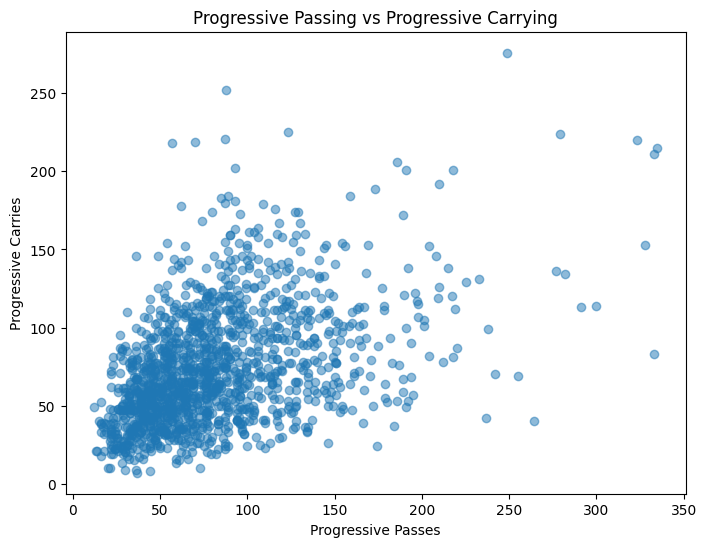

In [279]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Progressive Passes"],
    df["Progressive Carries"],
    alpha=0.5
)

plt.xlabel("Progressive Passes")
plt.ylabel("Progressive Carries")
plt.title("Progressive Passing vs Progressive Carrying")

plt.show()

In [280]:
display(
    pd.DataFrame({
        "player": df["player"],
        "squad": df["squad"],
        "season": df["season"],

        "PrgC": df["Progressive Carries"],
        "PrgP": df["Progressive Passes"],
        "carry_progression_share":
            feature_df["carry_progression_share"],

        "CPA": df["Carries into Penalty Area"],
        "PPA": df["Passes into Penalty Area"],
        "carry_box_entry_share":
            feature_df["carry_box_entry_share"]
    })
    .sort_values(
        "carry_progression_share",
        ascending=False
    )
    .head(20)
)

,player,squad,season,PrgC,PrgP,carry_progression_share,CPA,PPA,carry_box_entry_share
132,James McClean,West Brom,2017-2018,49,12,0.803279,10,21,0.322581
1367,Moses Simon,Nantes,2023-2024,146,36,0.802198,55,21,0.723684
1251,Jeremy Doku,Manchester City,2023-2024,218,57,0.792727,147,40,0.786096
502,Vinicius Júnior,Real Madrid,2019-2020,110,31,0.780142,69,12,0.851852
358,Josh Murphy,Cardiff City,2018-2019,81,23,0.778846,32,15,0.680851
361,Casimir Ninga,Caen,2018-2019,95,27,0.778689,23,14,0.621622
708,Stephy Mavididi,Montpellier,2020-2021,76,23,0.767677,23,7,0.766667
490,Onel Hernández,Norwich City,2019-2020,72,22,0.765957,37,10,0.787234
996,Iván Alejo,Cádiz,2022-2023,52,16,0.764706,2,24,0.076923
383,Milot Rashica,Werder Bremen,2018-2019,87,27,0.763158,35,23,0.603448


### Cross-Family Behavioural Choice Sanity Check

The cross-family ratios provide a different type of information from the preceding volume and propensity features.

`carry_progression_share` compares two alternative methods of advancing possession:

- carrying;
- passing.

`carry_box_entry_share` compares two alternative methods of penetrating the penalty area:

- entering with the ball;
- delivering the ball through a pass.

These measures are therefore interpreted as **relative behavioural preferences**, not as measures of total attacking involvement.

Extreme values are interpreted alongside their underlying action counts because ratios based on very small denominators may be unstable.

No minimum action threshold is imposed at this stage. Denominator reliability will be reconsidered during the complete candidate-feature quality audit.

# 9. Supporting Descriptors

The primary feature matrix is designed to answer:

> **How does the player tend to attack?**

A separate set of supporting descriptors is now constructed to help answer:

> **How effectively does that style work, and what other characteristics accompany it?**

These variables are deliberately excluded from initial style discovery.

They include measures of:

- 1v1 execution;
- ball security;
- passing execution;
- chance-creation effectiveness;
- attacking output;
- aerial involvement;
- high-pitch defensive involvement.

Keeping these variables separate allows stylistically similar players to be compared on quality and effectiveness after the style structure has been discovered.

For example, two players may have similar dribbling and progression profiles while differing substantially in take-on success, chance creation or finishing output.

In [281]:
support_df = df[identity_cols].copy()

print(support_df.shape)

display(
    support_df.head()
)

(1396, 8)


,player,player_id,squad,comp,season,age,born,Minutes
0,Marc Albrighton,Marc Albrighton_1989,Leicester City,Premier League,2017-2018,27,1989,2538
1,Romain Amalfitano,Romain Amalfitano_1989,Dijon,Ligue 1,2017-2018,27,1989,2703
2,Amath,Amath_1996,Getafe,La Liga,2017-2018,21,1996,2859
3,Nordin Amrabat,Nordin Amrabat_1987,Leganés,La Liga,2017-2018,30,1987,1623
4,Felipe Anderson,Felipe Anderson_1993,Lazio,Serie A,2017-2018,24,1993,1162


## 9.1 Dribbling Execution and Ball Security

Take-on frequency belongs to the playstyle representation because it describes the player's tendency to attack defenders.

Take-on success, miscontrols and dispossessions instead describe how successfully or securely those behaviours are executed.

These variables are therefore retained as supporting descriptors rather than style features.

In [282]:
support_df["take_on_success_pct"] = pd.to_numeric(
    df["Successful Take-ons %"],
    errors="coerce"
)

support_df["miscontrols_p90"] = per90(
    df["Carries_Mis"],
    df["Minutes"]
)

support_df["dispossessed_p90"] = per90(
    df["Times Dispossessed"],
    df["Minutes"]
)

## 9.2 Passing Execution

Passing completion is retained as an execution descriptor rather than a style feature.

A player attempting more aggressive or difficult passes may naturally record lower completion rates than a player making safer choices.

Completion percentage should therefore help evaluate a passing style rather than define it.

In [283]:
support_df["pass_completion_pct"] = pd.to_numeric(
    df["Pass Completion %"],
    errors="coerce"
)

support_df["long_pass_completion_pct"] = pd.to_numeric(
    df["Long Pass Completion %"],
    errors="coerce"
)

## 9.3 Chance Creation and Attacking Value

Several variables describe the effectiveness or downstream value of attacking actions.

These include:

- expected assists;
- expected assisted goals;
- shot-creating actions.

They are not used to define style because they depend partly on the quality of the resulting chance and on subsequent actions by teammates.

Instead, they are retained to evaluate how productive different attacking styles are.

In [284]:
support_df["xa_p90"] = per90(
    df["Expected_xA"],
    df["Minutes"]
)

support_df["xag_p90"] = per90(
    df["Expected_xAG"],
    df["Minutes"]
)

support_df["sca_p90"] = pd.to_numeric(
    df["Shot Creating Actions per 90"],
    errors="coerce"
)

## 9.4 Scoring and Attacking Output

Final attacking output is deliberately excluded from style discovery.

However, output variables are retained so that discovered styles can later be evaluated on production.

The supporting output layer focuses on non-penalty scoring, expected scoring and assists.

In [285]:
support_df["non_penalty_goals_p90"] = per90(
    df["Non-Penalty Goals"],
    df["Minutes"]
)

support_df["npxg_p90"] = per90(
    df["Non-Penalty Expected Goals"],
    df["Minutes"]
)

support_df["assists_p90"] = per90(
    df["Assists"],
    df["Minutes"]
)

## 9.5 Aerial Involvement

Aerial involvement can describe a meaningful secondary role difference between wide players.

Some wingers frequently contest aerial balls, act as direct outlets or attack aerial deliveries, while others receive almost entirely on the ground.

Aerial duel frequency is therefore retained as a supplemental role descriptor.

Aerial win percentage remains an execution measure rather than a style feature.

In [286]:
aerial_duels = (
    df["Aerial Duels_Won"] +
    df["Aerial Duels_Lost"]
)

support_df["aerial_duels_p90"] = per90(
    aerial_duels,
    df["Minutes"]
)

support_df["aerial_win_pct"] = (
    safe_ratio(
        df["Aerial Duels_Won"],
        aerial_duels
    ) * 100
)

## 9.6 High-Pitch Defensive Involvement

The primary model focuses on attacking winger style.

However, one defensive descriptor is retained:

`attacking_third_tackles_p90`

This measures defensive interventions made in the attacking third.

It should not be interpreted directly as pressing intensity because a press does not necessarily result in a tackle, and tackles can occur outside coordinated pressing structures.

The feature is therefore interpreted more conservatively as:

> **high-pitch defensive intervention frequency**

In [287]:
support_df["attacking_third_tackles_p90"] = per90(
    df["Tackles_Att 3rd"],
    df["Minutes"]
)

In [288]:
support_features = [
    # Dribbling execution / ball security
    "take_on_success_pct",
    "miscontrols_p90",
    "dispossessed_p90",

    # Passing execution
    "pass_completion_pct",
    "long_pass_completion_pct",

    # Chance creation
    "xa_p90",
    "xag_p90",
    "sca_p90",

    # Output
    "non_penalty_goals_p90",
    "npxg_p90",
    "assists_p90",

    # Supplemental role
    "aerial_duels_p90",
    "aerial_win_pct",
    "attacking_third_tackles_p90"
]

print("Supporting descriptors:", len(support_features))

Supporting descriptors: 14


In [289]:
display(
    support_df[support_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
take_on_success_pct,1396.0,51.172063,10.944190,12.900000,43.500000,50.750000,58.500000,100.000000
miscontrols_p90,1396.0,2.401225,0.691585,0.656250,1.913597,2.368599,2.847442,5.445434
dispossessed_p90,1396.0,1.617615,0.617231,0.279070,1.150665,1.538023,2.001764,4.503127
pass_completion_pct,1396.0,72.810172,6.677512,50.200000,68.600000,73.300000,77.625000,91.100000
long_pass_completion_pct,1396.0,51.503438,11.479766,7.100000,43.500000,51.200000,58.700000,95.800000
xa_p90,1396.0,0.159229,0.079769,0.014575,0.101927,0.147063,0.199847,0.587651
xag_p90,1396.0,0.173393,0.085921,0.014575,0.110512,0.159301,0.219794,0.652500
sca_p90,1396.0,3.444484,1.124157,0.970000,2.670000,3.300000,4.090000,8.870000
non_penalty_goals_p90,1396.0,0.216813,0.152653,0.000000,0.110086,0.188646,0.292242,1.229193
npxg_p90,1396.0,0.208552,0.113738,0.009989,0.132689,0.183173,0.260121,1.014085


In [290]:
support_missing = (
    support_df[support_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing")
)

support_missing["missing_pct"] = (
    support_missing["missing"] /
    len(support_df) *
    100
)

display(support_missing)

,missing,missing_pct
aerial_win_pct,1,0.071633
take_on_success_pct,0,0.000000
dispossessed_p90,0,0.000000
pass_completion_pct,0,0.000000
long_pass_completion_pct,0,0.000000
miscontrols_p90,0,0.000000
xa_p90,0,0.000000
xag_p90,0,0.000000
non_penalty_goals_p90,0,0.000000
sca_p90,0,0.000000


In [291]:
percentage_features = [
    "take_on_success_pct",
    "pass_completion_pct",
    "long_pass_completion_pct",
    "aerial_win_pct"
]

for col in percentage_features:

    print(
        col,
        "min:",
        support_df[col].min(),
        "max:",
        support_df[col].max()
    )

take_on_success_pct min: 12.9 max: 100.0
pass_completion_pct min: 50.2 max: 91.1
long_pass_completion_pct min: 7.1 max: 95.8
aerial_win_pct min: 0.0 max: 100.0


In [292]:
print(
    "Rows with zero aerial duels:",
    (aerial_duels == 0).sum()
)

Rows with zero aerial duels: 1


In [293]:
descriptor_sanity_features = [
    "take_on_success_pct",
    "dispossessed_p90",
    "xag_p90",
    "non_penalty_goals_p90",
    "aerial_duels_p90",
    "attacking_third_tackles_p90"
]

for col in descriptor_sanity_features:

    print("\n" + "=" * 80)
    print(col.upper())

    display(
        support_df[
            [
                "player",
                "squad",
                "season",
                col
            ]
        ]
        .sort_values(
            col,
            ascending=False
        )
        .head(10)
    )


TAKE_ON_SUCCESS_PCT


,player,squad,season,take_on_success_pct
28,Chris Brunt,West Brom,2017-2018,100.0
527,Jon Moncayola,Osasuna,2019-2020,90.9
205,Dušan Tadić,Southampton,2017-2018,85.9
699,Thomas Lemar,Atlético Madrid,2020-2021,85.7
409,Roberto Soriano,Bologna,2018-2019,85.7
590,Mattia Valoti,SPAL,2019-2020,84.6
320,Juanmi,Real Sociedad,2018-2019,84.2
784,Suso,Sevilla,2020-2021,84.1
365,Yuya Osako,Werder Bremen,2018-2019,82.6
79,Eden Hazard,Chelsea,2017-2018,82.5



DISPOSSESSED_P90


,player,squad,season,dispossessed_p90
359,Neymar,Paris S-G,2018-2019,4.503127
3,Nordin Amrabat,Leganés,2017-2018,4.436229
224,Wilfried Zaha,Crystal Palace,2017-2018,3.919184
156,Nicolas Pépé,Lille,2017-2018,3.801478
98,Gaël Kakuta,Amiens,2017-2018,3.678235
316,Adnan Januzaj,Real Sociedad,2018-2019,3.660287
4,Felipe Anderson,Lazio,2017-2018,3.640275
990,Wilfried Zaha,Crystal Palace,2021-2022,3.586957
504,Gaël Kakuta,Amiens,2019-2020,3.553223
387,Franck Ribéry,Bayern Munich,2018-2019,3.526405



XAG_P90


,player,squad,season,xag_p90
464,Ángel Di María,Paris S-G,2019-2020,0.652500
143,Neymar,Paris S-G,2017-2018,0.569429
522,Kylian Mbappé,Paris S-G,2019-2020,0.565102
152,Dimitri Payet,Marseille,2017-2018,0.552194
646,Ángel Di María,Paris S-G,2020-2021,0.543983
844,Ousmane Dembélé,Barcelona,2021-2022,0.530163
1131,Neymar,Paris S-G,2022-2023,0.512621
480,Serge Gnabry,Bayern Munich,2019-2020,0.496580
525,Lionel Messi,Barcelona,2019-2020,0.481250
352,Lionel Messi,Barcelona,2018-2019,0.477700


... (2 outputs left out)


AERIAL_DUELS_P90


,player,squad,season,aerial_duels_p90
332,Christian Kouamé,Genoa,2018-2019,10.743640
73,André Hahn,Hamburger SV,2017-2018,10.405007
430,Michail Antonio,West Ham,2019-2020,9.977376
30,Caiuby,Augsburg,2017-2018,9.330998
1165,Renaud Ripart,Troyes,2022-2023,9.136364
380,Ignacio Pussetto,Udinese,2018-2019,8.966942
172,Richarlison,Watford,2017-2018,8.831031
113,Mathew Leckie,Hertha BSC,2017-2018,8.548300
1326,Tijjani Noslin,Hellas Verona,2023-2024,8.065721
677,André Hahn,Augsburg,2020-2021,7.908689



ATTACKING_THIRD_TACKLES_P90


,player,squad,season,attacking_third_tackles_p90
4,Felipe Anderson,Lazio,2017-2018,1.239243
247,Gabriel Boschilia,Nantes,2018-2019,0.887036
1332,Dango Ouattara,Bournemouth,2023-2024,0.878763
1095,Khvicha Kvaratskhelia,Napoli,2022-2023,0.822081
24,Sofiane Boufal,Southampton,2017-2018,0.812141
995,Kevin Agudelo,Spezia,2022-2023,0.802440
837,Franco Cervi,Celta Vigo,2021-2022,0.799556
1104,Giovani Lo Celso,Villarreal,2022-2023,0.799290
1251,Jeremy Doku,Manchester City,2023-2024,0.789969
1096,Érik Lamela,Sevilla,2022-2023,0.780911


### Supporting Descriptor Status

A compact supporting layer has now been constructed alongside the candidate attacking-style matrix.

The two datasets serve different analytical purposes:

### `feature_df`

Contains behavioural features that may eventually drive:

- player similarity;
- dimensionality reduction;
- archetype discovery.

### `support_df`

Contains quality, output and supplemental role descriptors used to:

- evaluate discovered styles;
- explain differences between stylistically similar players;
- support recruitment and role-fit interpretation.

Supporting descriptors are not included in the initial style-discovery feature space.

# 10. Candidate Feature Quality Audit

Feature construction does not guarantee that a variable is suitable for modelling.

The complete candidate pool is therefore audited before any standardization, dimensionality reduction or similarity analysis.

This stage asks:

- Are values missing?
- Are any features effectively constant?
- Are distributions excessively sparse or skewed?
- Are engineered shares bounded as expected?
- Are extreme values plausible?
- Are ratio features being driven by very small denominators?
- Do any features show evidence of data-definition instability?

Importantly, no feature is removed simply because its distribution is unusual.

Football behaviours are often naturally skewed.

A feature is only reconsidered when its statistical behaviour creates a methodological or interpretability problem.

## 10.1 Candidate Feature Registry

All attacking-style candidates constructed so far are consolidated into a single registry.

The registry preserves each feature's:

- conceptual family;
- current classification as Core or Secondary;
- intended role in the analysis.

These classifications remain provisional until the empirical audit is complete.

In [294]:
feature_registry = pd.DataFrame([
    # Territory
    ("attacking_third_touch_share", "Territory", "Core"),
    ("box_penetration_touch_share", "Territory", "Core"),
    ("box_touch_share", "Territory", "Secondary"),

    # Receiving
    ("progressive_receptions_p90", "Receiving", "Core"),
    ("progressive_reception_share", "Receiving", "Core"),

    # Carrying / Dribbling
    ("progressive_carries_p90", "Carrying", "Core"),
    ("progressive_carry_share", "Carrying", "Core"),
    ("carries_into_box_p90", "Carrying", "Core"),
    ("carries_into_final_third_p90", "Carrying", "Secondary"),
    ("take_ons_p90", "Dribbling", "Core"),
    ("take_ons_per_100_live_touches", "Dribbling", "Core"),
    ("progressive_distance_per_carry", "Carrying", "Secondary"),

    # Passing / Progression
    ("passes_attempted_p90", "Passing", "Secondary"),
    ("progressive_passes_p90", "Passing", "Core"),
    ("progressive_pass_share", "Passing", "Core"),
    ("passes_into_box_p90", "Passing", "Core"),
    ("passes_into_final_third_p90", "Passing", "Secondary"),
    ("crosses_p90", "Crossing", "Core"),
    ("cross_pass_share", "Crossing", "Core"),
    ("long_pass_share", "Passing Profile", "Secondary"),
    ("key_passes_p90", "Creation", "Secondary"),

    # Shooting
    ("shots_p90", "Shooting", "Core"),
    ("shots_per_100_att3rd_touches", "Shooting", "Core"),
    ("avg_shot_distance", "Shooting", "Core"),
    ("npxg_per_shot", "Shooting", "Secondary"),

    # Cross-family
    ("carry_progression_share", "Progression Method", "Core"),
    ("carry_box_entry_share", "Penetration Method", "Core"),
], columns=[
    "feature",
    "family",
    "status"
])

print("Candidate features:", len(feature_registry))

display(feature_registry)

Candidate features: 27


,feature,family,status
0,attacking_third_touch_share,Territory,Core
1,box_penetration_touch_share,Territory,Core
2,box_touch_share,Territory,Secondary
3,progressive_receptions_p90,Receiving,Core
4,progressive_reception_share,Receiving,Core
5,progressive_carries_p90,Carrying,Core
6,progressive_carry_share,Carrying,Core
7,carries_into_box_p90,Carrying,Core
8,carries_into_final_third_p90,Carrying,Secondary
9,take_ons_p90,Dribbling,Core


In [295]:
candidate_features = feature_registry["feature"].tolist()

missing_engineered_features = [
    col for col in candidate_features
    if col not in feature_df.columns
]

print(
    "Missing engineered candidate features:",
    missing_engineered_features
)

assert len(missing_engineered_features) == 0

Missing engineered candidate features: []


In [296]:
qa_rows = []

for col in candidate_features:

    s = feature_df[col]

    qa_rows.append({
        "feature": col,
        "missing_n": s.isna().sum(),
        "missing_pct": s.isna().mean() * 100,
        "unique_n": s.nunique(dropna=True),
        "zero_n": (s == 0).sum(),
        "zero_pct": (s == 0).mean() * 100,
        "min": s.min(),
        "q01": s.quantile(0.01),
        "q05": s.quantile(0.05),
        "median": s.median(),
        "q95": s.quantile(0.95),
        "q99": s.quantile(0.99),
        "max": s.max(),
        "mean": s.mean(),
        "std": s.std(),
        "skew": s.skew()
    })

feature_qa = pd.DataFrame(qa_rows)

feature_qa = feature_qa.merge(
    feature_registry,
    on="feature",
    how="left",
    validate="one_to_one"
)

feature_qa = feature_qa[
    [
        "feature",
        "family",
        "status",
        "missing_n",
        "missing_pct",
        "unique_n",
        "zero_n",
        "zero_pct",
        "min",
        "q01",
        "q05",
        "median",
        "q95",
        "q99",
        "max",
        "mean",
        "std",
        "skew"
    ]
]

display(feature_qa)

,feature,family,status,missing_n,missing_pct,unique_n,zero_n,zero_pct,min,q01,q05,median,q95,q99,max,mean,std,skew
0,attacking_third_touch_share,Territory,Core,0,0.0,1387,0,0.000000,0.103330,0.250081,0.322002,0.476388,0.611578,0.674561,0.714984,0.472888,0.087398,-0.275155
1,box_penetration_touch_share,Territory,Core,0,0.0,1338,0,0.000000,0.027027,0.049373,0.072398,0.150891,0.263476,0.305420,0.365979,0.159187,0.058283,0.458929
2,box_touch_share,Territory,Secondary,0,0.0,1374,0,0.000000,0.003444,0.015804,0.028443,0.071672,0.143104,0.180860,0.225865,0.077344,0.035925,0.730570
3,progressive_receptions_p90,Receiving,Core,0,0.0,1382,0,0.000000,0.987203,2.414011,3.771081,7.268931,12.126739,15.116049,19.674419,7.533262,2.591188,0.695994
4,progressive_reception_share,Receiving,Core,0,0.0,1363,0,0.000000,0.025274,0.062789,0.105994,0.223238,0.328255,0.366490,0.412500,0.220765,0.067478,-0.096062
5,progressive_carries_p90,Carrying,Core,0,0.0,1375,0,0.000000,0.411168,0.876641,1.341729,3.167669,5.886854,7.471151,12.300940,3.319767,1.389195,0.907899
6,progressive_carry_share,Carrying,Core,0,0.0,1341,0,0.000000,0.018561,0.032181,0.049900,0.105960,0.170350,0.201721,0.266385,0.107964,0.037455,0.368998
7,carries_into_box_p90,Carrying,Core,0,0.0,1348,4,0.286533,0.000000,0.076583,0.218687,1.017769,2.552295,3.301513,8.294671,1.145156,0.758759,1.562555
8,carries_into_final_third_p90,Carrying,Secondary,0,0.0,1365,0,0.000000,0.061771,0.707294,0.987391,2.123377,3.810494,5.088553,7.054871,2.244430,0.909408,1.059230
9,take_ons_p90,Dribbling,Core,0,0.0,1371,0,0.000000,0.245734,0.755655,1.206455,3.214580,6.232573,8.223151,11.084431,3.402627,1.572581,0.960827


## 10.3 Missingness

Missingness is evaluated before modelling because missing values may arise for different reasons:

- source-data absence;
- undefined ratios caused by zero denominators;
- genuine absence of the underlying behaviour;
- historical differences in data availability.

Missingness is therefore interpreted feature-by-feature rather than automatically imputed.

In [297]:
missing_audit = (
    feature_qa[
        [
            "feature",
            "family",
            "status",
            "missing_n",
            "missing_pct"
        ]
    ]
    .sort_values(
        "missing_pct",
        ascending=False
    )
)

display(missing_audit)

,feature,family,status,missing_n,missing_pct
0,attacking_third_touch_share,Territory,Core,0,0.0
1,box_penetration_touch_share,Territory,Core,0,0.0
2,box_touch_share,Territory,Secondary,0,0.0
3,progressive_receptions_p90,Receiving,Core,0,0.0
4,progressive_reception_share,Receiving,Core,0,0.0
5,progressive_carries_p90,Carrying,Core,0,0.0
6,progressive_carry_share,Carrying,Core,0,0.0
7,carries_into_box_p90,Carrying,Core,0,0.0
8,carries_into_final_third_p90,Carrying,Secondary,0,0.0
9,take_ons_p90,Dribbling,Core,0,0.0


In [298]:
display(
    missing_audit[
        missing_audit["missing_n"] > 0
    ]
)

,feature,family,status,missing_n,missing_pct


## 10.4 Zero Concentration and Information Content

Some football behaviours may naturally occur infrequently.

A high proportion of zero observations is therefore not automatically grounds for exclusion.

However, extreme zero concentration can make a feature:

- unstable;
- dominated by rare events;
- less useful for similarity modelling.

Zero rates and the number of distinct values are inspected as indicators of potential low-information features.

In [299]:
zero_audit = (
    feature_qa[
        [
            "feature",
            "family",
            "status",
            "unique_n",
            "zero_n",
            "zero_pct"
        ]
    ]
    .sort_values(
        "zero_pct",
        ascending=False
    )
)

display(zero_audit)

,feature,family,status,unique_n,zero_n,zero_pct
7,carries_into_box_p90,Carrying,Core,1348,4,0.286533
26,carry_box_entry_share,Penetration Method,Core,736,4,0.286533
1,box_penetration_touch_share,Territory,Core,1338,0,0.000000
2,box_touch_share,Territory,Secondary,1374,0,0.000000
3,progressive_receptions_p90,Receiving,Core,1382,0,0.000000
5,progressive_carries_p90,Carrying,Core,1375,0,0.000000
4,progressive_reception_share,Receiving,Core,1363,0,0.000000
6,progressive_carry_share,Carrying,Core,1341,0,0.000000
8,carries_into_final_third_p90,Carrying,Secondary,1365,0,0.000000
9,take_ons_p90,Dribbling,Core,1371,0,0.000000


In [300]:
potentially_sparse = feature_qa[
    (feature_qa["zero_pct"] >= 25) |
    (feature_qa["unique_n"] <= 20)
][
    [
        "feature",
        "family",
        "status",
        "unique_n",
        "zero_pct"
    ]
]

display(potentially_sparse)

,feature,family,status,unique_n,zero_pct


In [301]:
share_candidates = [
    "attacking_third_touch_share",
    "box_penetration_touch_share",
    "box_touch_share",
    "progressive_reception_share",
    "progressive_carry_share",
    "progressive_pass_share",
    "cross_pass_share",
    "long_pass_share",
    "carry_progression_share",
    "carry_box_entry_share"
]

for col in share_candidates:

    invalid = (
        feature_df[col].notna() &
        (
            (feature_df[col] < 0) |
            (feature_df[col] > 1)
        )
    )

    print(
        f"{col}: {invalid.sum()} invalid values"
    )

attacking_third_touch_share: 0 invalid values
box_penetration_touch_share: 0 invalid values
box_touch_share: 0 invalid values
progressive_reception_share: 0 invalid values
progressive_carry_share: 0 invalid values
progressive_pass_share: 0 invalid values
cross_pass_share: 0 invalid values
long_pass_share: 0 invalid values
carry_progression_share: 0 invalid values
carry_box_entry_share: 0 invalid values


In [302]:
negative_counts = {}

for col in candidate_features:

    negative_counts[col] = (
        feature_df[col] < 0
    ).sum()

negative_counts = pd.Series(
    negative_counts,
    name="negative_values"
)

display(
    negative_counts[
        negative_counts > 0
    ]
)

,negative_values


In [303]:
def plot_feature_distributions(
    dataframe,
    features,
    bins=30,
    figsize=(12, 3)
):
    """
    Plot one histogram per feature.
    """

    for col in features:

        plt.figure(figsize=figsize)

        plt.hist(
            dataframe[col].dropna(),
            bins=bins
        )

        plt.title(col)
        plt.xlabel(col)
        plt.ylabel("Observations")

        plt.show()

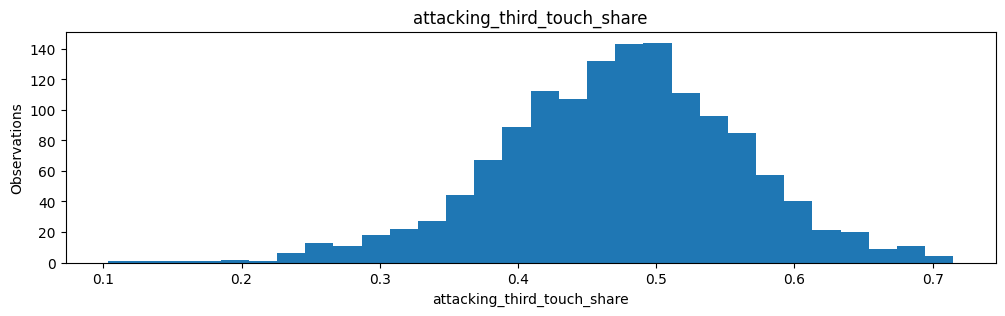

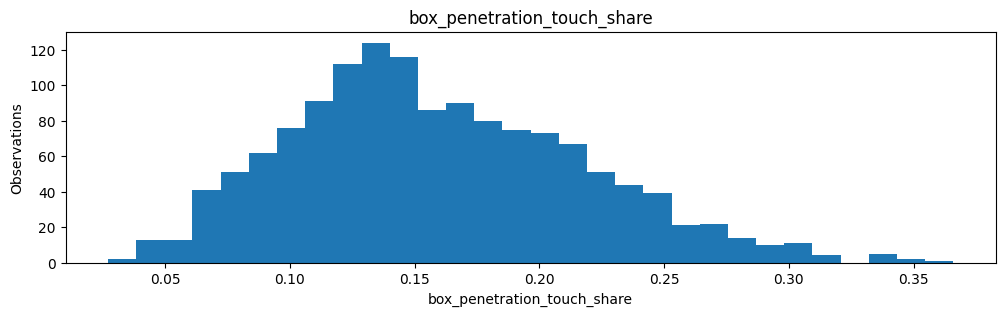

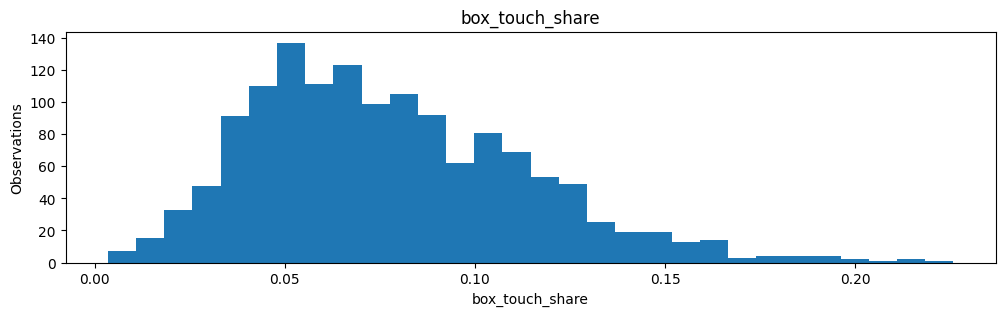

In [304]:
plot_feature_distributions(
    feature_df,
    territory_features
)

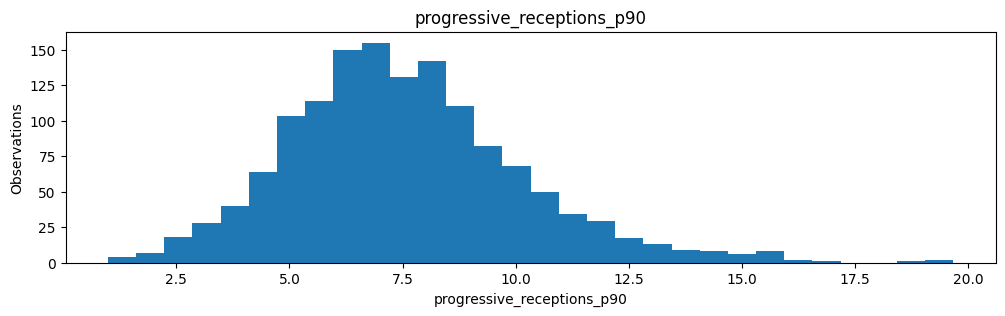

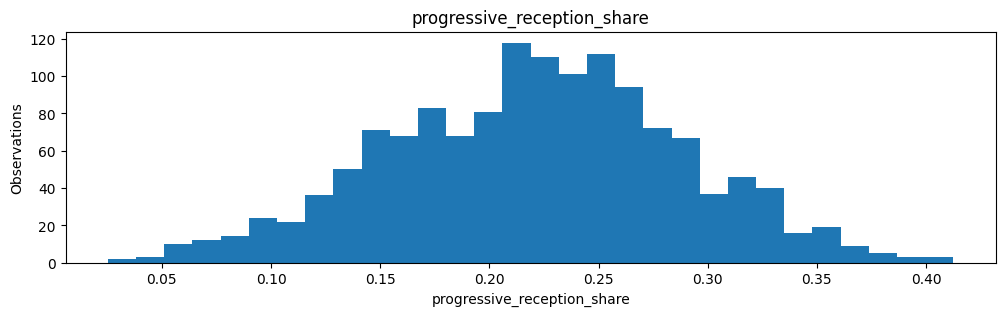

In [305]:
plot_feature_distributions(
    feature_df,
    receiving_features
)

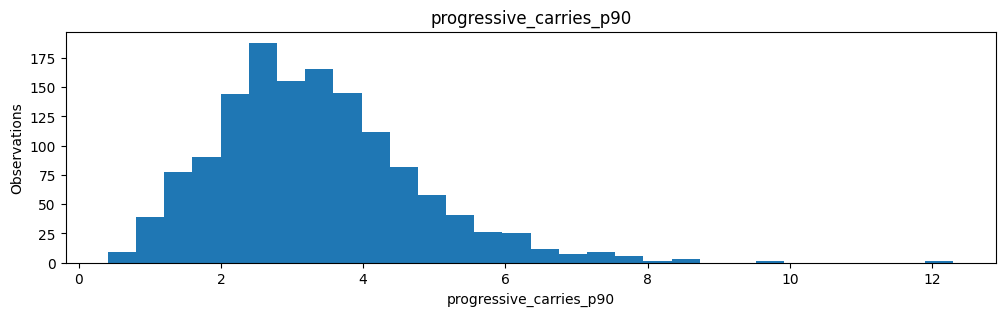

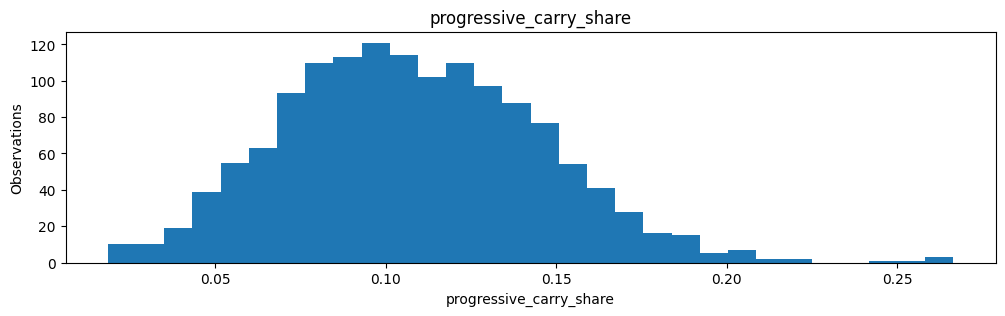

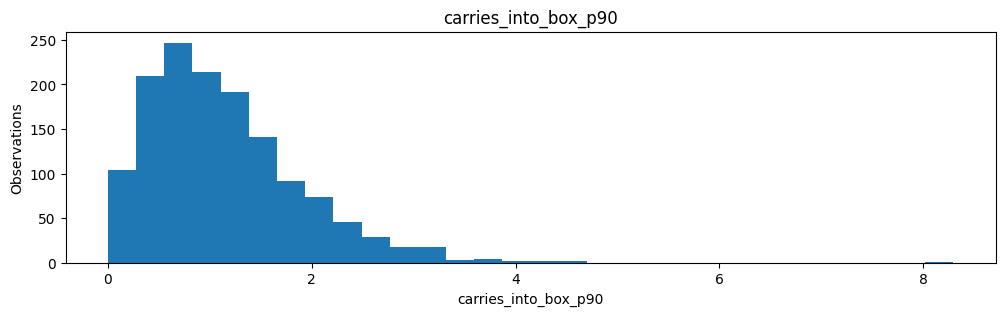

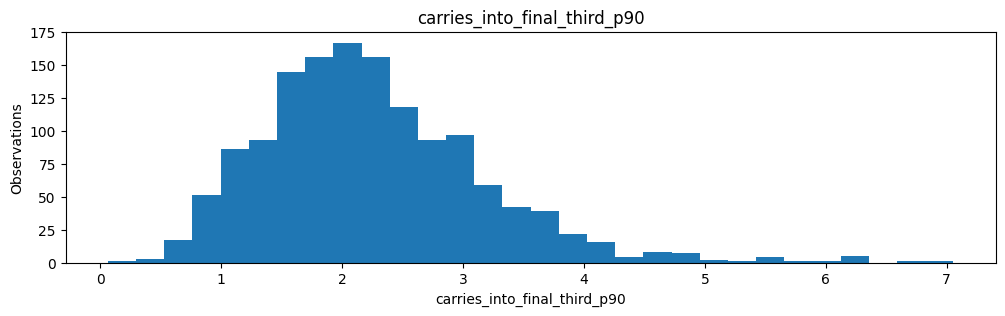

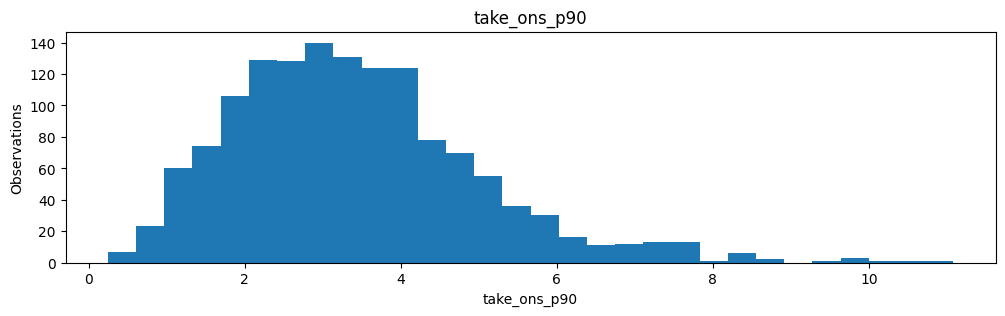

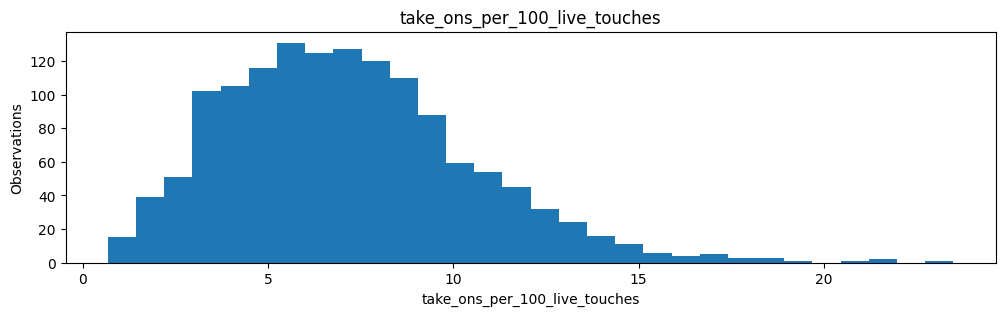

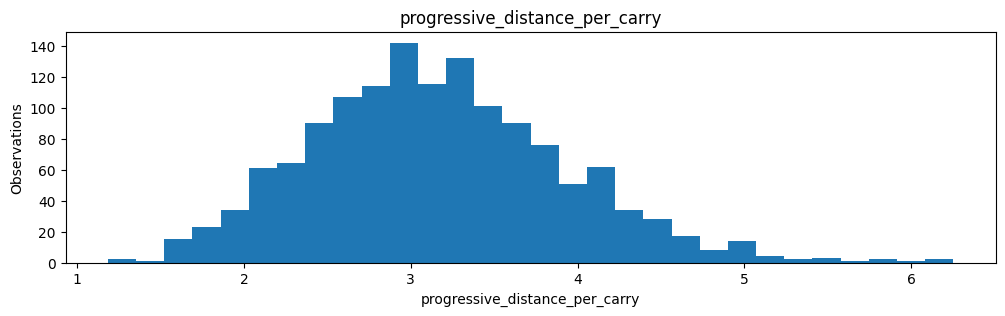

In [306]:
plot_feature_distributions(
    feature_df,
    carrying_features
)

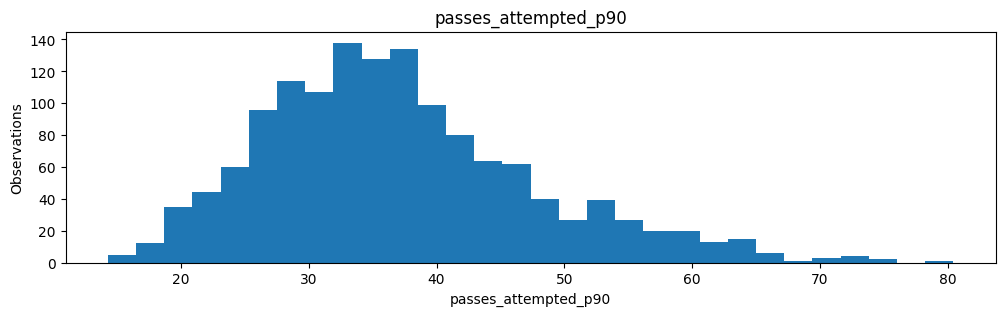

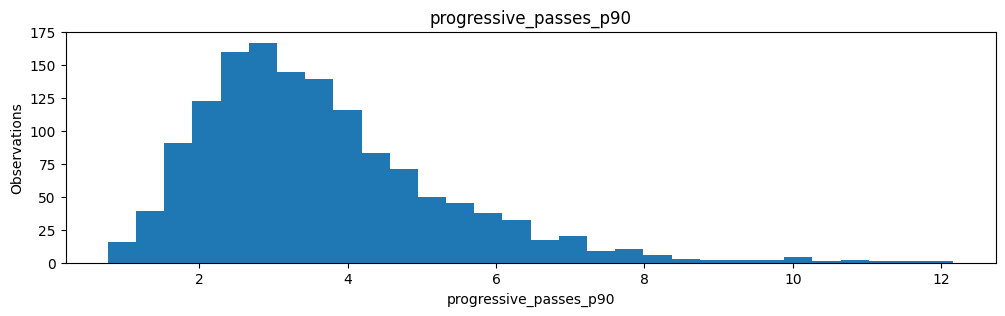

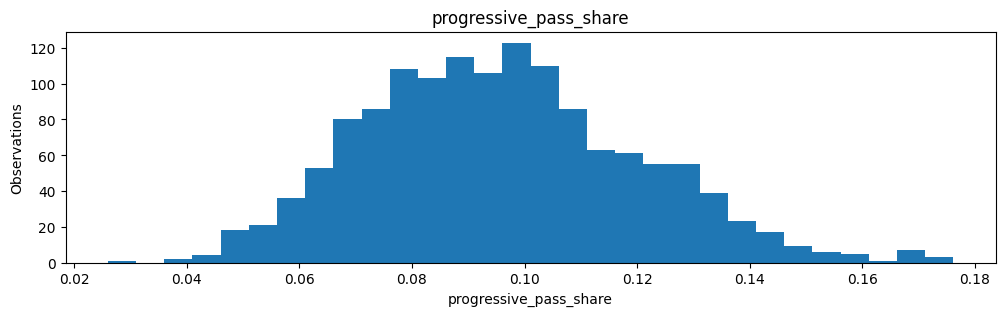

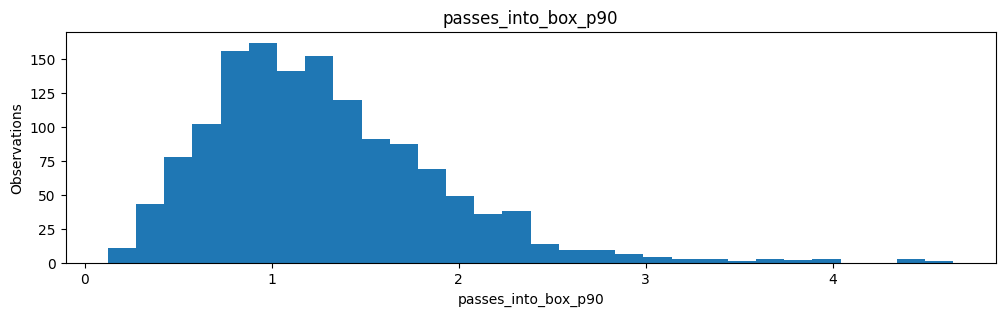

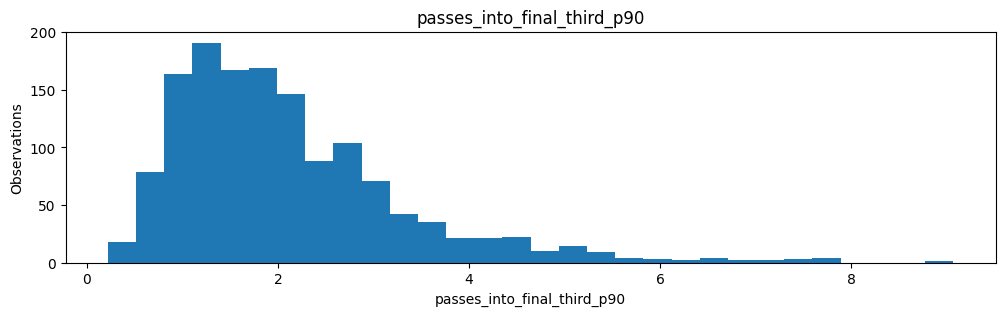

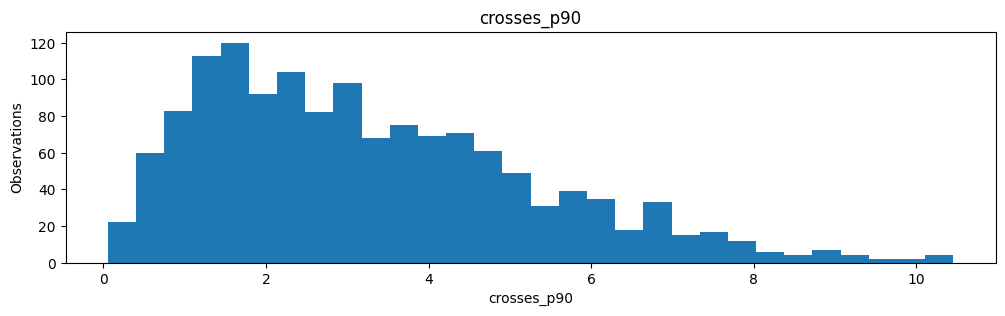

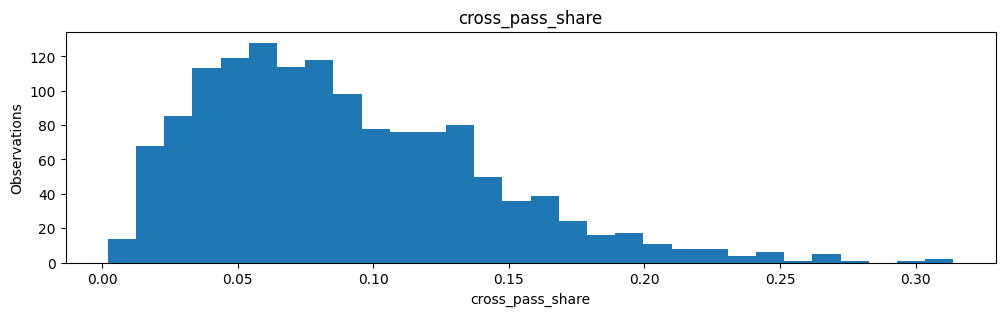

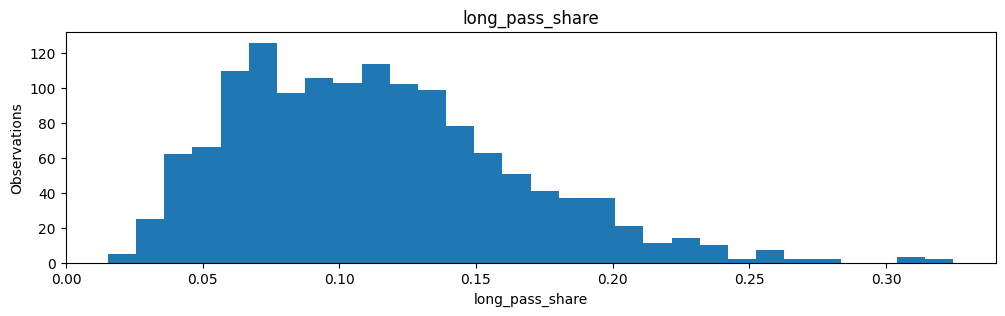

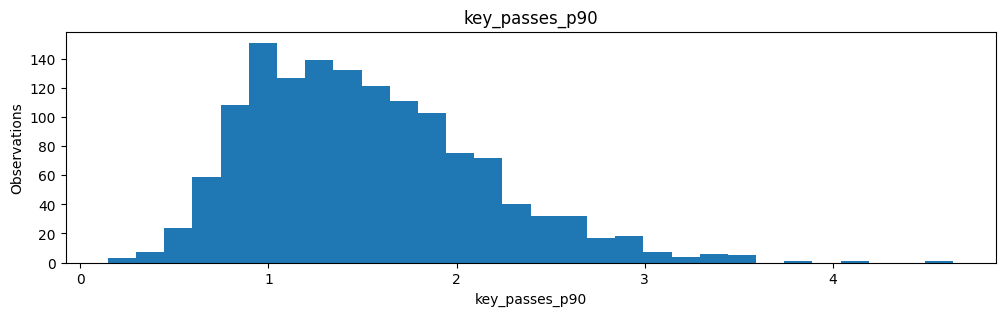

In [307]:
plot_feature_distributions(
    feature_df,
    passing_features
)

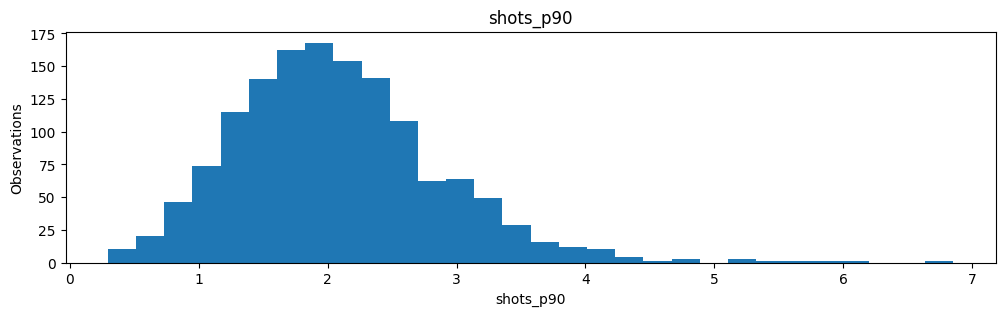

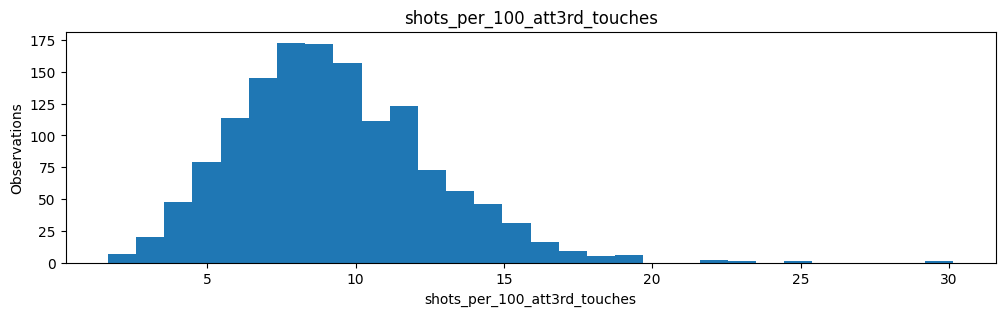

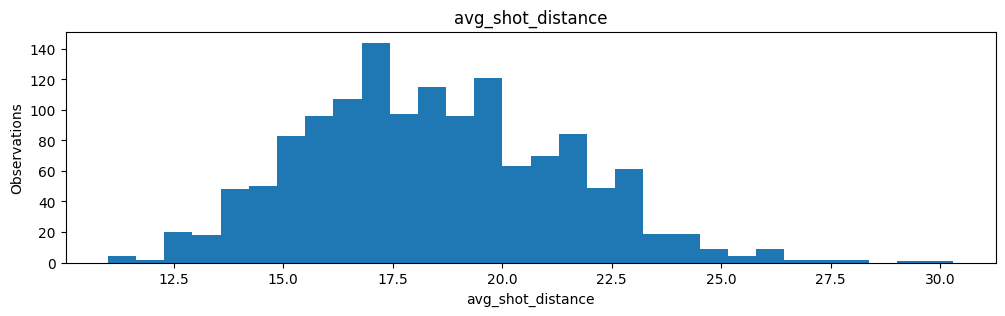

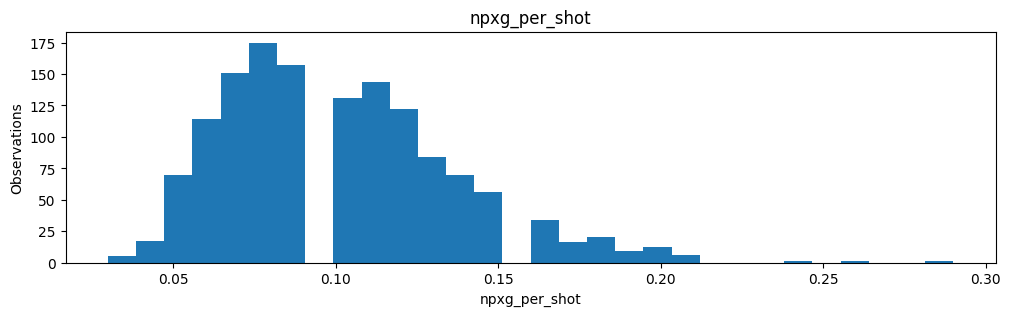

In [308]:
plot_feature_distributions(
    feature_df,
    shooting_features
)

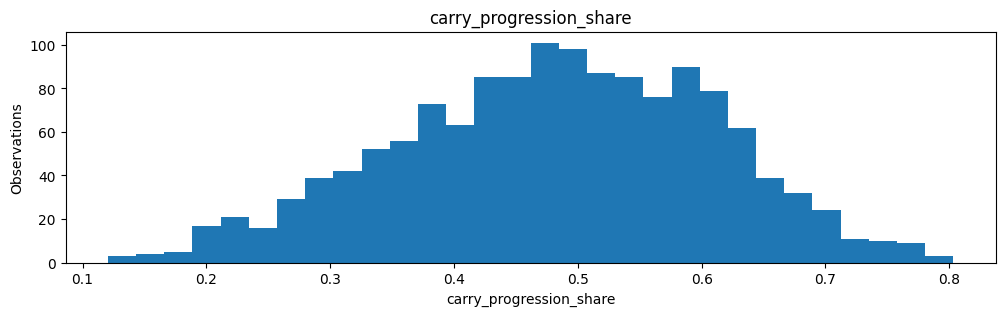

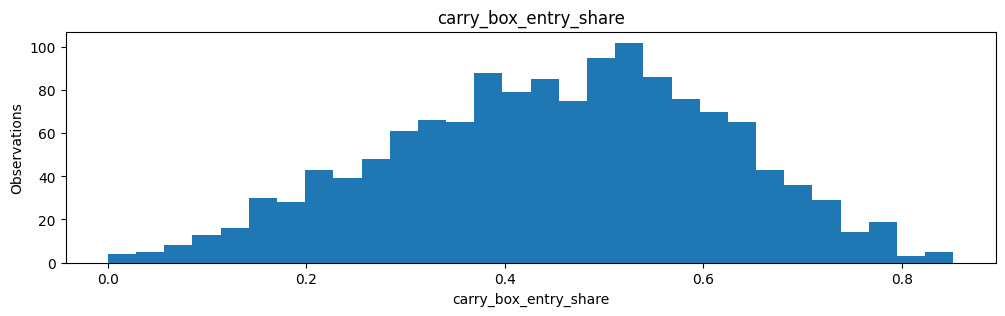

In [309]:
plot_feature_distributions(
    feature_df,
    choice_features
)

In [310]:
skew_audit = (
    feature_qa[
        [
            "feature",
            "family",
            "status",
            "skew"
        ]
    ]
    .assign(
        abs_skew=lambda x: x["skew"].abs()
    )
    .sort_values(
        "abs_skew",
        ascending=False
    )
)

display(skew_audit)

,feature,family,status,skew,abs_skew
16,passes_into_final_third_p90,Passing,Secondary,1.616841,1.616841
7,carries_into_box_p90,Carrying,Core,1.562555,1.562555
15,passes_into_box_p90,Passing,Core,1.273723,1.273723
13,progressive_passes_p90,Passing,Core,1.266516,1.266516
8,carries_into_final_third_p90,Carrying,Secondary,1.059230,1.059230
9,take_ons_p90,Dribbling,Core,0.960827,0.960827
5,progressive_carries_p90,Carrying,Core,0.907899,0.907899
18,cross_pass_share,Crossing,Core,0.905098,0.905098
21,shots_p90,Shooting,Core,0.896696,0.896696
17,crosses_p90,Crossing,Core,0.801165,0.801165


In [311]:
display(
    skew_audit[
        skew_audit["abs_skew"] >= 2
    ]
)

,feature,family,status,skew,abs_skew


In [312]:
extreme_audit_rows = []

for col in candidate_features:

    s = feature_df[col].dropna()

    q99 = s.quantile(0.99)
    maximum = s.max()

    if q99 != 0:
        max_to_q99 = maximum / q99
    else:
        max_to_q99 = np.nan

    extreme_audit_rows.append({
        "feature": col,
        "q99": q99,
        "max": maximum,
        "max_to_q99": max_to_q99
    })

extreme_audit = (
    pd.DataFrame(extreme_audit_rows)
    .sort_values(
        "max_to_q99",
        ascending=False
    )
)

display(extreme_audit)

,feature,q99,max,max_to_q99
7,carries_into_box_p90,3.301513,8.294671,2.512384
22,shots_per_100_att3rd_touches,17.950158,30.154639,1.679909
5,progressive_carries_p90,7.471151,12.300940,1.646459
21,shots_p90,4.333712,6.853392,1.581414
24,npxg_per_shot,0.200000,0.290000,1.450000
20,key_passes_p90,3.213688,4.639966,1.443813
10,take_ons_per_100_live_touches,16.866900,23.498695,1.393184
8,carries_into_final_third_p90,5.088553,7.054871,1.386420
16,passes_into_final_third_p90,6.573054,9.071064,1.380038
15,passes_into_box_p90,3.382037,4.644305,1.373227


In [313]:
display(
    extreme_audit[
        extreme_audit["max_to_q99"] > 1.5
    ]
)

,feature,q99,max,max_to_q99
7,carries_into_box_p90,3.301513,8.294671,2.512384
22,shots_per_100_att3rd_touches,17.950158,30.154639,1.679909
5,progressive_carries_p90,7.471151,12.300940,1.646459
21,shots_p90,4.333712,6.853392,1.581414


## 10.9 Ratio Denominator Reliability

Ratio features can produce apparently extreme stylistic values from very small underlying action counts.

For example:

- 1 carry into the box;
- 0 passes into the box;

produces a carry box-entry share of 1.0.

The value is mathematically correct, but provides less evidence of a stable behavioural preference than the same ratio based on dozens of actions.

Ratio features are therefore audited alongside their underlying denominators.

No denominator threshold is imposed at this stage.

In [314]:
denominator_audit = pd.DataFrame({
    "player": df["player"],
    "squad": df["squad"],
    "season": df["season"],

    "total_touches":
        df["Touches_Touches"],

    "attacking_third_touches":
        df["Touches_Att 3rd"],

    "receptions":
        df["Receiving_Rec"],

    "total_carries":
        df["Carries_Carries"],

    "live_touches":
        df["Touches_Live"],

    "pass_attempts":
        df["Passes Attempted"],

    "donor_pass_attempts":
        df["Total_Att"],

    "progression_actions":
        (
            df["Progressive Carries"] +
            df["Progressive Passes"]
        ),

    "box_entry_actions":
        (
            df["Carries into Penalty Area"] +
            df["Passes into Penalty Area"]
        )
})

In [315]:
display(
    denominator_audit.drop(
        columns=[
            "player",
            "squad",
            "season"
        ]
    )
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50
        ]
    )
    .T
)

,count,mean,std,min,1%,5%,10%,25%,50%,max
total_touches,1396.0,1086.006447,402.593763,354.0,452.95,560.0,638.0,777.00,1017.0,3015.0
attacking_third_touches,1396.0,512.703438,215.243517,115.0,185.00,243.0,280.0,350.75,466.0,1687.0
receptions,1396.0,781.171203,320.335807,238.0,291.90,384.0,432.0,539.75,718.5,2625.0
total_carries,1396.0,689.589542,277.827955,177.0,254.90,342.0,389.0,483.00,643.5,2167.0
live_touches,1396.0,1085.358166,402.151701,354.0,452.95,560.0,637.5,777.00,1017.0,3014.0
pass_attempts,1396.0,825.549427,353.667444,234.0,299.95,383.5,447.5,558.00,759.0,2573.0
donor_pass_attempts,1396.0,825.547278,353.666586,234.0,299.95,383.5,447.5,558.00,759.0,2573.0
progression_actions,1396.0,154.883238,71.834048,30.0,46.00,61.0,77.5,103.00,141.5,550.0
box_entry_actions,1396.0,54.169771,31.011234,7.0,11.00,18.0,22.0,32.00,47.0,226.0


In [316]:
display(
    denominator_audit[
        [
            "progression_actions",
            "box_entry_actions"
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90
        ]
    )
    .T
)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,max
progression_actions,1396.0,154.883238,71.834048,30.0,46.0,61.0,77.5,103.0,141.5,197.0,249.0,550.0
box_entry_actions,1396.0,54.169771,31.011234,7.0,11.0,18.0,22.0,32.0,47.0,70.0,96.0,226.0


In [317]:
for threshold in [1, 3, 5, 10, 20]:

    count = (
        denominator_audit["box_entry_actions"]
        < threshold
    ).sum()

    print(
        f"Rows with fewer than {threshold} "
        f"box-entry actions: {count} "
        f"({count / len(df) * 100:.1f}%)"
    )

Rows with fewer than 1 box-entry actions: 0 (0.0%)
Rows with fewer than 3 box-entry actions: 0 (0.0%)
Rows with fewer than 5 box-entry actions: 0 (0.0%)
Rows with fewer than 10 box-entry actions: 7 (0.5%)
Rows with fewer than 20 box-entry actions: 99 (7.1%)


In [318]:
for threshold in [5, 10, 20, 30, 50]:

    count = (
        denominator_audit["progression_actions"]
        < threshold
    ).sum()

    print(
        f"Rows with fewer than {threshold} "
        f"progression actions: {count} "
        f"({count / len(df) * 100:.1f}%)"
    )

Rows with fewer than 5 progression actions: 0 (0.0%)
Rows with fewer than 10 progression actions: 0 (0.0%)
Rows with fewer than 20 progression actions: 0 (0.0%)
Rows with fewer than 30 progression actions: 0 (0.0%)
Rows with fewer than 50 progression actions: 24 (1.7%)


In [319]:
box_entry_diagnostic = pd.DataFrame({
    "player": df["player"],
    "squad": df["squad"],
    "season": df["season"],
    "CPA": df["Carries into Penalty Area"],
    "PPA": df["Passes into Penalty Area"],
    "box_entry_actions":
        denominator_audit["box_entry_actions"],
    "carry_box_entry_share":
        feature_df["carry_box_entry_share"]
})

display(
    box_entry_diagnostic
    .sort_values(
        "box_entry_actions"
    )
    .head(30)
)

,player,squad,season,CPA,PPA,box_entry_actions,carry_box_entry_share
681,Jeff Hendrick,Newcastle Utd,2020-2021,2,5,7,0.285714
527,Jon Moncayola,Osasuna,2019-2020,1,6,7,0.142857
414,Mattias Svanberg,Bologna,2018-2019,0,7,7,0.000000
1340,Mathias Pereira Lage,Brest,2023-2024,3,5,8,0.375000
58,Oghenekaro Etebo,Las Palmas,2017-2018,1,7,8,0.125000
505,Kenan Karaman,Düsseldorf,2019-2020,4,5,9,0.444444
770,Frédéric Sammaritano,Dijon,2020-2021,0,9,9,0.000000
809,Marc Albrighton,Leicester City,2021-2022,2,8,10,0.200000
1204,Simon Zoller,Bochum,2022-2023,6,4,10,0.600000
328,Sebastian Kerk,Nürnberg,2018-2019,1,9,10,0.100000


In [320]:
progression_diagnostic = pd.DataFrame({
    "player": df["player"],
    "squad": df["squad"],
    "season": df["season"],
    "PrgC": df["Progressive Carries"],
    "PrgP": df["Progressive Passes"],
    "progression_actions":
        denominator_audit["progression_actions"],
    "carry_progression_share":
        feature_df["carry_progression_share"]
})

display(
    progression_diagnostic
    .sort_values(
        "progression_actions"
    )
    .head(30)
)

,player,squad,season,PrgC,PrgP,progression_actions,carry_progression_share
328,Sebastian Kerk,Nürnberg,2018-2019,10,20,30,0.333333
1204,Simon Zoller,Bochum,2022-2023,10,21,31,0.322581
670,Karlan Grant,West Brom,2020-2021,21,13,34,0.617647
311,Adrien Hunou,Rennes,2018-2019,18,16,34,0.529412
1197,Theo Walcott,Southampton,2022-2023,21,14,35,0.600000
414,Mattias Svanberg,Bologna,2018-2019,9,30,39,0.230769
334,Aaron Lennon,Burnley,2018-2019,21,18,39,0.538462
1348,Elba Rashani,Clermont Foot,2023-2024,19,22,41,0.463415
159,Maximilian Philipp,Dortmund,2017-2018,13,28,41,0.317073
1340,Mathias Pereira Lage,Brest,2023-2024,19,23,42,0.452381


In [321]:
feature_audit_summary = feature_qa.copy()

feature_audit_summary["missing_flag"] = (
    feature_audit_summary["missing_pct"] > 0
)

feature_audit_summary["sparse_flag"] = (
    feature_audit_summary["zero_pct"] >= 25
)

feature_audit_summary["high_skew_flag"] = (
    feature_audit_summary["skew"].abs() >= 2
)

feature_audit_summary = (
    feature_audit_summary.merge(
        extreme_audit[
            [
                "feature",
                "max_to_q99"
            ]
        ],
        on="feature",
        how="left"
    )
)

feature_audit_summary["extreme_flag"] = (
    feature_audit_summary["max_to_q99"] > 1.5
)

In [322]:
display(
    feature_audit_summary[
        [
            "feature",
            "family",
            "status",
            "missing_pct",
            "zero_pct",
            "skew",
            "max_to_q99",
            "missing_flag",
            "sparse_flag",
            "high_skew_flag",
            "extreme_flag"
        ]
    ]
)

,feature,family,status,missing_pct,zero_pct,skew,max_to_q99,missing_flag,sparse_flag,high_skew_flag,extreme_flag
0,attacking_third_touch_share,Territory,Core,0.0,0.000000,-0.275155,1.059924,False,False,False,False
1,box_penetration_touch_share,Territory,Core,0.0,0.000000,0.458929,1.198283,False,False,False,False
2,box_touch_share,Territory,Secondary,0.0,0.000000,0.730570,1.248839,False,False,False,False
3,progressive_receptions_p90,Receiving,Core,0.0,0.000000,0.695994,1.301558,False,False,False,False
4,progressive_reception_share,Receiving,Core,0.0,0.000000,-0.096062,1.125542,False,False,False,False
5,progressive_carries_p90,Carrying,Core,0.0,0.000000,0.907899,1.646459,False,False,False,True
6,progressive_carry_share,Carrying,Core,0.0,0.000000,0.368998,1.320562,False,False,False,False
7,carries_into_box_p90,Carrying,Core,0.0,0.286533,1.562555,2.512384,False,False,False,True
8,carries_into_final_third_p90,Carrying,Secondary,0.0,0.000000,1.059230,1.386420,False,False,False,False
9,take_ons_p90,Dribbling,Core,0.0,0.000000,0.960827,1.347954,False,False,False,False


In [323]:
flagged_features = feature_audit_summary[
    feature_audit_summary[
        [
            "missing_flag",
            "sparse_flag",
            "high_skew_flag",
            "extreme_flag"
        ]
    ].any(axis=1)
]

display(
    flagged_features[
        [
            "feature",
            "family",
            "status",
            "missing_pct",
            "zero_pct",
            "skew",
            "max_to_q99",
            "missing_flag",
            "sparse_flag",
            "high_skew_flag",
            "extreme_flag"
        ]
    ]
)

,feature,family,status,missing_pct,zero_pct,skew,max_to_q99,missing_flag,sparse_flag,high_skew_flag,extreme_flag
5,progressive_carries_p90,Carrying,Core,0.0,0.000000,0.907899,1.646459,False,False,False,True
7,carries_into_box_p90,Carrying,Core,0.0,0.286533,1.562555,2.512384,False,False,False,True
21,shots_p90,Shooting,Core,0.0,0.000000,0.896696,1.581414,False,False,False,True
22,shots_per_100_att3rd_touches,Shooting,Core,0.0,0.000000,0.729984,1.679909,False,False,False,True


## 10A. Structural Audit — Findings

The structural feature audit evaluates each candidate for:

- missingness;
- sparsity;
- theoretical validity;
- distribution shape;
- extreme-value concentration;
- ratio-denominator reliability.

Diagnostic flags are not treated as automatic exclusion criteria.

Each flagged variable is reviewed in football and data-definition context before any decision is made.

The next stage examines whether the candidate features are **temporally comparable across seasons**, including potential historical definition changes in the underlying FBref data.

# 10B. Temporal Stability and Historical Definition Audit

The dataset spans seven seasons from 2017-18 to 2023-24.

For a playstyle feature to support cross-season player comparison, its interpretation should remain reasonably stable through time.

However, changes in seasonal distributions can arise from several different causes:

- genuine tactical evolution;
- changes in the winger population;
- league-level changes;
- sample variation;
- changes in the underlying data provider or event definition.

A shift in a seasonal median is therefore **not automatically evidence of a data break**.

The purpose of this section is to identify suspicious discontinuities that require closer investigation, particularly around variables previously flagged as potentially sensitive to historical definition changes.

The audit proceeds in three stages:

1. inspect season-level distributions for every candidate feature;
2. quantify adjacent-season changes;
3. investigate suspicious features at the raw-variable level.

No temporal standardization or correction is applied until the evidence is reviewed.

In [324]:
season_order = [
    "2017-2018",
    "2018-2019",
    "2019-2020",
    "2020-2021",
    "2021-2022",
    "2022-2023",
    "2023-2024"
]

print(df["season"].value_counts().sort_index())

unexpected_seasons = set(df["season"].dropna()) - set(season_order)

print("Unexpected seasons:", unexpected_seasons)

assert len(unexpected_seasons) == 0

season
2017-2018    226
2018-2019    202
2019-2020    175
2020-2021    205
2021-2022    185
2022-2023    213
2023-2024    190
Name: count, dtype: Int64
Unexpected seasons: set()


In [325]:
season_summary_rows = []

for feature in candidate_features:

    for season in season_order:

        s = feature_df.loc[
            feature_df["season"] == season,
            feature
        ].dropna()

        season_summary_rows.append({
            "feature": feature,
            "season": season,
            "n": len(s),
            "mean": s.mean(),
            "median": s.median(),
            "q25": s.quantile(0.25),
            "q75": s.quantile(0.75),
            "std": s.std(),
            "missing_pct": (
                feature_df.loc[
                    feature_df["season"] == season,
                    feature
                ].isna().mean() * 100
            )
        })

season_summary = pd.DataFrame(season_summary_rows)

season_summary = season_summary.merge(
    feature_registry,
    on="feature",
    how="left",
    validate="many_to_one"
)

display(season_summary.head(15))

,feature,season,n,mean,median,q25,q75,std,missing_pct,family,status
0,attacking_third_touch_share,2017-2018,226,0.463899,0.464830,0.408583,0.519024,0.088695,0.0,Territory,Core
1,attacking_third_touch_share,2018-2019,202,0.464848,0.470521,0.410851,0.524547,0.087979,0.0,Territory,Core
2,attacking_third_touch_share,2019-2020,175,0.473127,0.478579,0.427377,0.527713,0.085839,0.0,Territory,Core
3,attacking_third_touch_share,2020-2021,205,0.456572,0.462633,0.396642,0.517488,0.088786,0.0,Territory,Core
4,attacking_third_touch_share,2021-2022,185,0.481800,0.479620,0.432602,0.535581,0.081881,0.0,Territory,Core
5,attacking_third_touch_share,2022-2023,213,0.482141,0.489403,0.418236,0.545192,0.090399,0.0,Territory,Core
6,attacking_third_touch_share,2023-2024,190,0.490461,0.491282,0.435038,0.544725,0.082807,0.0,Territory,Core
7,box_penetration_touch_share,2017-2018,226,0.145408,0.138660,0.103827,0.180348,0.055936,0.0,Territory,Core
8,box_penetration_touch_share,2018-2019,202,0.152844,0.144912,0.111944,0.194317,0.057771,0.0,Territory,Core
9,box_penetration_touch_share,2019-2020,175,0.155742,0.146751,0.114303,0.196713,0.057454,0.0,Territory,Core


In [326]:
def plot_season_medians(summary_df, features):
    for feature in features:

        temp = (
            summary_df[
                summary_df["feature"] == feature
            ]
            .set_index("season")
            .reindex(season_order)
            .reset_index()
        )

        plt.figure(figsize=(9, 4))

        plt.plot(
            temp["season"],
            temp["median"],
            marker="o"
        )

        plt.title(feature)
        plt.xlabel("Season")
        plt.ylabel("Season median")
        plt.xticks(rotation=45)

        plt.show()

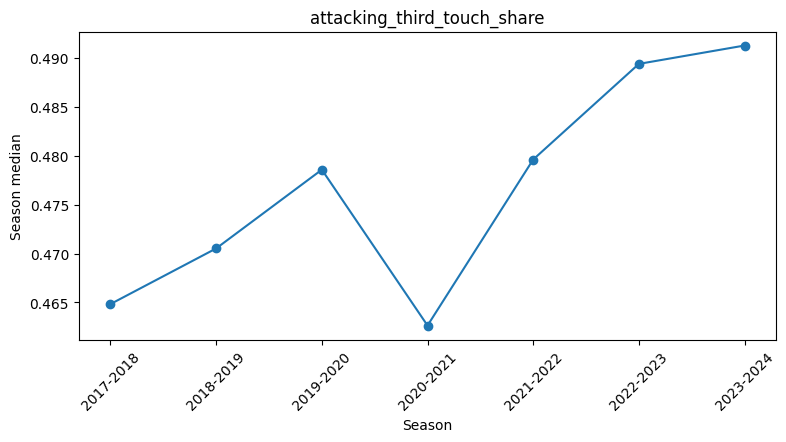

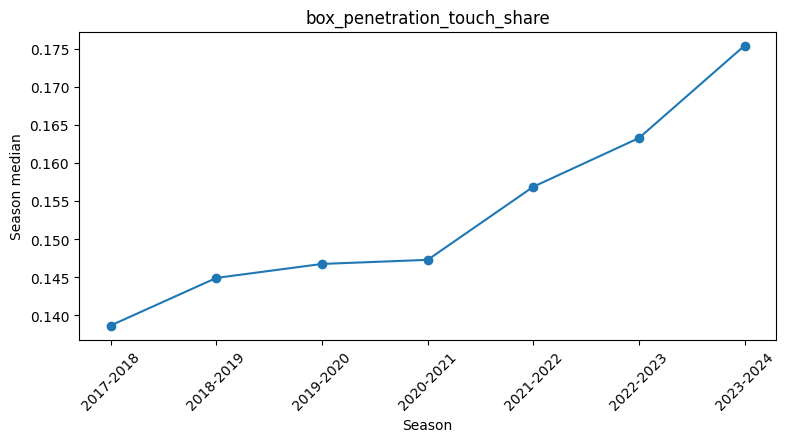

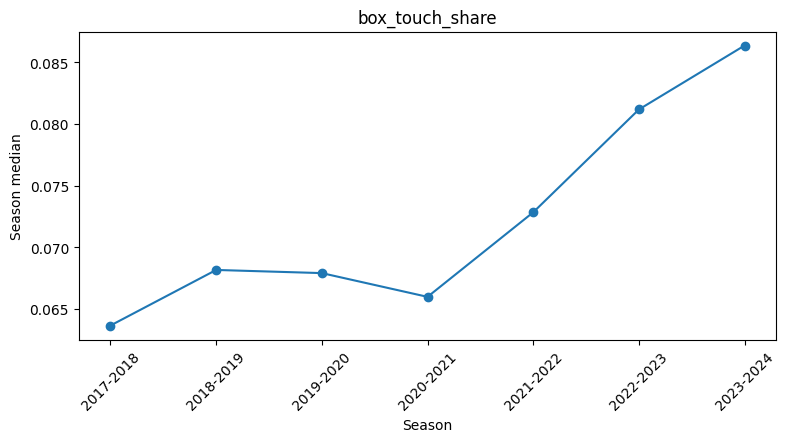

In [327]:
plot_season_medians(
    season_summary,
    territory_features
)

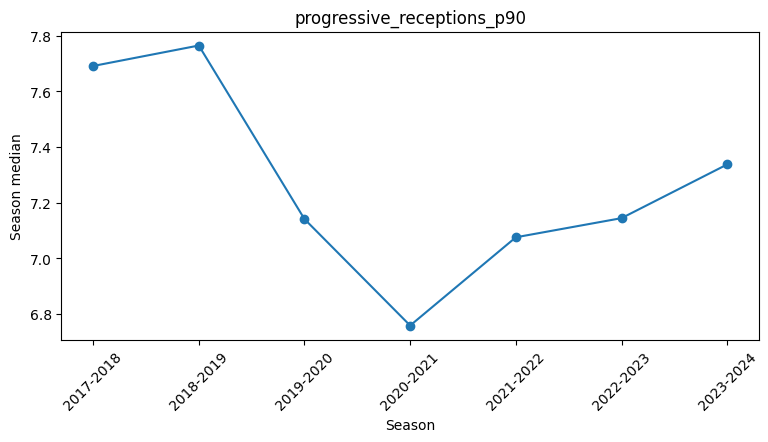

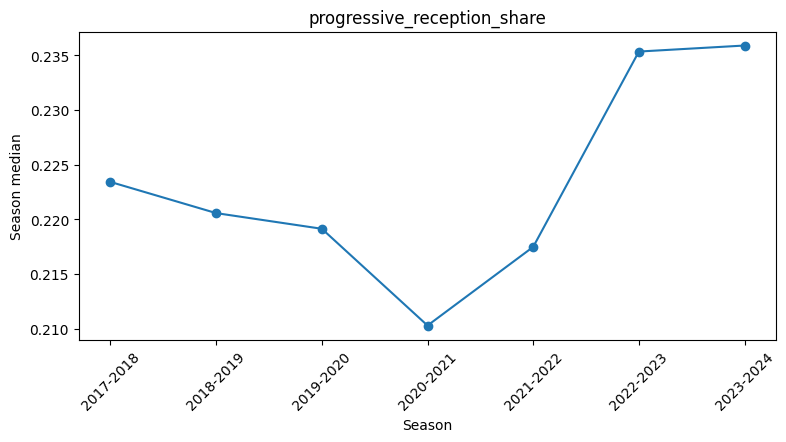

In [328]:
plot_season_medians(
    season_summary,
    receiving_features
)

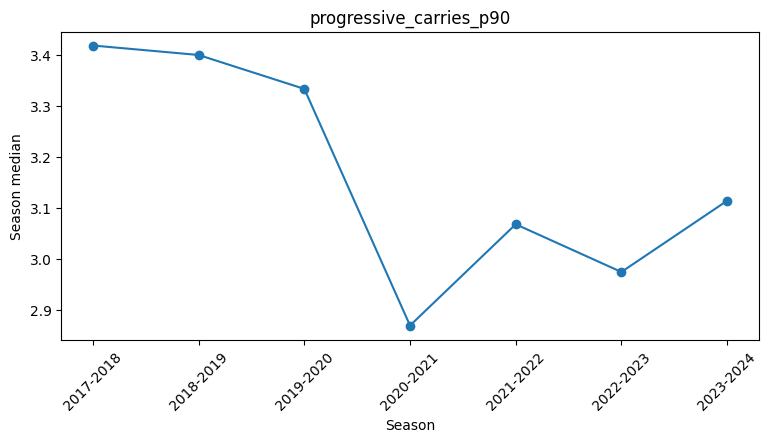

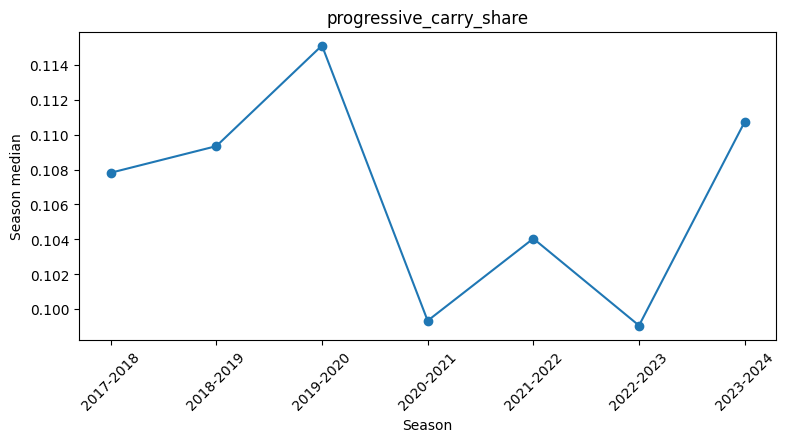

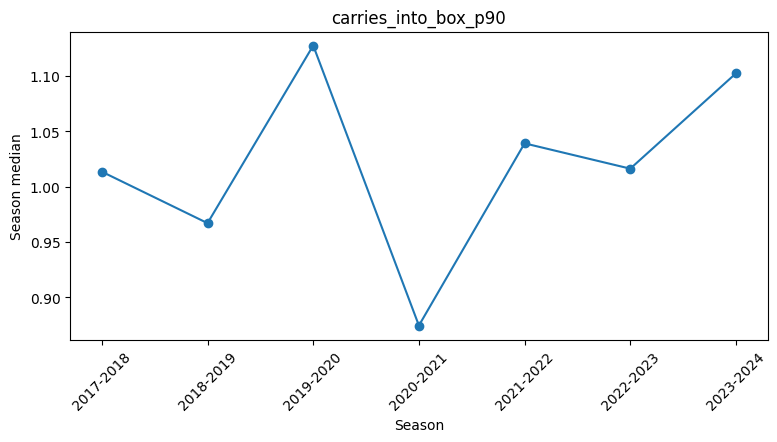

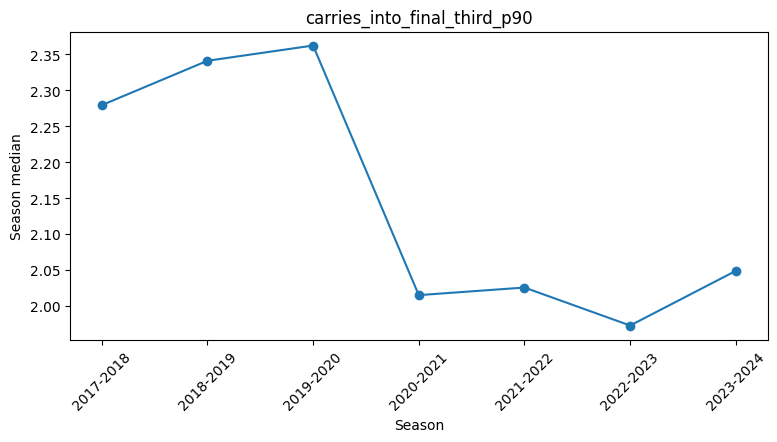

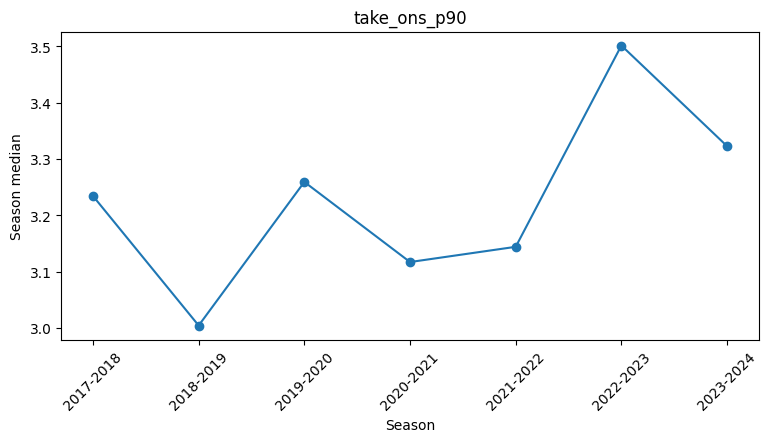

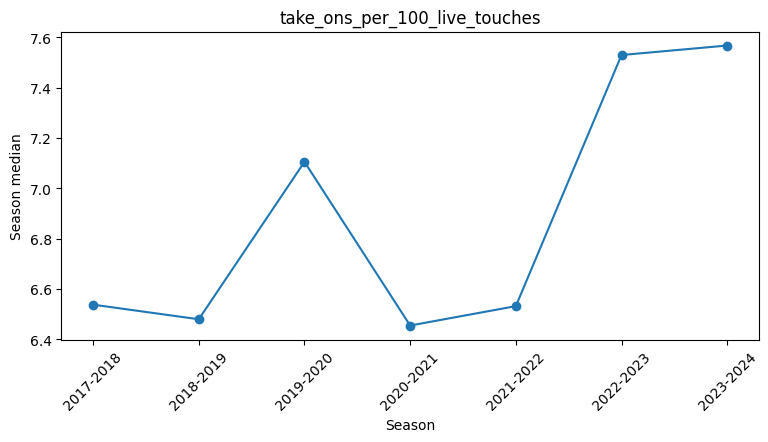

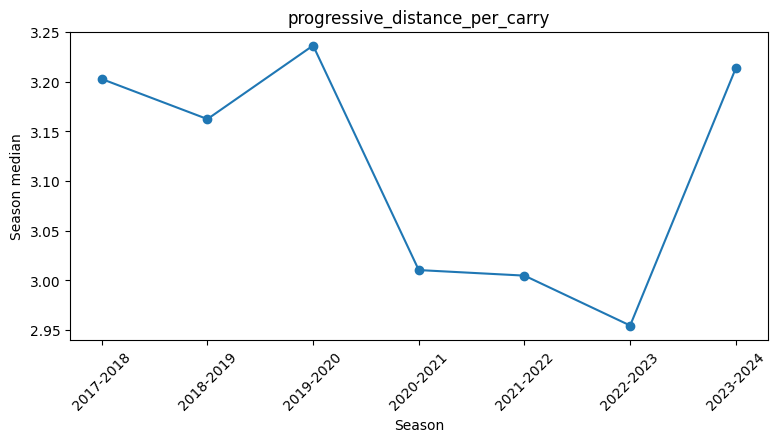

In [329]:
plot_season_medians(
    season_summary,
    carrying_features
)

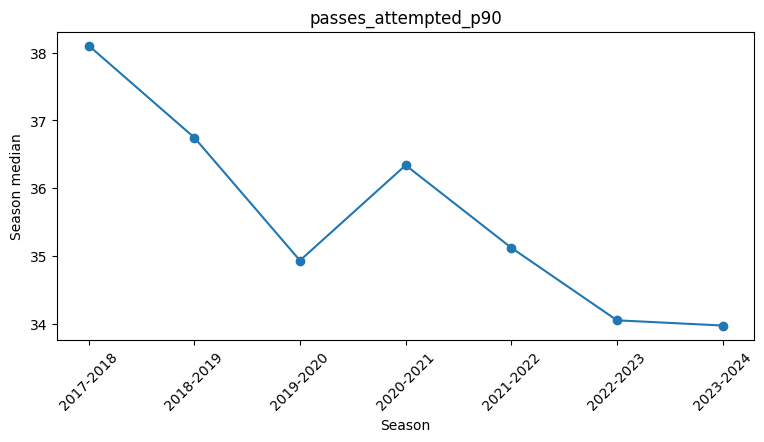

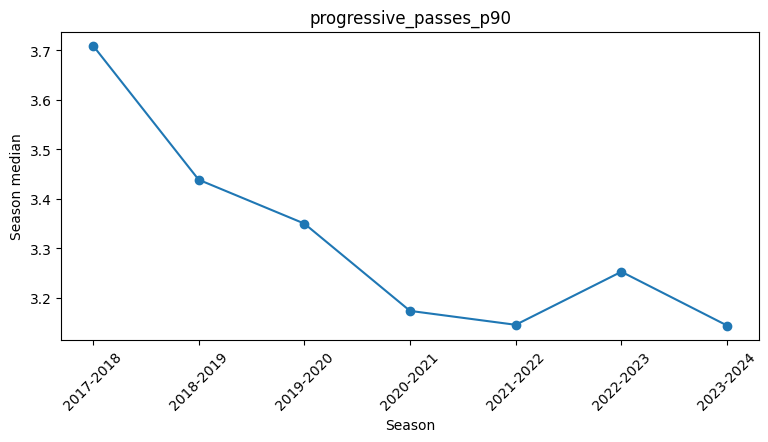

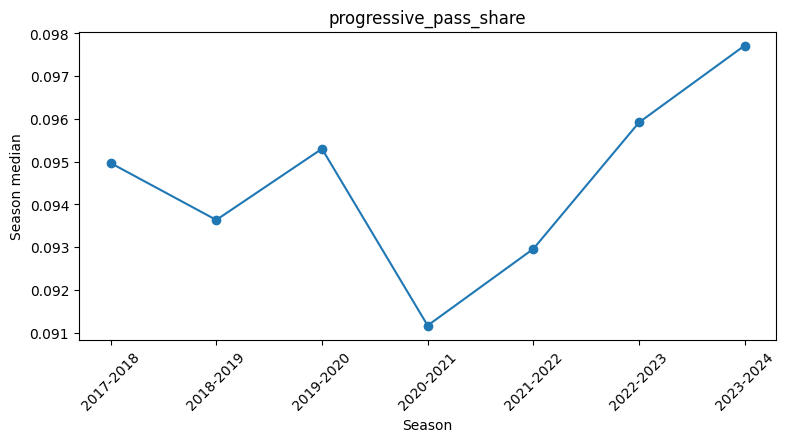

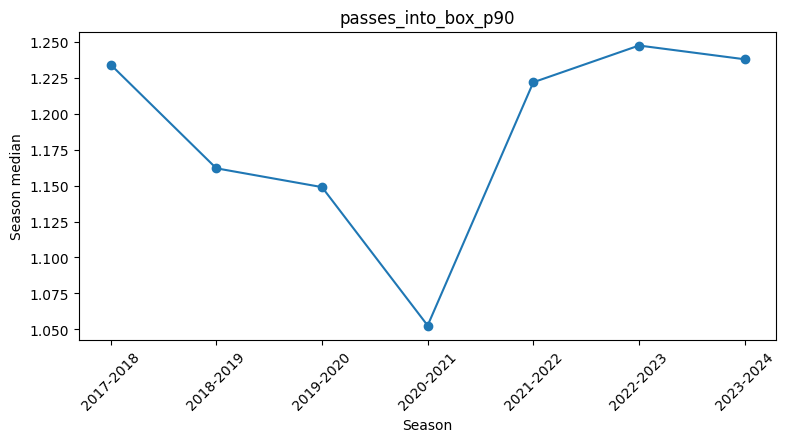

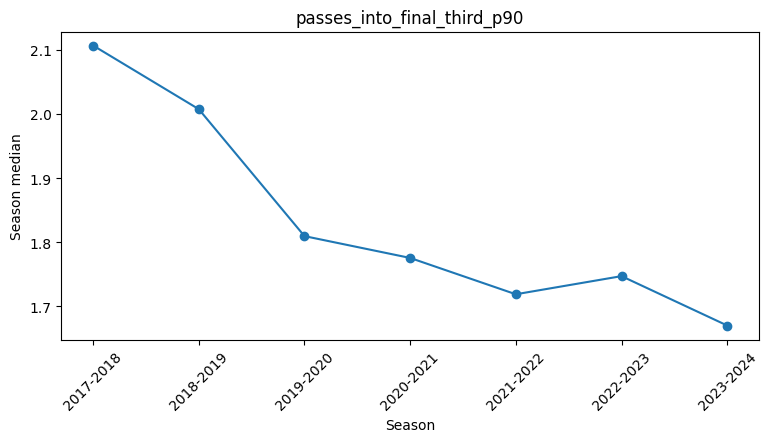

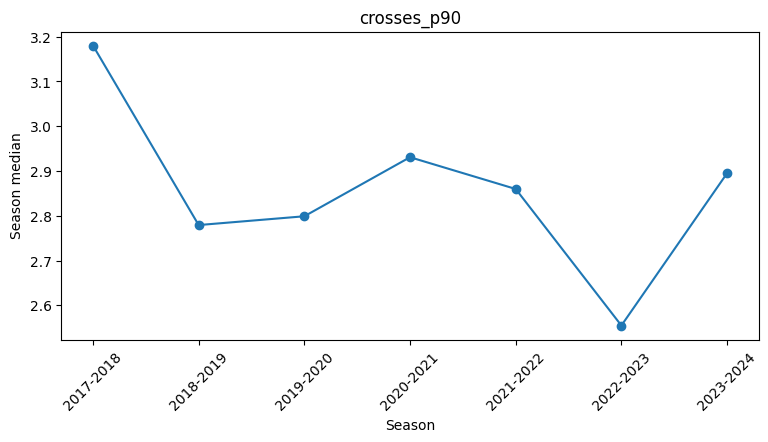

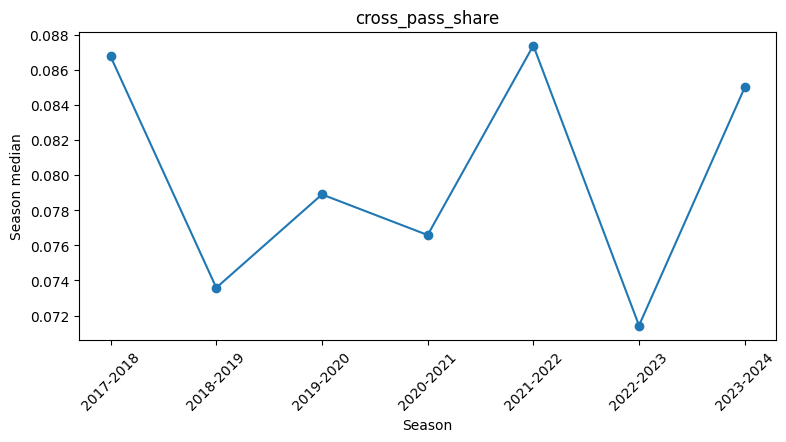

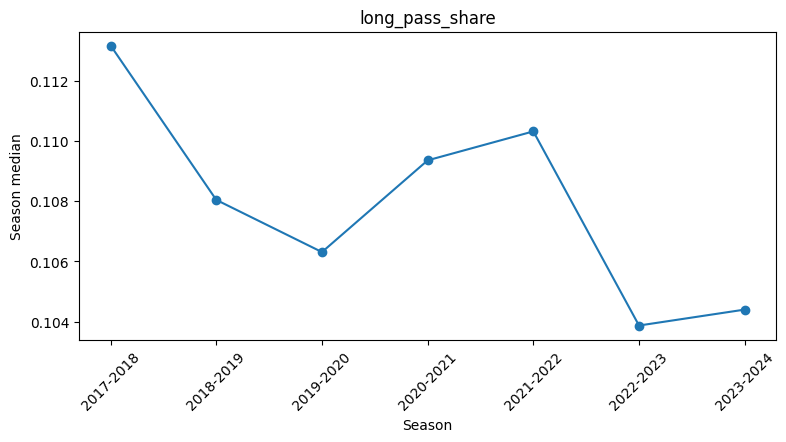

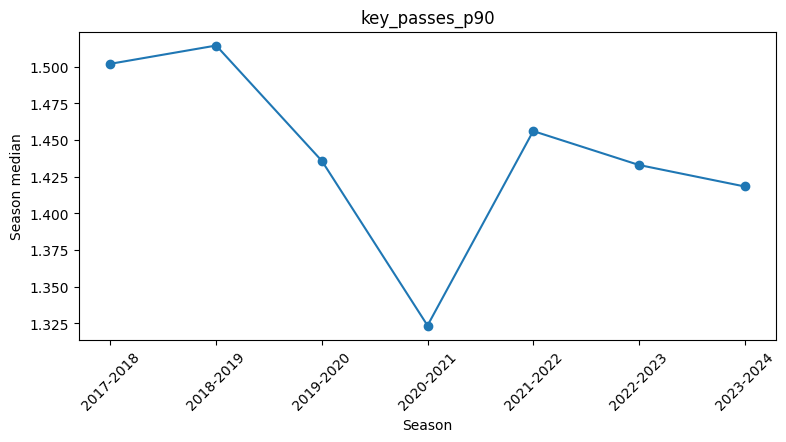

In [330]:
plot_season_medians(
    season_summary,
    passing_features
)

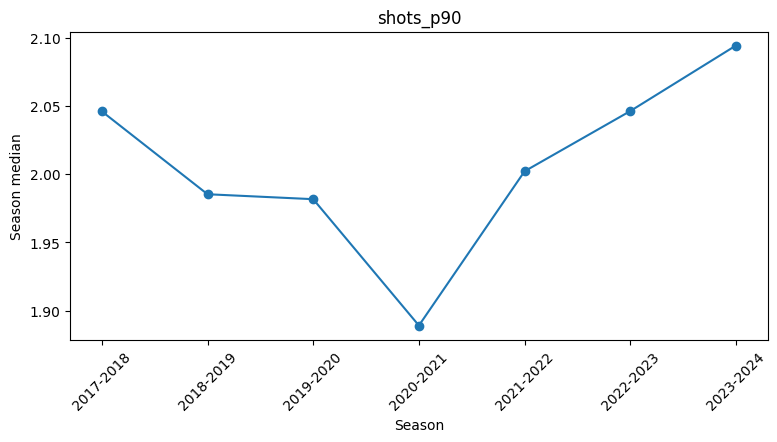

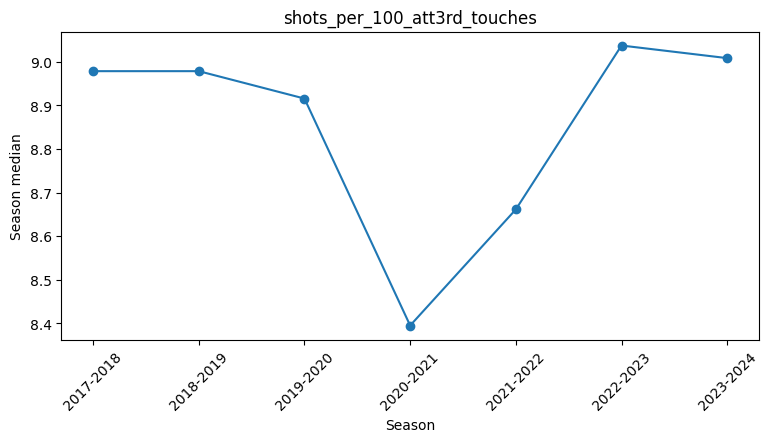

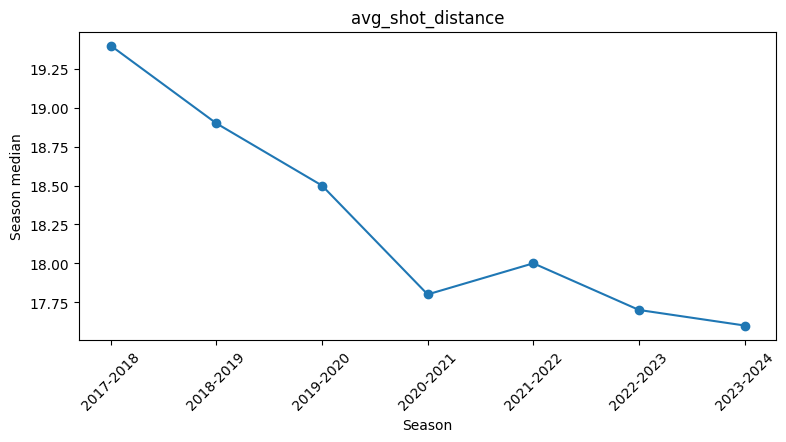

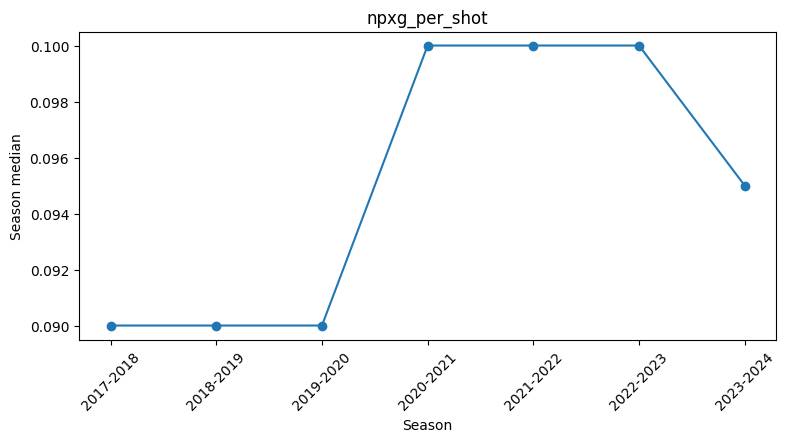

In [331]:
plot_season_medians(
    season_summary,
    shooting_features
)

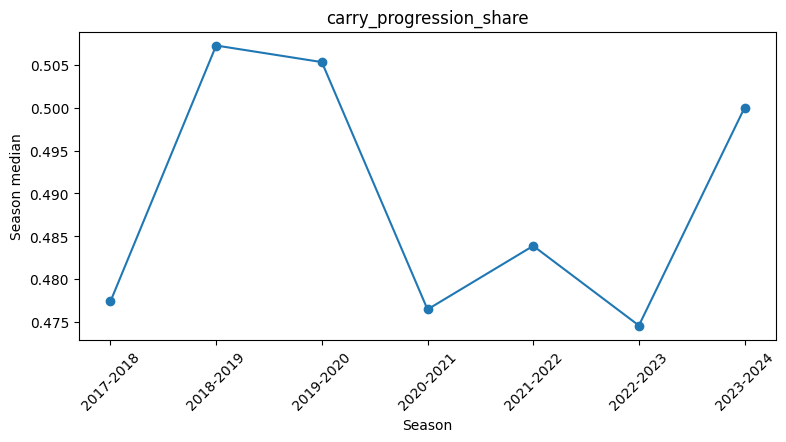

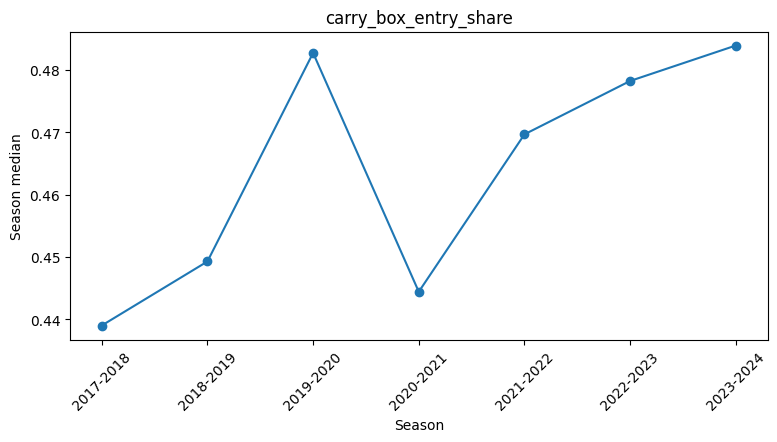

In [332]:
plot_season_medians(
    season_summary,
    choice_features
)

In [333]:
def plot_season_distribution_band(summary_df, feature):

    temp = (
        summary_df[
            summary_df["feature"] == feature
        ]
        .set_index("season")
        .reindex(season_order)
        .reset_index()
    )

    x = np.arange(len(temp))

    plt.figure(figsize=(9, 5))

    plt.plot(
        x,
        temp["median"],
        marker="o",
        label="Median"
    )

    plt.fill_between(
        x,
        temp["q25"],
        temp["q75"],
        alpha=0.2,
        label="IQR"
    )

    plt.xticks(
        x,
        temp["season"],
        rotation=45
    )

    plt.title(feature)
    plt.xlabel("Season")
    plt.ylabel(feature)
    plt.legend()

    plt.show()

In [334]:
season_change_rows = []

for feature in candidate_features:

    temp = (
        season_summary[
            season_summary["feature"] == feature
        ]
        .set_index("season")
        .reindex(season_order)
    )

    medians = temp["median"]

    for i in range(1, len(season_order)):

        previous_season = season_order[i - 1]
        current_season = season_order[i]

        prev_median = medians.loc[previous_season]
        curr_median = medians.loc[current_season]

        if pd.notna(prev_median) and prev_median != 0:
            relative_change = (
                (curr_median - prev_median) /
                abs(prev_median)
            )
        else:
            relative_change = np.nan

        season_change_rows.append({
            "feature": feature,
            "from_season": previous_season,
            "to_season": current_season,
            "previous_median": prev_median,
            "current_median": curr_median,
            "relative_median_change": relative_change
        })

season_changes = pd.DataFrame(season_change_rows)

season_changes = season_changes.merge(
    feature_registry,
    on="feature",
    how="left",
    validate="many_to_one"
)

In [335]:
display(
    season_changes.assign(
        abs_change=lambda x:
            x["relative_median_change"].abs()
    )
    .sort_values(
        "abs_change",
        ascending=False
    )
    .head(40)
)

,feature,from_season,to_season,previous_median,current_median,relative_median_change,family,status,abs_change
44,carries_into_box_p90,2019-2020,2020-2021,1.127685,0.874595,-0.224433,Carrying,Core,0.224433
113,cross_pass_share,2022-2023,2023-2024,0.071429,0.085001,0.190015,Crossing,Core,0.190015
45,carries_into_box_p90,2020-2021,2021-2022,0.874595,1.039261,0.188277,Carrying,Core,0.188277
112,cross_pass_share,2021-2022,2022-2023,0.087393,0.071429,-0.182670,Crossing,Core,0.182670
43,carries_into_box_p90,2018-2019,2019-2020,0.967123,1.127685,0.166020,Carrying,Core,0.166020
93,passes_into_box_p90,2020-2021,2021-2022,1.052632,1.221892,0.160798,Passing,Core,0.160798
64,take_ons_per_100_live_touches,2021-2022,2022-2023,6.531739,7.529412,0.152742,Dribbling,Core,0.152742
108,cross_pass_share,2017-2018,2018-2019,0.086768,0.073583,-0.151955,Crossing,Core,0.151955
50,carries_into_final_third_p90,2019-2020,2020-2021,2.362205,2.015267,-0.146870,Carrying,Secondary,0.146870
111,cross_pass_share,2020-2021,2021-2022,0.076588,0.087393,0.141069,Crossing,Core,0.141069


In [336]:
robust_shift_rows = []

for feature in candidate_features:

    temp = (
        season_summary[
            season_summary["feature"] == feature
        ]
        .set_index("season")
        .reindex(season_order)
    )

    for i in range(1, len(season_order)):

        s1 = season_order[i - 1]
        s2 = season_order[i]

        m1 = temp.loc[s1, "median"]
        m2 = temp.loc[s2, "median"]

        iqr1 = (
            temp.loc[s1, "q75"] -
            temp.loc[s1, "q25"]
        )

        iqr2 = (
            temp.loc[s2, "q75"] -
            temp.loc[s2, "q25"]
        )

        pooled_iqr = np.nanmean([
            iqr1,
            iqr2
        ])

        if (
            pd.notna(pooled_iqr) and
            pooled_iqr > 0
        ):
            robust_shift = (
                (m2 - m1) /
                pooled_iqr
            )
        else:
            robust_shift = np.nan

        robust_shift_rows.append({
            "feature": feature,
            "from_season": s1,
            "to_season": s2,
            "robust_shift": robust_shift
        })

robust_shifts = pd.DataFrame(
    robust_shift_rows
)

season_changes = season_changes.merge(
    robust_shifts,
    on=[
        "feature",
        "from_season",
        "to_season"
    ],
    how="left",
    validate="one_to_one"
)

In [337]:
display(
    season_changes.assign(
        abs_robust_shift=lambda x:
            x["robust_shift"].abs()
    )
    .sort_values(
        "abs_robust_shift",
        ascending=False
    )
    .head(40)
)

,feature,from_season,to_season,previous_median,current_median,relative_median_change,family,status,robust_shift,abs_robust_shift
38,progressive_carry_share,2019-2020,2020-2021,0.115108,0.099338,-0.137003,Carrying,Core,-0.344429,0.344429
50,carries_into_final_third_p90,2019-2020,2020-2021,2.362205,2.015267,-0.146870,Carrying,Secondary,-0.311213,0.311213
32,progressive_carries_p90,2019-2020,2020-2021,3.333333,2.869796,-0.139061,Carrying,Core,-0.310080,0.310080
44,carries_into_box_p90,2019-2020,2020-2021,1.127685,0.874595,-0.224433,Carrying,Core,-0.282116,0.282116
68,progressive_distance_per_carry,2019-2020,2020-2021,3.236314,3.010309,-0.069834,Carrying,Secondary,-0.260733,0.260733
64,take_ons_per_100_live_touches,2021-2022,2022-2023,6.531739,7.529412,0.152742,Dribbling,Core,0.249765,0.249765
93,passes_into_box_p90,2020-2021,2021-2022,1.052632,1.221892,0.160798,Passing,Core,0.228449,0.228449
71,progressive_distance_per_carry,2022-2023,2023-2024,2.954495,3.213499,0.087664,Carrying,Secondary,0.225507,0.225507
146,npxg_per_shot,2019-2020,2020-2021,0.090000,0.100000,0.111111,Shooting,Secondary,0.222222,0.222222
112,cross_pass_share,2021-2022,2022-2023,0.087393,0.071429,-0.182670,Crossing,Core,-0.218999,0.218999


In [338]:
suspected_break = season_changes[
    (season_changes["from_season"] == "2021-2022") &
    (season_changes["to_season"] == "2022-2023")
].copy()

suspected_break["abs_robust_shift"] = (
    suspected_break["robust_shift"].abs()
)

display(
    suspected_break[
        [
            "feature",
            "family",
            "status",
            "previous_median",
            "current_median",
            "relative_median_change",
            "robust_shift",
            "abs_robust_shift"
        ]
    ]
    .sort_values(
        "abs_robust_shift",
        ascending=False
    )
)

,feature,family,status,previous_median,current_median,relative_median_change,robust_shift,abs_robust_shift
64,take_ons_per_100_live_touches,Dribbling,Core,6.531739,7.529412,0.152742,0.249765,0.249765
112,cross_pass_share,Crossing,Core,0.087393,0.071429,-0.182670,-0.218999,0.218999
58,take_ons_p90,Dribbling,Core,3.144105,3.501297,0.113607,0.185279,0.185279
28,progressive_reception_share,Receiving,Core,0.217480,0.235359,0.082212,0.183297,0.183297
16,box_touch_share,Territory,Secondary,0.072848,0.081181,0.114391,0.160877,0.160877
106,crosses_p90,Crossing,Core,2.859813,2.554797,-0.106656,-0.104069,0.104069
118,long_pass_share,Passing Profile,Secondary,0.110315,0.103873,-0.058396,-0.092959,0.092959
40,progressive_carry_share,Carrying,Core,0.104046,0.099063,-0.047895,-0.087304,0.087304
136,shots_per_100_att3rd_touches,Shooting,Core,8.661417,9.037328,0.043401,0.085352,0.085352
4,attacking_third_touch_share,Territory,Core,0.479620,0.489403,0.020398,0.085095,0.085095


In [339]:
temporal_flags = suspected_break.copy()

temporal_flags["large_relative_change"] = (
    temporal_flags[
        "relative_median_change"
    ].abs() >= 0.25
)

temporal_flags["large_robust_shift"] = (
    temporal_flags[
        "robust_shift"
    ].abs() >= 0.5
)

temporal_flags["suspected_break_flag"] = (
    temporal_flags[
        [
            "large_relative_change",
            "large_robust_shift"
        ]
    ].all(axis=1)
)

display(
    temporal_flags[
        [
            "feature",
            "family",
            "status",
            "relative_median_change",
            "robust_shift",
            "large_relative_change",
            "large_robust_shift",
            "suspected_break_flag"
        ]
    ]
    .sort_values(
        "robust_shift",
        key=lambda x: x.abs(),
        ascending=False
    )
)

,feature,family,status,relative_median_change,robust_shift,large_relative_change,large_robust_shift,suspected_break_flag
64,take_ons_per_100_live_touches,Dribbling,Core,0.152742,0.249765,False,False,False
112,cross_pass_share,Crossing,Core,-0.182670,-0.218999,False,False,False
58,take_ons_p90,Dribbling,Core,0.113607,0.185279,False,False,False
28,progressive_reception_share,Receiving,Core,0.082212,0.183297,False,False,False
16,box_touch_share,Territory,Secondary,0.114391,0.160877,False,False,False
106,crosses_p90,Crossing,Core,-0.106656,-0.104069,False,False,False
118,long_pass_share,Passing Profile,Secondary,-0.058396,-0.092959,False,False,False
40,progressive_carry_share,Carrying,Core,-0.047895,-0.087304,False,False,False
136,shots_per_100_att3rd_touches,Shooting,Core,0.043401,0.085352,False,False,False
4,attacking_third_touch_share,Territory,Core,0.020398,0.085095,False,False,False


In [340]:
takeon_season_audit = (
    df.groupby("season")
    .agg(
        original_takeons_median=(
            "Take-ons Attempted",
            "median"
        ),
        donor_takeons_median=(
            "Take-Ons_Att",
            "median"
        ),
        original_takeons_mean=(
            "Take-ons Attempted",
            "mean"
        ),
        donor_takeons_mean=(
            "Take-Ons_Att",
            "mean"
        ),
        observations=(
            "player",
            "size"
        )
    )
    .reindex(season_order)
)

display(takeon_season_audit)

,original_takeons_median,donor_takeons_median,original_takeons_mean,donor_takeons_mean,observations
season,,,,,
2017-2018,67.0,67.0,74.800885,74.800885,226
2018-2019,63.5,63.5,73.113861,73.113861,202
2019-2020,68.0,68.0,74.531429,74.531429,175
2020-2021,67.0,67.0,71.678049,71.682927,205
2021-2022,63.0,63.0,69.870270,69.870270,185
2022-2023,72.0,72.0,79.910798,79.929577,213
2023-2024,71.5,71.5,80.226316,80.226316,190


In [341]:
takeon_temporal = pd.DataFrame({
    "season": df["season"],

    "original_takeons_p90":
        per90(
            df["Take-ons Attempted"],
            df["Minutes"]
        ),

    "donor_takeons_p90":
        per90(
            df["Take-Ons_Att"],
            df["Minutes"]
        )
})

In [342]:
display(
    takeon_temporal
    .groupby("season")
    [
        [
            "original_takeons_p90",
            "donor_takeons_p90"
        ]
    ]
    .median()
    .reindex(season_order)
)

,original_takeons_p90,donor_takeons_p90
season,,
2017-2018,3.234292,3.234292
2018-2019,3.004437,3.004437
2019-2020,3.259259,3.259259
2020-2021,3.117097,3.117647
2021-2022,3.144105,3.144105
2022-2023,3.501297,3.501297
2023-2024,3.322719,3.322719


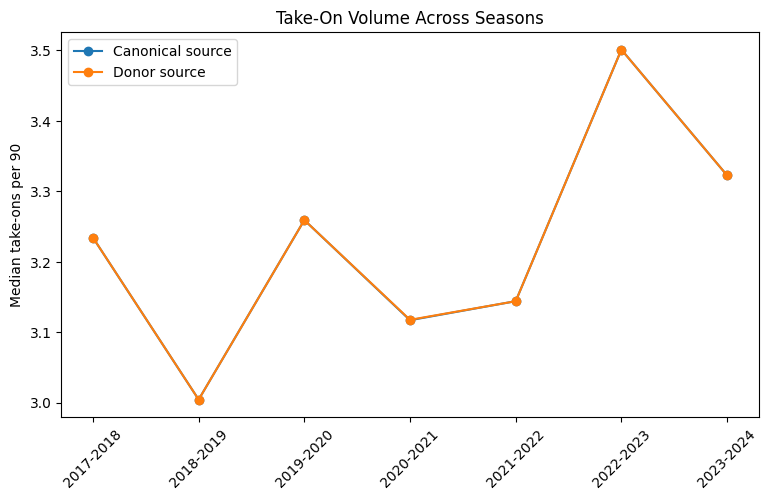

In [343]:
takeon_source_medians = (
    takeon_temporal
    .groupby("season")
    [
        [
            "original_takeons_p90",
            "donor_takeons_p90"
        ]
    ]
    .median()
    .reindex(season_order)
)

plt.figure(figsize=(9, 5))

plt.plot(
    season_order,
    takeon_source_medians[
        "original_takeons_p90"
    ],
    marker="o",
    label="Canonical source"
)

plt.plot(
    season_order,
    takeon_source_medians[
        "donor_takeons_p90"
    ],
    marker="o",
    label="Donor source"
)

plt.xticks(rotation=45)
plt.ylabel("Median take-ons per 90")
plt.title(
    "Take-On Volume Across Seasons"
)
plt.legend()

plt.show()

In [344]:
takeon_quality_temporal = pd.DataFrame({
    "season": df["season"],

    "canonical_success_pct":
        pd.to_numeric(
            df["Successful Take-ons %"],
            errors="coerce"
        ),

    "donor_success_pct":
        pd.to_numeric(
            df["Take-Ons_Succ%"],
            errors="coerce"
        ),

    "canonical_tackled_pct":
        pd.to_numeric(
            df["Tackled During Take-on %"],
            errors="coerce"
        ),

    "donor_tackled_pct":
        pd.to_numeric(
            df["Take-Ons_Tkld%"],
            errors="coerce"
        )
})

In [345]:
display(
    takeon_quality_temporal
    .groupby("season")
    .median()
    .reindex(season_order)
)

,canonical_success_pct,donor_success_pct,canonical_tackled_pct,donor_tackled_pct
season,,,,
2017-2018,56.9,56.9,42.95,42.95
2018-2019,53.0,53.0,46.45,46.45
2019-2020,56.3,56.3,43.60,43.6
2020-2021,54.4,54.4,45.60,45.6
2021-2022,51.3,51.3,48.80,48.8
2022-2023,42.5,42.5,45.50,45.5
2023-2024,41.8,41.8,48.05,48.05


In [346]:
persistent_shift_rows = []

for feature in candidate_features:

    temp = (
        season_summary[
            season_summary["feature"] == feature
        ]
        .set_index("season")
    )

    m21 = temp.loc[
        "2021-2022",
        "median"
    ]

    m22 = temp.loc[
        "2022-2023",
        "median"
    ]

    m23 = temp.loc[
        "2023-2024",
        "median"
    ]

    pre_iqr = (
        temp.loc[
            "2021-2022",
            "q75"
        ]
        -
        temp.loc[
            "2021-2022",
            "q25"
        ]
    )

    if pre_iqr > 0:
        shift_22 = (
            (m22 - m21) /
            pre_iqr
        )

        shift_23 = (
            (m23 - m21) /
            pre_iqr
        )
    else:
        shift_22 = np.nan
        shift_23 = np.nan

    persistent_shift_rows.append({
        "feature": feature,
        "2021_22_median": m21,
        "2022_23_median": m22,
        "2023_24_median": m23,
        "shift_2022_23_vs_pre": shift_22,
        "shift_2023_24_vs_pre": shift_23
    })

persistent_shift = pd.DataFrame(
    persistent_shift_rows
)

persistent_shift = persistent_shift.merge(
    feature_registry,
    on="feature",
    how="left"
)

In [347]:
display(
    persistent_shift.assign(
        persistent_strength=lambda x:
            np.minimum(
                x[
                    "shift_2022_23_vs_pre"
                ].abs(),
                x[
                    "shift_2023_24_vs_pre"
                ].abs()
            )
    )
    .sort_values(
        "persistent_strength",
        ascending=False
    )
    .head(20)
)

,feature,2021_22_median,2022_23_median,2023_24_median,shift_2022_23_vs_pre,shift_2023_24_vs_pre,family,status,persistent_strength
10,take_ons_per_100_live_touches,6.531739,7.529412,7.567185,0.275767,0.286208,Dribbling,Core,0.275767
4,progressive_reception_share,0.217480,0.235359,0.235910,0.187406,0.193184,Receiving,Core,0.187406
2,box_touch_share,0.072848,0.081181,0.086364,0.172524,0.279835,Territory,Secondary,0.172524
9,take_ons_p90,3.144105,3.501297,3.322719,0.207728,0.103875,Dribbling,Core,0.103875
0,attacking_third_touch_share,0.479620,0.489403,0.491282,0.095002,0.113248,Territory,Core,0.095002
6,progressive_carry_share,0.104046,0.099063,0.110735,-0.086211,0.115723,Carrying,Core,0.086211
14,progressive_pass_share,0.092958,0.095915,0.097713,0.085931,0.138203,Passing,Core,0.085931
1,box_penetration_touch_share,0.156891,0.163291,0.175440,0.083565,0.242205,Territory,Core,0.083565
19,long_pass_share,0.110315,0.103873,0.104402,-0.090982,-0.083517,Passing Profile,Secondary,0.083517
23,avg_shot_distance,18.000000,17.700000,17.600000,-0.076923,-0.102564,Shooting,Core,0.076923


## Interpreting Temporal Shifts

Seasonal distribution changes are not automatically treated as data problems.

A genuine football trend may produce gradual movement in features such as:

- crossing;
- shot selection;
- progression;
- positional involvement.

A possible measurement-definition problem is more likely when:

1. a large change occurs abruptly between adjacent seasons;
2. the new level persists afterward;
3. related variables shift simultaneously;
4. the change is consistent with known concerns about the underlying statistic;
5. football interpretation alone does not provide a convincing explanation.

Any eventual adjustment will therefore target specific unstable variables rather than automatically standardizing every feature by season.

## 10B.13 Investigating the 2020-21 Dip

Visual inspection reveals an unexpected pattern across several unrelated attacking features.

A number of measures decline during 2020-21 before recovering in subsequent seasons, including measures of:

- shooting;
- passing progression;
- box delivery;
- carrying progression;
- box penetration.

Because the pattern appears across multiple behavioural families rather than a single statistic, it is less consistent with an isolated feature-definition change.

However, the shift could still arise from:

- genuine season-level football conditions;
- changes in the league composition of the winger sample;
- changes in the types of players classified as wingers;
- differences in which players meet the minutes threshold.

Two additional diagnostics are therefore performed:

1. league-specific seasonal trends;
2. within-player adjacent-season comparisons.

These tests help distinguish a broad season effect from changes in sample composition.

In [348]:
dip_features = [
    "progressive_carries_p90",
    "carries_into_box_p90",
    "progressive_pass_share",
    "passes_into_box_p90",
    "shots_p90",
    "shots_per_100_att3rd_touches",
    "carry_box_entry_share"
]

In [349]:
league_season_medians = (
    feature_df
    .groupby(["comp", "season"])[dip_features]
    .median()
    .reset_index()
)

display(league_season_medians.head())

,comp,season,progressive_carries_p90,carries_into_box_p90,progressive_pass_share,passes_into_box_p90,shots_p90,shots_per_100_att3rd_touches,carry_box_entry_share
0,Bundesliga,2017-2018,3.238150,1.083405,0.094270,1.251086,2.102804,8.222222,0.428571
1,Bundesliga,2018-2019,2.992228,1.009927,0.094388,1.151079,1.993186,9.508197,0.432432
2,Bundesliga,2019-2020,3.296860,1.223733,0.081129,0.996016,2.127031,10.049020,0.534884
3,Bundesliga,2020-2021,2.925948,1.072977,0.094563,1.149425,2.243497,9.688013,0.442623
4,Bundesliga,2021-2022,2.752866,0.918965,0.095493,1.154260,2.006465,10.031339,0.411825


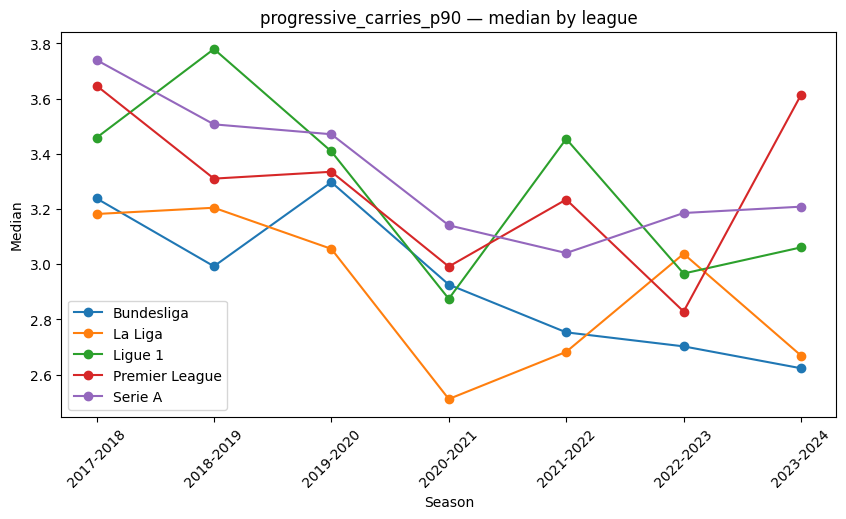

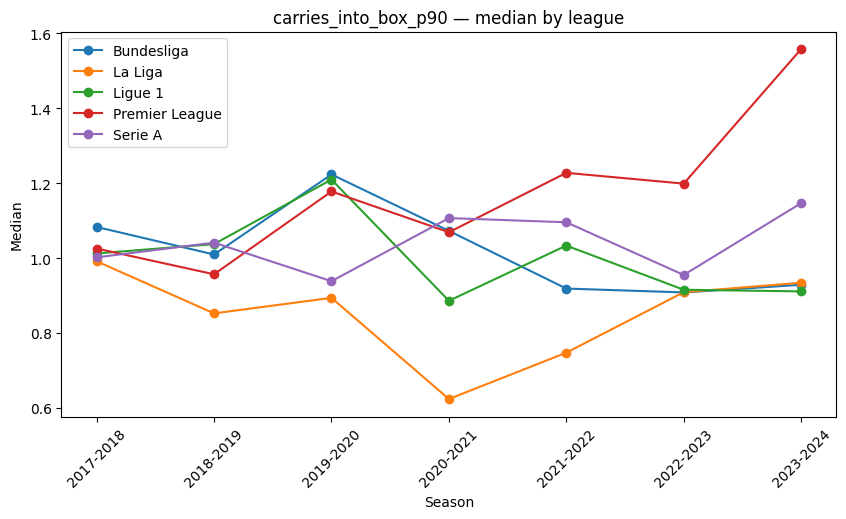

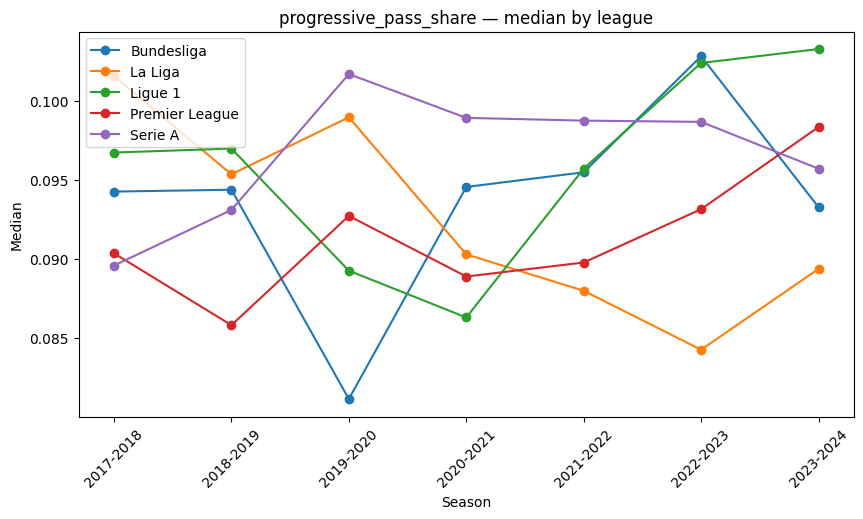

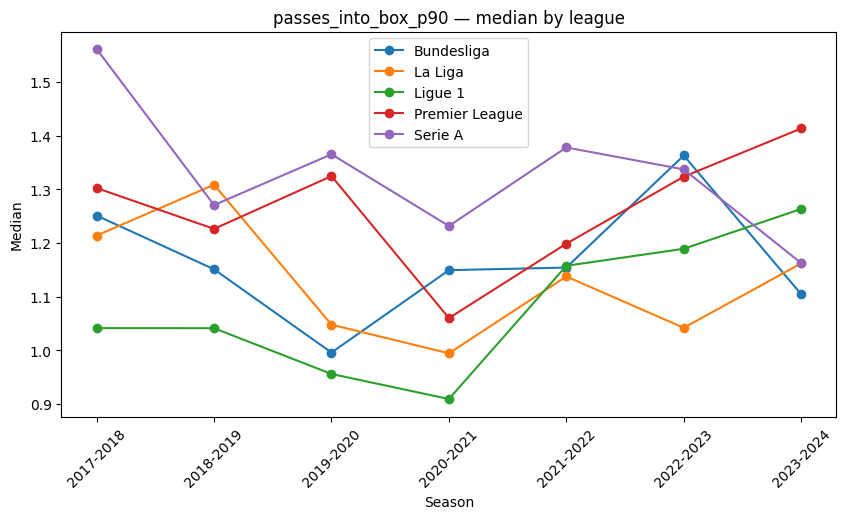

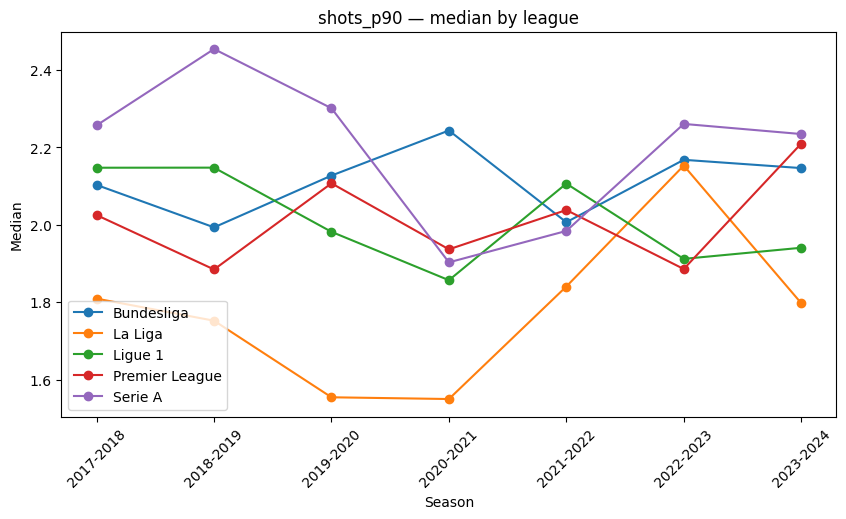

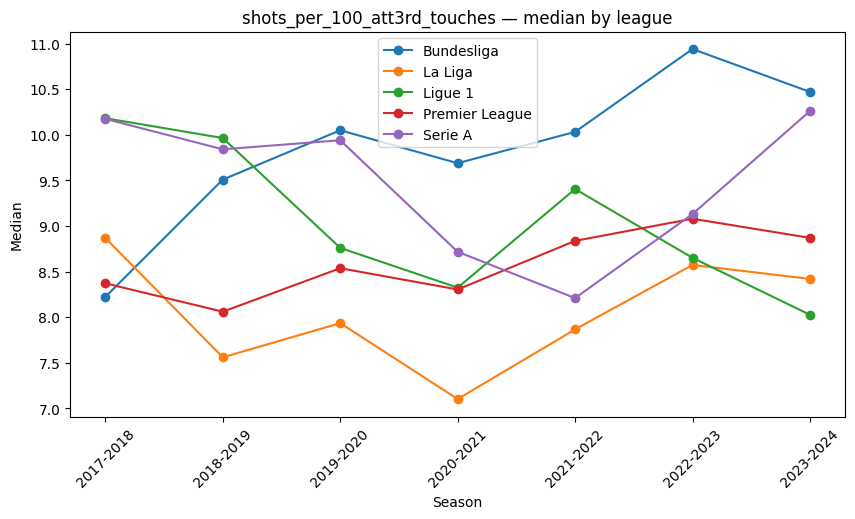

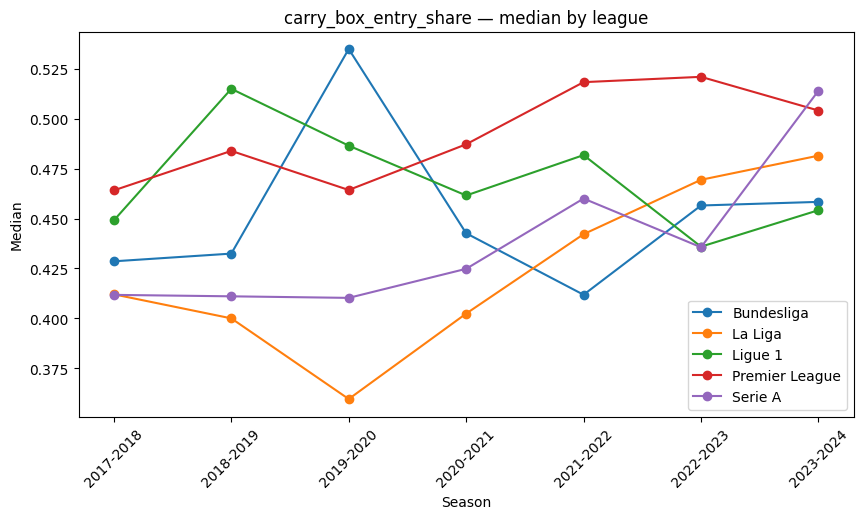

In [350]:
for feature in dip_features:

    plt.figure(figsize=(10, 5))

    for league in sorted(feature_df["comp"].dropna().unique()):

        temp = (
            league_season_medians[
                league_season_medians["comp"] == league
            ]
            .set_index("season")
            .reindex(season_order)
            .reset_index()
        )

        plt.plot(
            temp["season"],
            temp[feature],
            marker="o",
            label=league
        )

    plt.title(f"{feature} — median by league")
    plt.xlabel("Season")
    plt.ylabel("Median")
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

In [351]:
panel_source = feature_df[
    [
        "player_id",
        "player",
        "season",
        "Minutes"
    ] + dip_features
].copy()

In [352]:
def weighted_mean(group, col):
    values = group[col]
    weights = group["Minutes"]

    valid = values.notna() & weights.notna()

    if valid.sum() == 0:
        return np.nan

    return np.average(
        values[valid],
        weights=weights[valid]
    )

In [353]:
panel_rows = []

for (player_id, season), group in panel_source.groupby(
    ["player_id", "season"]
):

    row = {
        "player_id": player_id,
        "player": group["player"].iloc[0],
        "season": season,
        "Minutes": group["Minutes"].sum()
    }

    for feature in dip_features:
        row[feature] = weighted_mean(
            group,
            feature
        )

    panel_rows.append(row)

player_season_panel = pd.DataFrame(panel_rows)

print(player_season_panel.shape)

display(player_season_panel.head())

(1395, 11)


,player_id,player,season,Minutes,progressive_carries_p90,carries_into_box_p90,progressive_pass_share,passes_into_box_p90,shots_p90,shots_per_100_att3rd_touches,carry_box_entry_share
0,Aaron Lennon_1987,Aaron Lennon,2018-2019,1215,1.555556,0.444444,0.058632,0.444444,0.296296,2.515723,0.500000
1,Aaron Lennon_1987,Aaron Lennon,2021-2022,1551,2.205029,1.160542,0.049738,0.232108,0.696325,4.938272,0.833333
2,Abdallah Sima_2001,Abdallah Sima,2022-2023,1836,1.862745,0.833333,0.056150,0.294118,1.911765,13.879004,0.739130
3,Abde Ezzalzouli_2001,Abde Ezzalzouli,2022-2023,1504,5.565160,2.692819,0.080146,1.436170,2.393617,8.456660,0.652174
4,Adam Armstrong_1997,Adam Armstrong,2022-2023,1335,2.629213,0.741573,0.052980,0.674157,1.685393,11.261261,0.523810


In [354]:
pre = (
    player_season_panel[
        player_season_panel["season"] == "2019-2020"
    ]
    .set_index("player_id")
)

covid = (
    player_season_panel[
        player_season_panel["season"] == "2020-2021"
    ]
    .set_index("player_id")
)

common_players = pre.index.intersection(
    covid.index
)

print(
    "Players present in both seasons:",
    len(common_players)
)

Players present in both seasons: 90


In [355]:
paired_changes_1920_2021 = []

for feature in dip_features:

    diff = (
        covid.loc[common_players, feature]
        -
        pre.loc[common_players, feature]
    )

    paired_changes_1920_2021.append({
        "feature": feature,
        "players": diff.notna().sum(),
        "median_change": diff.median(),
        "mean_change": diff.mean(),
        "pct_players_decreasing":
            (diff < 0).mean() * 100
    })

paired_changes_1920_2021 = pd.DataFrame(
    paired_changes_1920_2021
)

display(paired_changes_1920_2021)

,feature,players,median_change,mean_change,pct_players_decreasing
0,progressive_carries_p90,90,-0.477469,-0.467984,74.444444
1,carries_into_box_p90,90,-0.199113,-0.211544,67.777778
2,progressive_pass_share,90,-0.005069,-0.004024,61.111111
3,passes_into_box_p90,90,-0.033192,-0.054880,54.444444
4,shots_p90,90,-0.230305,-0.161388,63.333333
5,shots_per_100_att3rd_touches,90,-0.690748,-0.543212,57.777778
6,carry_box_entry_share,90,-0.039585,-0.025298,55.555556


In [356]:
paired_season_rows = []

for i in range(1, len(season_order)):

    previous_season = season_order[i - 1]
    current_season = season_order[i]

    previous = (
        player_season_panel[
            player_season_panel["season"] == previous_season
        ]
        .set_index("player_id")
    )

    current = (
        player_season_panel[
            player_season_panel["season"] == current_season
        ]
        .set_index("player_id")
    )

    common = previous.index.intersection(
        current.index
    )

    for feature in dip_features:

        diff = (
            current.loc[common, feature]
            -
            previous.loc[common, feature]
        )

        paired_season_rows.append({
            "feature": feature,
            "from_season": previous_season,
            "to_season": current_season,
            "common_players": len(common),
            "valid_pairs": diff.notna().sum(),
            "median_change": diff.median(),
            "pct_players_decreasing":
                (diff < 0).mean() * 100
        })

paired_season_changes = pd.DataFrame(
    paired_season_rows
)

In [357]:
display(
    paired_season_changes[
        paired_season_changes["to_season"]
        == "2020-2021"
    ]
)

,feature,from_season,to_season,common_players,valid_pairs,median_change,pct_players_decreasing
14,progressive_carries_p90,2019-2020,2020-2021,90,90,-0.477469,74.444444
15,carries_into_box_p90,2019-2020,2020-2021,90,90,-0.199113,67.777778
16,progressive_pass_share,2019-2020,2020-2021,90,90,-0.005069,61.111111
17,passes_into_box_p90,2019-2020,2020-2021,90,90,-0.033192,54.444444
18,shots_p90,2019-2020,2020-2021,90,90,-0.230305,63.333333
19,shots_per_100_att3rd_touches,2019-2020,2020-2021,90,90,-0.690748,57.777778
20,carry_box_entry_share,2019-2020,2020-2021,90,90,-0.039585,55.555556


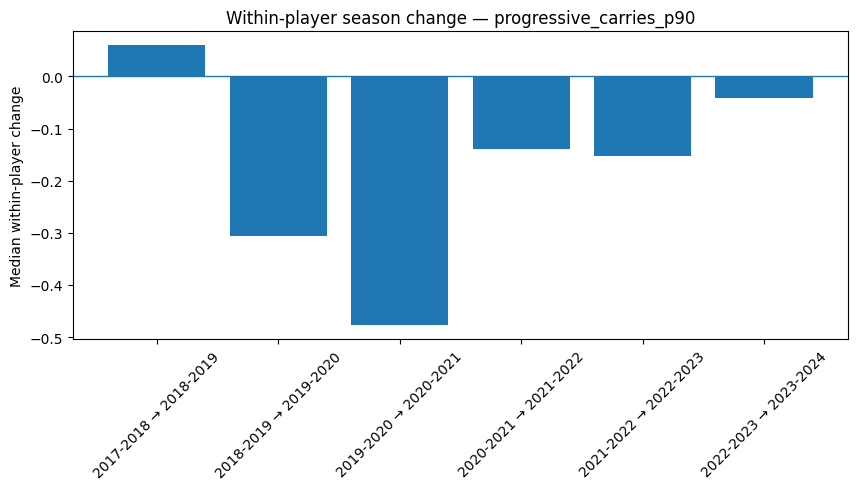

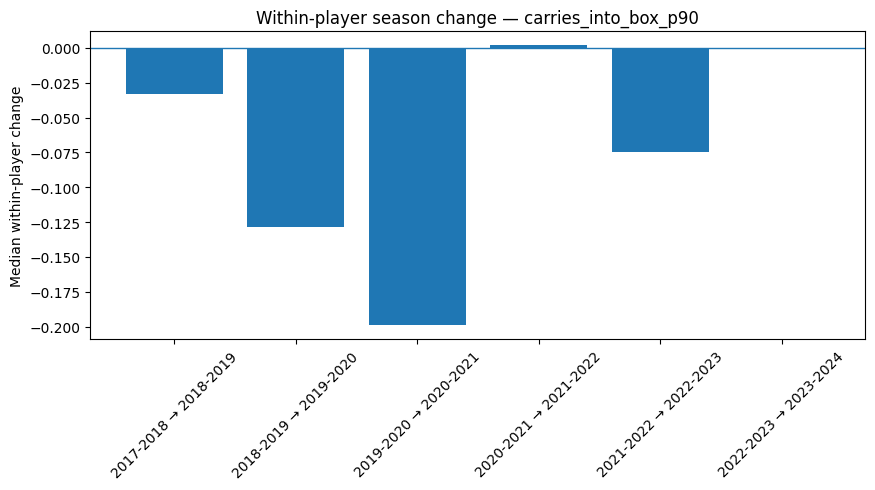

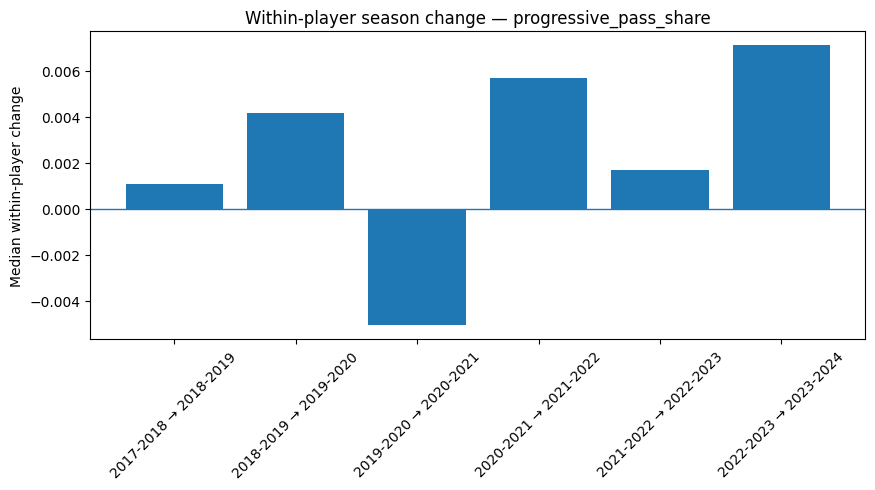

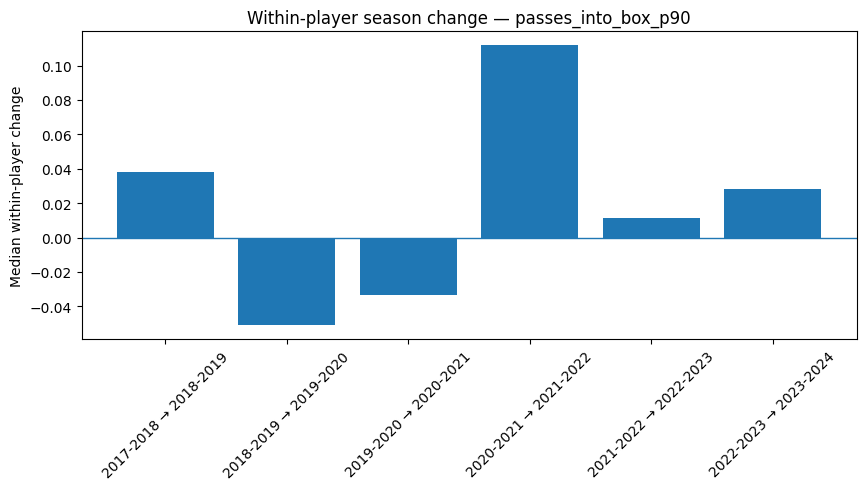

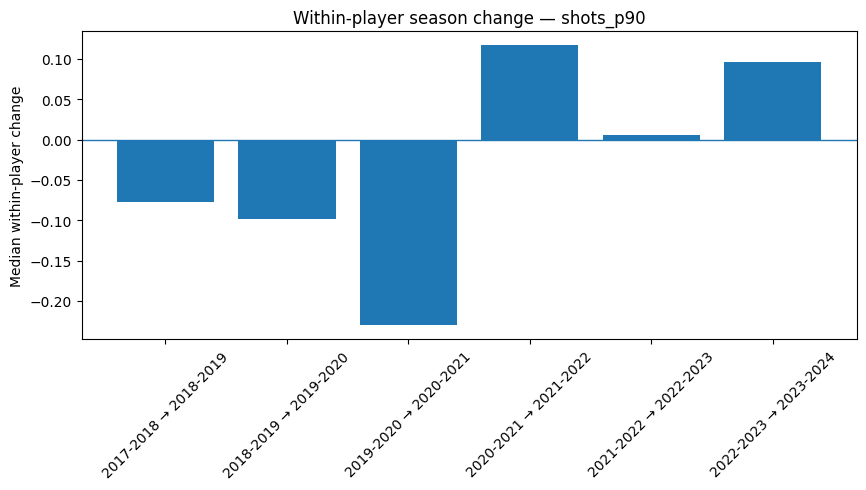

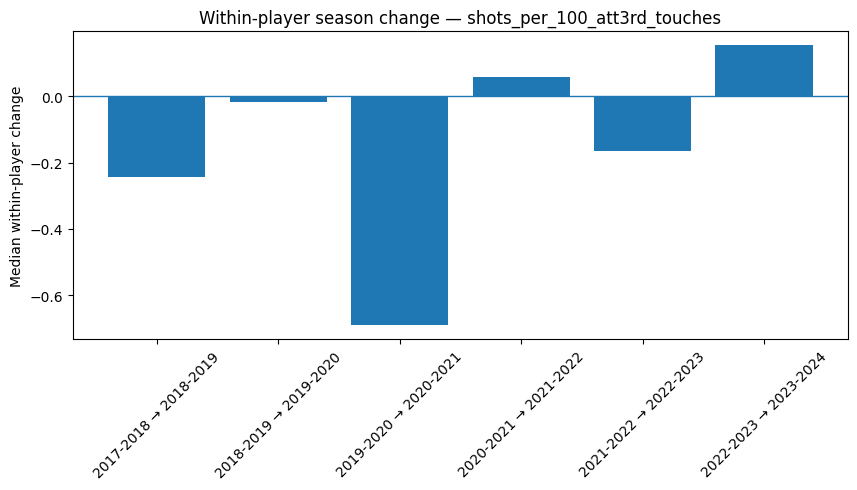

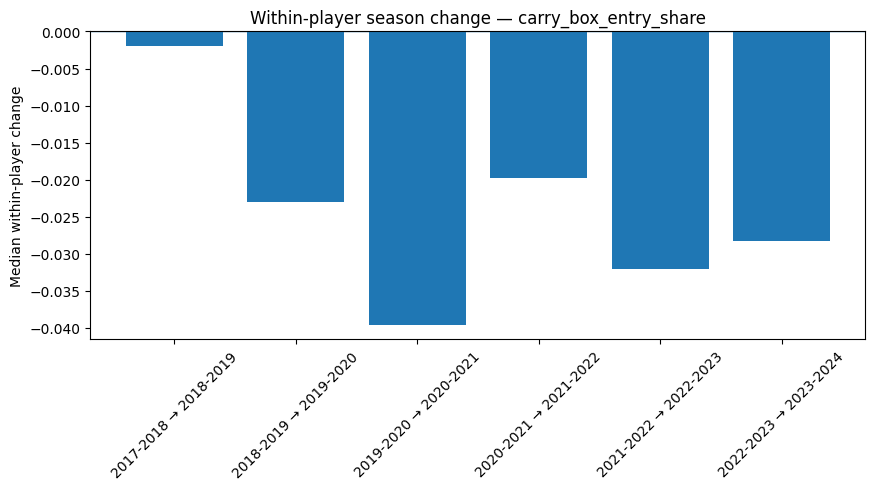

In [358]:
for feature in dip_features:

    temp = paired_season_changes[
        paired_season_changes["feature"] == feature
    ].copy()

    temp["transition"] = (
        temp["from_season"]
        + " → "
        + temp["to_season"]
    )

    plt.figure(figsize=(10, 4))

    plt.bar(
        temp["transition"],
        temp["median_change"]
    )

    plt.axhline(
        0,
        linewidth=1
    )

    plt.title(
        f"Within-player season change — {feature}"
    )

    plt.ylabel("Median within-player change")
    plt.xticks(rotation=45)

    plt.show()

### Interpretation of the 2020-21 Distribution Shift

Several attacking features showed lower aggregate medians during the 2020-21 season.

To determine whether this reflected sample composition or a possible measurement discontinuity, two additional diagnostics were performed:

1. season-level distributions were compared separately across the five leagues;
2. adjacent-season changes were calculated only for players appearing in both seasons.

The decline remained visible across multiple leagues and, for several features, within the same players.

The clearest examples included progressive carrying and shooting propensity. These movements occurred across conceptually different attacking behaviours rather than being isolated to one statistical definition.

The evidence therefore does not support treating the 2020-21 pattern as a simple provider-definition break.

Instead, it is retained as observed season-level football variation.

No correction, exclusion or season-specific normalization is applied.

The within-player comparison is not treated as a perfect causal control because players may change clubs, roles, managers and tactical environments between seasons. It is used only as supporting evidence that the aggregate shift is not explained solely by changes in sample composition.

### Temporal Variation vs Measurement Instability

Three distinct forms of temporal behaviour were observed:

- **broad seasonal shifts**, such as the 2020-21 decline across several attacking behaviours;
- **gradual long-term trends**, such as changes in average shot distance;
- **potential metric-specific discontinuities**, which require separate investigation.

Only the third category would justify statistical correction for historical comparability.

Genuine season-level or long-term football variation is preserved in the dataset.

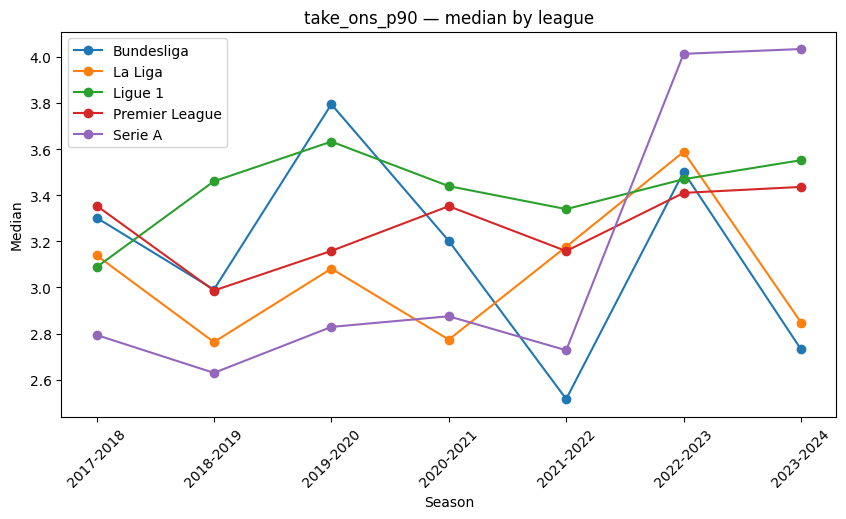

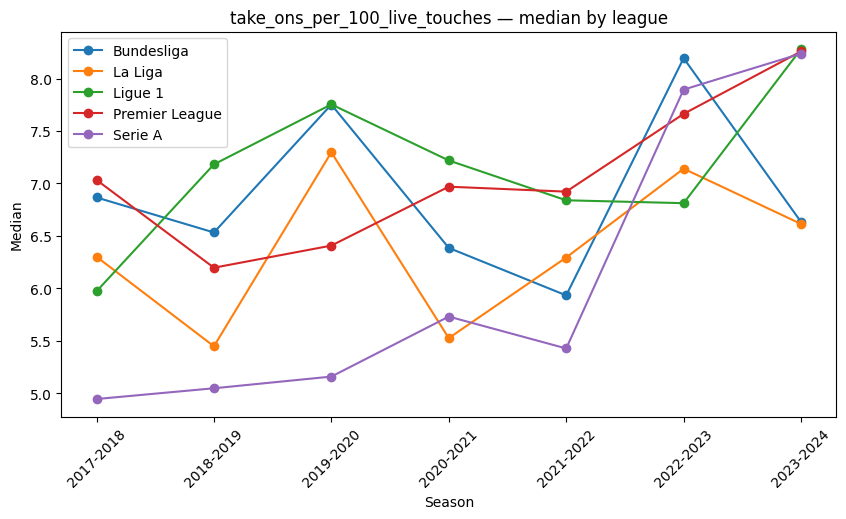

In [359]:
takeon_league_season = (
    feature_df
    .groupby(["comp", "season"])
    [
        [
            "take_ons_p90",
            "take_ons_per_100_live_touches"
        ]
    ]
    .median()
    .reset_index()
)

for feature in [
    "take_ons_p90",
    "take_ons_per_100_live_touches"
]:

    plt.figure(figsize=(10, 5))

    for league in sorted(
        feature_df["comp"].dropna().unique()
    ):

        temp = (
            takeon_league_season[
                takeon_league_season["comp"] == league
            ]
            .set_index("season")
            .reindex(season_order)
            .reset_index()
        )

        plt.plot(
            temp["season"],
            temp[feature],
            marker="o",
            label=league
        )

    plt.title(f"{feature} — median by league")
    plt.xlabel("Season")
    plt.ylabel("Median")
    plt.xticks(rotation=45)
    plt.legend()

    plt.show()

# 11. Correlation and Redundancy Audit

The candidate pool intentionally contains multiple representations of related behaviours.

Examples include:

- attacking-third involvement and box involvement;
- progressive carrying and final-third carrying;
- progressive passing and final-third passing;
- action volume and action propensity;
- shooting volume and shooting propensity.

This redundancy was preserved during feature construction so that feature selection would not be based solely on intuition.

At this stage, the objective is to identify variables that provide substantially overlapping information.

Redundancy matters because highly correlated features can unintentionally **overweight a single behavioural dimension** in later distance-based analysis.

For example, if three nearly equivalent carrying features are included while only one receiving feature is included, player similarity may become disproportionately driven by carrying behaviour.

Correlation is therefore used as a diagnostic for redundancy rather than as an automatic feature-removal rule.

Feature decisions combine:

1. statistical similarity;
2. football interpretation;
3. conceptual uniqueness;
4. robustness and data quality.

## 11.1 Correlation Strategy

Two correlation measures are examined.

### Spearman correlation

Spearman correlation evaluates whether two features move monotonically together without requiring a linear relationship.

It is used as the primary redundancy diagnostic because many football features are skewed or bounded.

### Pearson correlation

Pearson correlation is retained as a secondary diagnostic for strong linear relationships.

A feature pair that is highly correlated under both measures provides stronger evidence of redundancy than a pair flagged by only one.

No correlation threshold automatically determines feature removal.

In [360]:
candidate_matrix = feature_df[candidate_features].copy()

spearman_corr = candidate_matrix.corr(
    method="spearman"
)

pearson_corr = candidate_matrix.corr(
    method="pearson"
)

print("Spearman matrix shape:", spearman_corr.shape)
print("Pearson matrix shape:", pearson_corr.shape)

Spearman matrix shape: (27, 27)
Pearson matrix shape: (27, 27)


In [361]:
correlation_pairs = []

for i, feature_1 in enumerate(candidate_features):

    for j in range(i + 1, len(candidate_features)):

        feature_2 = candidate_features[j]

        correlation_pairs.append({
            "feature_1": feature_1,
            "feature_2": feature_2,
            "spearman": spearman_corr.loc[
                feature_1,
                feature_2
            ],
            "pearson": pearson_corr.loc[
                feature_1,
                feature_2
            ]
        })

correlation_pairs = pd.DataFrame(
    correlation_pairs
)

correlation_pairs["abs_spearman"] = (
    correlation_pairs["spearman"].abs()
)

correlation_pairs["abs_pearson"] = (
    correlation_pairs["pearson"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "abs_spearman",
    ascending=False
)

display(
    correlation_pairs.head(40)
)

,feature_1,feature_2,spearman,pearson,abs_spearman,abs_pearson
26,box_penetration_touch_share,box_touch_share,0.934003,0.928686,0.934003,0.928686
306,crosses_p90,cross_pass_share,0.904603,0.882209,0.904603,0.882209
198,take_ons_p90,take_ons_per_100_live_touches,0.897287,0.881375,0.897287,0.881375
145,progressive_carry_share,progressive_distance_per_carry,0.889266,0.894507,0.889266,0.894507
262,progressive_passes_p90,passes_into_final_third_p90,0.868134,0.895694,0.868134,0.895694
159,progressive_carry_share,carry_progression_share,0.845767,0.843982,0.845767,0.843982
246,passes_attempted_p90,progressive_passes_p90,0.817372,0.832655,0.817372,0.832655
122,progressive_carries_p90,carries_into_final_third_p90,0.812381,0.806377,0.812381,0.806377
125,progressive_carries_p90,progressive_distance_per_carry,0.801153,0.790338,0.801153,0.790338
120,progressive_carries_p90,progressive_carry_share,0.783524,0.771701,0.783524,0.771701


In [362]:
registry_lookup = (
    feature_registry
    .set_index("feature")
)

correlation_pairs["family_1"] = (
    correlation_pairs["feature_1"]
    .map(registry_lookup["family"])
)

correlation_pairs["family_2"] = (
    correlation_pairs["feature_2"]
    .map(registry_lookup["family"])
)

correlation_pairs["status_1"] = (
    correlation_pairs["feature_1"]
    .map(registry_lookup["status"])
)

correlation_pairs["status_2"] = (
    correlation_pairs["feature_2"]
    .map(registry_lookup["status"])
)

In [363]:
display(
    correlation_pairs[
        [
            "feature_1",
            "family_1",
            "status_1",
            "feature_2",
            "family_2",
            "status_2",
            "spearman",
            "pearson"
        ]
    ]
    .head(40)
)

,feature_1,family_1,status_1,feature_2,family_2,status_2,spearman,pearson
26,box_penetration_touch_share,Territory,Core,box_touch_share,Territory,Secondary,0.934003,0.928686
306,crosses_p90,Crossing,Core,cross_pass_share,Crossing,Core,0.904603,0.882209
198,take_ons_p90,Dribbling,Core,take_ons_per_100_live_touches,Dribbling,Core,0.897287,0.881375
145,progressive_carry_share,Carrying,Core,progressive_distance_per_carry,Carrying,Secondary,0.889266,0.894507
262,progressive_passes_p90,Passing,Core,passes_into_final_third_p90,Passing,Secondary,0.868134,0.895694
159,progressive_carry_share,Carrying,Core,carry_progression_share,Progression Method,Core,0.845767,0.843982
246,passes_attempted_p90,Passing,Secondary,progressive_passes_p90,Passing,Core,0.817372,0.832655
122,progressive_carries_p90,Carrying,Core,carries_into_final_third_p90,Carrying,Secondary,0.812381,0.806377
125,progressive_carries_p90,Carrying,Core,progressive_distance_per_carry,Carrying,Secondary,0.801153,0.790338
120,progressive_carries_p90,Carrying,Core,progressive_carry_share,Carrying,Core,0.783524,0.771701


In [364]:
strong_pairs = correlation_pairs[
    correlation_pairs["abs_spearman"] >= 0.80
].copy()

display(
    strong_pairs[
        [
            "feature_1",
            "family_1",
            "feature_2",
            "family_2",
            "spearman",
            "pearson"
        ]
    ]
)

,feature_1,family_1,feature_2,family_2,spearman,pearson
26,box_penetration_touch_share,Territory,box_touch_share,Territory,0.934003,0.928686
306,crosses_p90,Crossing,cross_pass_share,Crossing,0.904603,0.882209
198,take_ons_p90,Dribbling,take_ons_per_100_live_touches,Dribbling,0.897287,0.881375
145,progressive_carry_share,Carrying,progressive_distance_per_carry,Carrying,0.889266,0.894507
262,progressive_passes_p90,Passing,passes_into_final_third_p90,Passing,0.868134,0.895694
159,progressive_carry_share,Carrying,carry_progression_share,Progression Method,0.845767,0.843982
246,passes_attempted_p90,Passing,progressive_passes_p90,Passing,0.817372,0.832655
122,progressive_carries_p90,Carrying,carries_into_final_third_p90,Carrying,0.812381,0.806377
125,progressive_carries_p90,Carrying,progressive_distance_per_carry,Carrying,0.801153,0.790338


In [365]:
moderate_high_pairs = correlation_pairs[
    (
        correlation_pairs["abs_spearman"] >= 0.65
    )
    &
    (
        correlation_pairs["abs_spearman"] < 0.80
    )
].copy()

display(
    moderate_high_pairs[
        [
            "feature_1",
            "family_1",
            "feature_2",
            "family_2",
            "spearman",
            "pearson"
        ]
    ]
    .head(40)
)

,feature_1,family_1,feature_2,family_2,spearman,pearson
120,progressive_carries_p90,Carrying,progressive_carry_share,Carrying,0.783524,0.771701
121,progressive_carries_p90,Carrying,carries_into_box_p90,Carrying,0.781727,0.801877
260,progressive_passes_p90,Passing,progressive_pass_share,Passing,0.759620,0.760392
249,passes_attempted_p90,Passing,passes_into_final_third_p90,Passing,0.759565,0.786539
350,carry_progression_share,Progression Method,carry_box_entry_share,Penetration Method,0.736469,0.738089
345,avg_shot_distance,Shooting,npxg_per_shot,Shooting,-0.733949,-0.712140
307,crosses_p90,Crossing,long_pass_share,Passing Profile,0.730518,0.738419
2,attacking_third_touch_share,Territory,progressive_receptions_p90,Receiving,0.727847,0.744882
179,carries_into_box_p90,Carrying,carry_box_entry_share,Penetration Method,0.727135,0.664855
52,box_touch_share,Territory,progressive_reception_share,Receiving,0.726324,0.710141


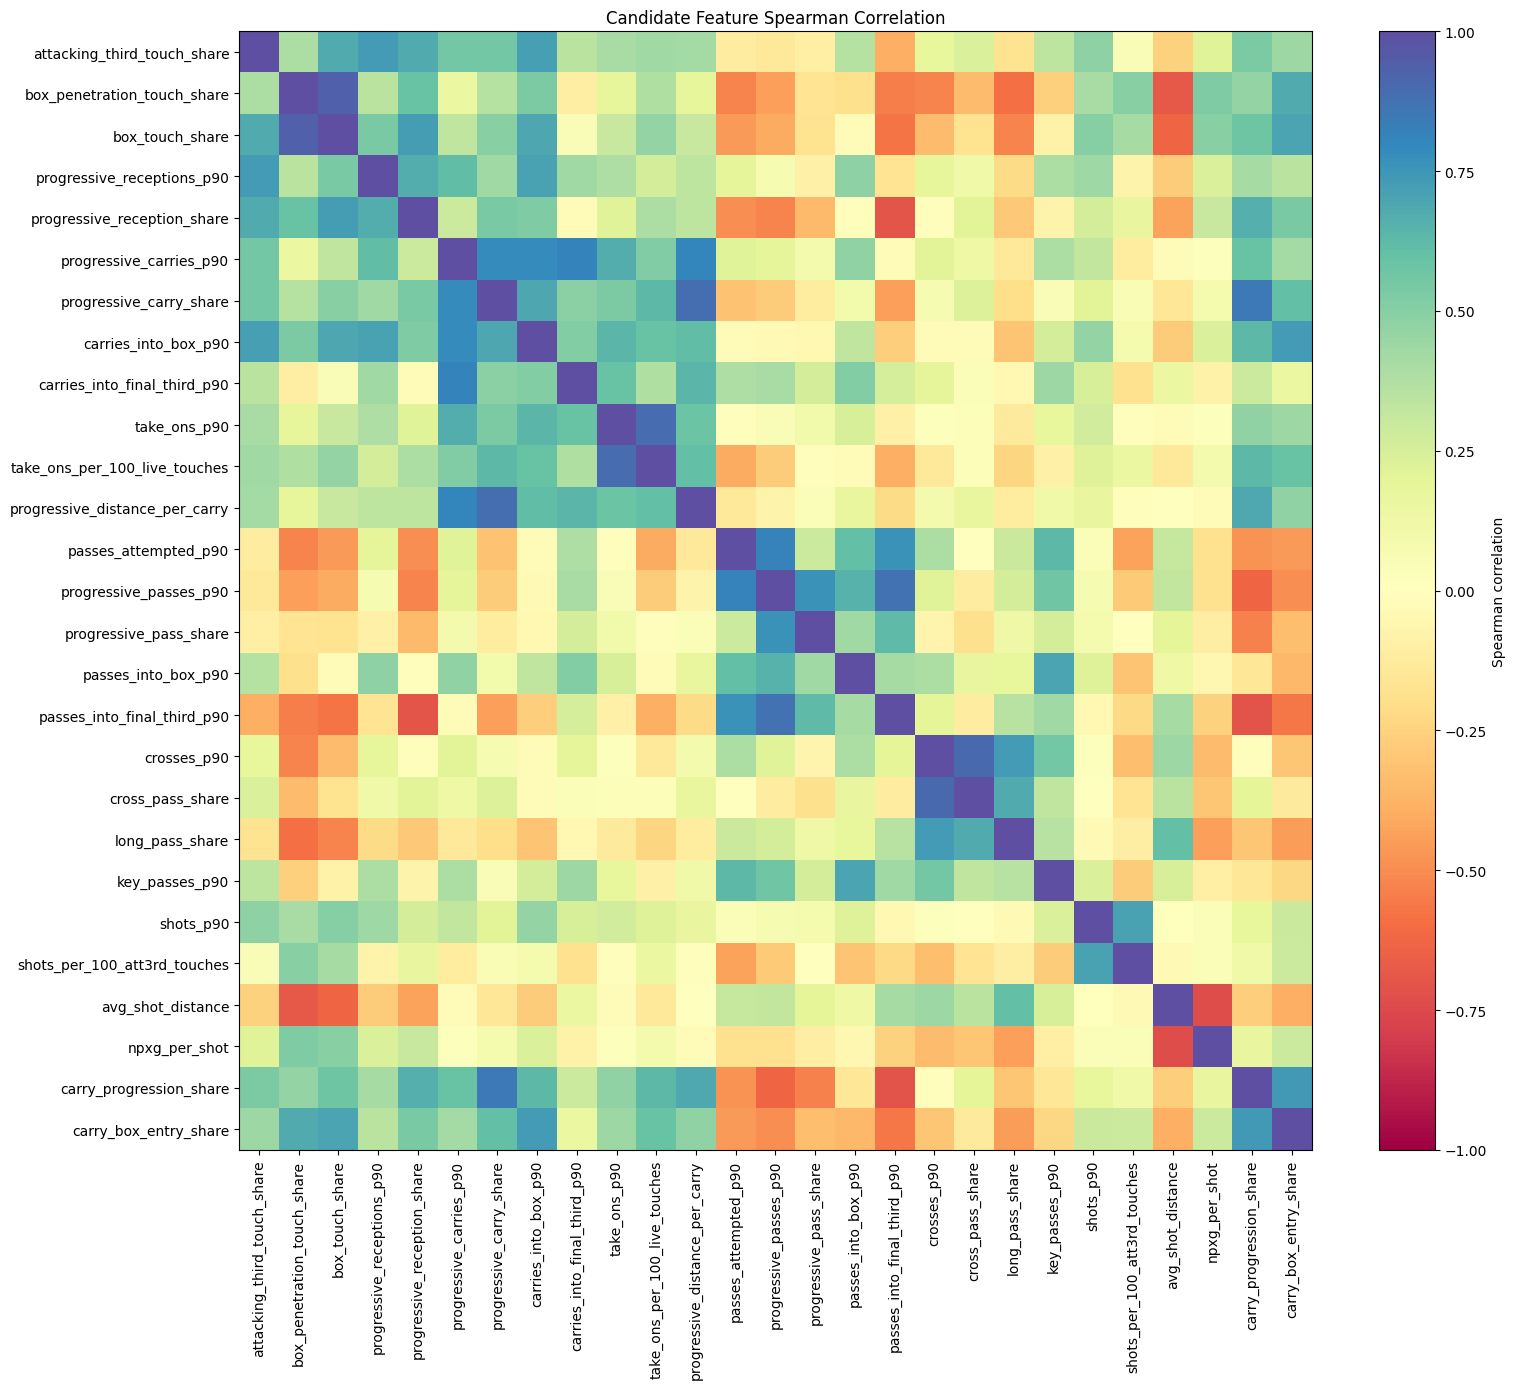

In [366]:
fig, ax = plt.subplots(
    figsize=(16, 14)
)

im = ax.imshow(
    spearman_corr,
    vmin=-1,
    vmax=1,
    aspect="auto",
    cmap = "Spectral"
)

ax.set_xticks(
    range(len(candidate_features))
)

ax.set_yticks(
    range(len(candidate_features))
)

ax.set_xticklabels(
    candidate_features,
    rotation=90
)

ax.set_yticklabels(
    candidate_features
)

ax.set_title(
    "Candidate Feature Spearman Correlation"
)

fig.colorbar(
    im,
    ax=ax,
    label="Spearman correlation"
)

plt.tight_layout()
plt.show()

### 11.4.1 Feature Selection and Pruning

The initial correlation analysis identifies statistical overlap among the
27 engineered candidate features.

Feature selection will be conducted in two stages:

**Stage 1 — Structural and conceptual screening**

Remove variables that are mathematically redundant, insufficiently
distinct, or more appropriate as supporting/contextual descriptors.

**Stage 2 — Empirical redundancy assessment**

Investigate strongly correlated features that survive the initial
screening.

The following questions guide the assessment:

1. Do the variables measure the same underlying football behaviour?
2. Do they distinguish meaningfully different player profiles despite
   their overall correlation?
3. Does removing a variable substantially affect stylistic similarity?
4. Would retaining both variables unintentionally overweight one
   behavioural dimension?

The final representation is selected through football interpretation
and empirical evidence, rather than an automatic correlation threshold.

In [367]:
initial_exclusions = {
    "box_touch_share": (
        "Drop",
        "Mathematically determined by attacking_third_touch_share "
        "and box_penetration_touch_share."
    ),

    "carries_into_final_third_p90": (
        "Drop",
        "Overlaps with progressive carrying and box-carrying measures; "
        "limited additional behavioural distinction."
    ),

    "passes_into_final_third_p90": (
        "Drop",
        "Overlaps with progressive passing and penalty-area passing; "
        "limited additional behavioural distinction."
    ),

    "passes_attempted_p90": (
        "Move to context",
        "General passing involvement and possession context rather "
        "than a sufficiently distinctive attacking-style variable."
    ),

    "key_passes_p90": (
        "Move to support",
        "Depends on a subsequent shot and partly reflects "
        "downstream attacking outcomes."
    ),

    "npxg_per_shot": (
        "Move to support",
        "Reflects shot location and opportunity quality; "
        "avg_shot_distance provides a cleaner location tendency."
    )
}

provisional_features = [
    feature
    for feature in candidate_features
    if feature not in initial_exclusions
]

print("Original candidates:", len(candidate_features))
print("Initial exclusions:", len(initial_exclusions))
print("Provisional features:", len(provisional_features))

assert len(provisional_features) == 21

remaining_strong_pairs = strong_pairs[
    strong_pairs["feature_1"].isin(provisional_features)
    &
    strong_pairs["feature_2"].isin(provisional_features)
].copy()

print(
    "\nStrongly correlated pairs remaining:",
    len(remaining_strong_pairs)
)

display(
    remaining_strong_pairs[
        [
            "feature_1",
            "feature_2",
            "spearman",
            "pearson"
        ]
    ]
)

Original candidates: 27
Initial exclusions: 6
Provisional features: 21

Strongly correlated pairs remaining: 5


,feature_1,feature_2,spearman,pearson
306,crosses_p90,cross_pass_share,0.904603,0.882209
198,take_ons_p90,take_ons_per_100_live_touches,0.897287,0.881375
145,progressive_carry_share,progressive_distance_per_carry,0.889266,0.894507
159,progressive_carry_share,carry_progression_share,0.845767,0.843982
125,progressive_carries_p90,progressive_distance_per_carry,0.801153,0.790338


### 11.4.2 Behavioural Distinctiveness of Correlated Features

A high correlation does not necessarily imply that two features
describe interchangeable behaviours.

For example:

- Crosses per 90 represents actual match-level crossing volume.
- Crosses as a share of attempted passes represents crossing
  propensity relative to passing involvement.

A player can rank relatively low on one and high on the other.

To investigate such differences, percentile rankings are compared
for each strongly correlated feature pair.

Large differences identify player spells for which the two variables
provide contrasting behavioural descriptions.

A 25-percentile-point difference is used as a descriptive inspection
threshold, not as an automatic feature-retention rule.

In [368]:
# Percentile ranks among the provisional features
feature_ranks = feature_df[
    provisional_features
].rank(pct=True)

rank_audit = []
rank_examples = []

for _, pair in remaining_strong_pairs.iterrows():

    a = pair["feature_1"]
    b = pair["feature_2"]

    gap = feature_ranks[a] - feature_ranks[b]

    rank_audit.append({
        "feature_1": a,
        "feature_2": b,
        "spearman": pair["spearman"],
        "mean_gap_pp": gap.abs().mean() * 100,
        "pct_gap_ge_25pp": (
            (gap.abs() >= 0.25).mean() * 100
        )
    })

    # Largest disagreement in each direction
    for idx in [gap.idxmax(), gap.idxmin()]:

        rank_examples.append({
            "player": feature_df.loc[idx, "player"],
            "squad": feature_df.loc[idx, "squad"],
            "season": feature_df.loc[idx, "season"],
            "feature_1": a,
            "feature_2": b,
            "feature_1_percentile": (
                feature_ranks.loc[idx, a] * 100
            ),
            "feature_2_percentile": (
                feature_ranks.loc[idx, b] * 100
            ),
            "rank_gap_pp": gap.loc[idx] * 100
        })

rank_audit = pd.DataFrame(rank_audit)
rank_examples = pd.DataFrame(rank_examples)

display(rank_audit.round(2))

print("\nPlayer examples with contrasting rankings:")
display(rank_examples.round(1))

,feature_1,feature_2,spearman,mean_gap_pp,pct_gap_ge_25pp
0,crosses_p90,cross_pass_share,0.90,9.47,6.23
1,take_ons_p90,take_ons_per_100_live_touches,0.90,9.62,7.09
2,progressive_carry_share,progressive_distance_per_carry,0.89,10.19,7.45
3,progressive_carry_share,carry_progression_share,0.85,12.00,11.82
4,progressive_carries_p90,progressive_distance_per_carry,0.80,13.50,17.48



Player examples with contrasting rankings:


,player,squad,season,feature_1,feature_2,feature_1_percentile,feature_2_percentile,rank_gap_pp
0,Mesut Özil,Arsenal,2017-2018,crosses_p90,cross_pass_share,68.6,26.1,42.5
1,Brennan Johnson,Nott'ham Forest,2022-2023,crosses_p90,cross_pass_share,28.3,71.9,-43.6
2,Neymar,Paris S-G,2022-2023,take_ons_p90,take_ons_per_100_live_touches,91.5,45.9,45.6
3,Brennan Johnson,Nott'ham Forest,2022-2023,take_ons_p90,take_ons_per_100_live_touches,35.6,87.7,-52.1
4,Karlan Grant,West Brom,2020-2021,progressive_carry_share,progressive_distance_per_carry,61.9,9.0,52.9
5,Carlos Soler,Valencia,2020-2021,progressive_carry_share,progressive_distance_per_carry,3.4,64.5,-61.2
6,Florian Kainz,Werder Bremen,2017-2018,progressive_carry_share,carry_progression_share,75.3,19.1,56.2
7,Federico Di Francesco,Bologna,2017-2018,progressive_carry_share,carry_progression_share,25.9,84.6,-58.6
8,Paulo Dybala,Juventus,2019-2020,progressive_carries_p90,progressive_distance_per_carry,77.7,11.2,66.5
9,Brennan Johnson,Nott'ham Forest,2022-2023,progressive_carries_p90,progressive_distance_per_carry,36.2,97.1,-60.9


### 11.4.3 Nearest-Neighbour Sensitivity

The second redundancy diagnostic examines whether removing a
correlated feature materially changes player similarity.

A temporary standardized representation of the 21 provisional
features is constructed.

For each feature involved in a strong-correlation pair:

1. Identify every observation's ten nearest neighbours using
   Euclidean distance.
2. Remove the feature and recompute the neighbours.
3. Measure the proportion of neighbours that remain unchanged.

This is a local sensitivity diagnostic rather than the project's
final player-similarity model.

The purpose is to understand the influence of individual features
on the geometry of the representation.

Neither high neighbour overlap nor low overlap independently
determines whether a feature should be retained.

In [369]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

# Temporary scaling for diagnostic purposes only
temp_scaler = StandardScaler()

temp_X = pd.DataFrame(
    temp_scaler.fit_transform(
        feature_df[provisional_features]
    ),
    columns=provisional_features,
    index=feature_df.index
)

def nearest_neighbours(X, k=10):

    distances = pairwise_distances(
        X,
        metric="euclidean"
    )

    np.fill_diagonal(distances, np.inf)

    return np.argpartition(
        distances,
        kth=k - 1,
        axis=1
    )[:, :k]


k = 10

baseline_neighbours = nearest_neighbours(
    temp_X,
    k=k
)

# Only features involved in remaining strong pairs
review_features = sorted(
    set(remaining_strong_pairs["feature_1"])
    |
    set(remaining_strong_pairs["feature_2"])
)

sensitivity_results = []

for feature in review_features:

    alternative_X = temp_X.drop(
        columns=[feature]
    )

    alternative_neighbours = nearest_neighbours(
        alternative_X,
        k=k
    )

    overlaps = np.array([
        len(set(original) & set(alternative)) / k
        for original, alternative in zip(
            baseline_neighbours,
            alternative_neighbours
        )
    ])

    sensitivity_results.append({
        "removed_feature": feature,
        "mean_top10_overlap": overlaps.mean(),
        "mean_neighbours_changed": (
            k * (1 - overlaps.mean())
        ),
        "pct_3plus_changed": (
            (overlaps <= 0.70).mean() * 100
        )
    })

sensitivity_results = (
    pd.DataFrame(sensitivity_results)
    .sort_values("mean_top10_overlap")
)

display(sensitivity_results.round(3))

,removed_feature,mean_top10_overlap,mean_neighbours_changed,pct_3plus_changed
5,progressive_distance_per_carry,0.877,1.232,8.811
7,take_ons_per_100_live_touches,0.878,1.223,8.811
6,take_ons_p90,0.883,1.168,7.521
1,cross_pass_share,0.890,1.099,6.662
2,crosses_p90,0.901,0.989,5.014
4,progressive_carry_share,0.913,0.868,2.865
3,progressive_carries_p90,0.925,0.746,1.719
0,carry_progression_share,0.929,0.707,0.788


### 11.4.4 Final Feature-Selection Decisions

The redundancy review provides three main conclusions.

**Crossing and take-on volume versus propensity**

Although these feature pairs are strongly correlated, their
denominators represent different football concepts. Their
player-ranking disagreements support retaining both
representations.

**Carrying propensity versus progression method**

Progressive carry share describes the proportion of carries that
are progressive. Carry progression share instead describes the
relative use of carrying versus passing for progression.

These are related but distinct behavioural questions.

**Progressive distance per carry**

This variable has substantial statistical overlap with multiple
carrying measures.

Although it identifies some distinctive player profiles, its
incremental contribution must be weighed against the risk of
overrepresenting the carrying dimension.

The final selection is recorded explicitly, including the reason
for every exclusion or retained high-correlation feature.

In [370]:
# Additional decisions following redundancy diagnostics
additional_exclusions = {
    "progressive_distance_per_carry": (
        "Drop",
        "Strong overlap with progressive_carry_share and "
        "progressive_carries_p90; excluded to limit "
        "overweighting of carrying behaviour."
    )
}

# Combine all exclusions
all_exclusions = {
    **initial_exclusions,
    **additional_exclusions
}

# Create final decision registry
feature_decisions = feature_registry.copy()

feature_decisions["decision"] = "Retain"
feature_decisions["reason"] = ""

for feature, (decision, reason) in all_exclusions.items():

    mask = feature_decisions["feature"] == feature

    assert mask.sum() == 1, feature

    feature_decisions.loc[mask, "decision"] = decision
    feature_decisions.loc[mask, "reason"] = reason


# Document deliberately retained correlated variables
retention_reasons = {
    "crosses_p90":
        "Retained as crossing volume per 90; distinct from "
        "crossing propensity relative to passing.",

    "cross_pass_share":
        "Retained as crossing propensity; distinguishes crossing "
        "orientation from total crossing volume.",

    "take_ons_p90":
        "Retained as take-on volume per 90; distinct from "
        "per-touch dribbling propensity.",

    "take_ons_per_100_live_touches":
        "Retained as take-on propensity relative to involvement; "
        "captures behaviour not fully reflected by volume.",

    "progressive_carry_share":
        "Retained as progressive carrying propensity among "
        "all carries.",

    "carry_progression_share":
        "Retained as relative choice between carrying and "
        "passing for progression.",

    "long_pass_share":
        "Retained as passing-profile orientation; monitored "
        "for overlap with crossing."
}

for feature, reason in retention_reasons.items():

    mask = (
        (feature_decisions["feature"] == feature)
        &
        (feature_decisions["decision"] == "Retain")
    )

    feature_decisions.loc[mask, "reason"] = reason


retained_candidate_features = (
    feature_decisions.loc[
        feature_decisions["decision"] == "Retain",
        "feature"
    ].tolist()
)

# Move reclassified features to supporting descriptors
support_additions = (
    feature_decisions.loc[
        feature_decisions["decision"] == "Move to support",
        "feature"
    ].tolist()
)

for feature in support_additions:

    support_df[feature] = feature_df[feature]

    if feature not in support_features:
        support_features.append(feature)


# Preserve context features separately
context_features = (
    feature_decisions.loc[
        feature_decisions["decision"] == "Move to context",
        "feature"
    ].tolist()
)

context_df = feature_df[
    identity_cols + context_features
].copy()


# Final validation
assert set(retained_candidate_features).isdisjoint(
    all_exclusions
)

assert (
    feature_decisions["feature"].nunique()
    == len(candidate_features)
)

assert (
    len(retained_candidate_features)
    + len(all_exclusions)
    == len(candidate_features)
)

print("Original candidates:", len(candidate_features))
print("Removed/reclassified:", len(all_exclusions))
print("Final style features:", len(retained_candidate_features))
print("Supporting descriptors:", len(support_features))

display(
    feature_decisions[
        ["feature", "family", "status", "decision", "reason"]
    ]
)

print("\nFinal retained features:")
for feature in retained_candidate_features:
    print("-", feature)

Original candidates: 27
Removed/reclassified: 7
Final style features: 20
Supporting descriptors: 16


,feature,family,status,decision,reason
0,attacking_third_touch_share,Territory,Core,Retain,
1,box_penetration_touch_share,Territory,Core,Retain,
2,box_touch_share,Territory,Secondary,Drop,Mathematically determined by attacking_third_t...
3,progressive_receptions_p90,Receiving,Core,Retain,
4,progressive_reception_share,Receiving,Core,Retain,
5,progressive_carries_p90,Carrying,Core,Retain,
6,progressive_carry_share,Carrying,Core,Retain,Retained as progressive carrying propensity am...
7,carries_into_box_p90,Carrying,Core,Retain,
8,carries_into_final_third_p90,Carrying,Secondary,Drop,Overlaps with progressive carrying and box-car...
9,take_ons_p90,Dribbling,Core,Retain,Retained as take-on volume per 90; distinct fr...



Final retained features:
- attacking_third_touch_share
- box_penetration_touch_share
- progressive_receptions_p90
- progressive_reception_share
- progressive_carries_p90
- progressive_carry_share
- carries_into_box_p90
- take_ons_p90
- take_ons_per_100_live_touches
- progressive_passes_p90
- progressive_pass_share
- passes_into_box_p90
- crosses_p90
- cross_pass_share
- long_pass_share
- shots_p90
- shots_per_100_att3rd_touches
- avg_shot_distance
- carry_progression_share
- carry_box_entry_share


In [371]:
final_strong_pairs = correlation_pairs[
    correlation_pairs["feature_1"].isin(
        retained_candidate_features
    )
    &
    correlation_pairs["feature_2"].isin(
        retained_candidate_features
    )
    &
    (correlation_pairs["abs_spearman"] >= 0.80)
].copy()

print(
    "Remaining strong-correlation pairs:",
    len(final_strong_pairs)
)

display(
    final_strong_pairs[
        [
            "feature_1",
            "feature_2",
            "spearman",
            "pearson"
        ]
    ]
)

Remaining strong-correlation pairs: 3


,feature_1,feature_2,spearman,pearson
306,crosses_p90,cross_pass_share,0.904603,0.882209
198,take_ons_p90,take_ons_per_100_live_touches,0.897287,0.881375
159,progressive_carry_share,carry_progression_share,0.845767,0.843982


## 11.5 Structural Redundancy

Some candidate features are related not only statistically but mathematically.

For example:

$$
BoxTouchShare =
\frac{AttackingPenaltyAreaTouches}{TotalTouches}
$$

can be decomposed as:

$$
\frac{AttackingThirdTouches}{TotalTouches}
\times
\frac{AttackingPenaltyAreaTouches}{AttackingThirdTouches}
$$

Therefore:

`box_touch_share`

contains no completely independent information if both:

- `attacking_third_touch_share`
- `box_penetration_touch_share`

are already retained.

This type of structural redundancy is treated more strongly than ordinary statistical correlation.

In [372]:
abs_spearman = spearman_corr.abs()

mean_abs_corr = (
    (
        abs_spearman.sum(axis=1) - 1
    )
    /
    (
        len(candidate_features) - 1
    )
)

max_abs_corr = (
    abs_spearman
    .where(
        ~np.eye(
            len(abs_spearman),
            dtype=bool
        )
    )
    .max(axis=1)
)

correlation_centrality = pd.DataFrame({
    "feature": candidate_features,
    "mean_abs_correlation": [
        mean_abs_corr[f]
        for f in candidate_features
    ],
    "max_abs_correlation": [
        max_abs_corr[f]
        for f in candidate_features
    ]
})

correlation_centrality = (
    correlation_centrality
    .merge(
        feature_registry,
        on="feature",
        how="left"
    )
    .sort_values(
        "mean_abs_correlation",
        ascending=False
    )
)

display(correlation_centrality)

,feature,mean_abs_correlation,max_abs_correlation,family,status
2,box_touch_share,0.445993,0.934003,Territory,Secondary
26,carry_box_entry_share,0.438787,0.736469,Penetration Method,Core
25,carry_progression_share,0.438509,0.845767,Progression Method,Core
1,box_penetration_touch_share,0.423542,0.934003,Territory,Core
7,carries_into_box_p90,0.412865,0.781727,Carrying,Core
6,progressive_carry_share,0.389461,0.889266,Carrying,Core
4,progressive_reception_share,0.385717,0.726324,Receiving,Core
16,passes_into_final_third_p90,0.383715,0.868134,Passing,Secondary
0,attacking_third_touch_share,0.380843,0.727847,Territory,Core
5,progressive_carries_p90,0.370645,0.812381,Carrying,Core


### Interpreting Cross-Family Correlations

Correlation between conceptually different football behaviours is expected.

For example, advanced players may simultaneously:

- receive more progressive passes;
- take more shots;
- enter the penalty area more frequently.

Such relationships reflect football structure and do not automatically imply that one variable should be removed.

Feature removal is prioritized when:

1. the variables measure essentially the same behaviour;
2. one variable is mathematically derived from another;
3. correlation is extremely high;
4. one representation has a clearer football interpretation or stronger data quality.

# 12. Final Matrix Design and Scaling

After conceptual screening, feature-quality auditing and the first redundancy pass, the candidate playstyle representation has been reduced from 27 to 20 behavioural features.

The earlier expectation of approximately 12–18 final dimensions was a planning guideline rather than a fixed target.

Further features are not removed solely to satisfy a predetermined feature count. A variable is retained when it represents a conceptually distinct behaviour and has passed the preceding quality checks.

Before modelling, two additional issues must be addressed:

1. **feature-family balance** — ensuring that one behavioural family does not dominate simply because it contains more variables;
2. **feature scaling** — putting features measured in different units onto a comparable numerical scale.

The primary modelling matrix will use standardized features with equal feature-level weighting.

A family-balanced version will also be constructed later as a sensitivity analysis.

In [373]:
macro_family_map = {
    # Territory
    "attacking_third_touch_share": "Territory",
    "box_penetration_touch_share": "Territory",

    # Receiving
    "progressive_receptions_p90": "Receiving",
    "progressive_reception_share": "Receiving",

    # Carrying
    "progressive_carries_p90": "Carrying",
    "progressive_carry_share": "Carrying",
    "carries_into_box_p90": "Carrying",
    "progressive_distance_per_carry": "Carrying",

    # Dribbling
    "take_ons_p90": "Dribbling",
    "take_ons_per_100_live_touches": "Dribbling",

    # Passing
    "progressive_passes_p90": "Passing",
    "progressive_pass_share": "Passing",
    "passes_into_box_p90": "Passing",
    "long_pass_share": "Passing",

    # Crossing
    "crosses_p90": "Crossing",
    "cross_pass_share": "Crossing",

    # Shooting
    "shots_p90": "Shooting",
    "shots_per_100_att3rd_touches": "Shooting",
    "avg_shot_distance": "Shooting",

    # Relative behavioural choice
    "carry_progression_share": "Behavioural Choice",
    "carry_box_entry_share": "Behavioural Choice"
}

In [374]:
macro_family_map = {
    feature: family
    for feature, family in macro_family_map.items()
    if feature in retained_candidate_features
}

assert set(macro_family_map) == set(retained_candidate_features)

In [375]:
assert set(macro_family_map.keys()) == set(retained_candidate_features)

print("All retained features assigned to a macro family.")

All retained features assigned to a macro family.


In [376]:
family_balance = (
    pd.Series(macro_family_map)
    .value_counts()
    .rename_axis("family")
    .reset_index(name="n_features")
)

family_balance["share_of_features_pct"] = (
    family_balance["n_features"] /
    len(retained_candidate_features) *
    100
)

display(family_balance)

,family,n_features,share_of_features_pct
0,Passing,4,20.0
1,Carrying,3,15.0
2,Shooting,3,15.0
3,Territory,2,10.0
4,Dribbling,2,10.0
5,Receiving,2,10.0
6,Crossing,2,10.0
7,Behavioural Choice,2,10.0


## 12.1 Feature-Family Balance

The retained candidate set contains eight broader behavioural families.

The largest family, Passing, contain four features, while other families contain two or three.

This is considered sufficiently balanced to avoid additional feature deletion solely on the basis of feature count.

Importantly, the retained variables within the larger families describe distinct concepts such as:


- volume;
- orientation;
- territorial penetration;
- action characteristics.

Further pruning at this stage would risk removing meaningful behavioural distinctions simply to achieve an arbitrary feature total.

The 20-feature representation is therefore retained for the initial modelling stage.

In [377]:
style_matrix_raw = (
    feature_df[
        retained_candidate_features
    ]
    .copy()
)

retained_missing = (
    style_matrix_raw
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_n")
)

retained_missing["missing_pct"] = (
    retained_missing["missing_n"] /
    len(style_matrix_raw) *
    100
)

display(retained_missing)

,missing_n,missing_pct
attacking_third_touch_share,0,0.0
box_penetration_touch_share,0,0.0
progressive_receptions_p90,0,0.0
progressive_reception_share,0,0.0
progressive_carries_p90,0,0.0
progressive_carry_share,0,0.0
carries_into_box_p90,0,0.0
take_ons_p90,0,0.0
take_ons_per_100_live_touches,0,0.0
progressive_passes_p90,0,0.0


In [378]:
print(
    "Total missing cells:",
    style_matrix_raw.isna().sum().sum()
)

Total missing cells: 0


In [379]:
finite_check = np.isfinite(
    style_matrix_raw.to_numpy(dtype=float)
)

print(
    "Non-finite values:",
    (~finite_check).sum()
)

Non-finite values: 0


In [380]:
assert style_matrix_raw.isna().sum().sum() == 0

assert np.isfinite(
    style_matrix_raw.to_numpy(dtype=float)
).all()

## 12.2 Feature Scaling

The retained features use different numerical units.

Examples include:

- proportions;
- actions per 90;
- actions per 100 touches;
- distances.

Using the raw values directly in PCA, clustering or distance-based similarity would therefore cause features with larger numerical scales to dominate the analysis.

The primary feature matrix is standardized using:

$$
z =
\frac{x-\mu}{\sigma}
$$

Each feature therefore has approximately:

- mean = 0;
- standard deviation = 1.

Standardization is performed across the complete player-season population rather than independently by season.

Season-specific standardization is deliberately avoided because the temporal audit identified genuine historical football variation that should remain visible in the data.

Standardization changes numerical scale, not the underlying ranking or interpretation of a feature.

In [381]:
from sklearn.preprocessing import StandardScaler

In [382]:
scaler = StandardScaler()

style_matrix_scaled = pd.DataFrame(
    scaler.fit_transform(style_matrix_raw),
    columns=retained_candidate_features,
    index=feature_df.index
)

In [383]:
scaling_check = pd.DataFrame({
    "mean": style_matrix_scaled.mean(),
    "std_population": style_matrix_scaled.std(ddof=0)
})

display(scaling_check)

,mean,std_population
attacking_third_touch_share,4.122777e-16,1.0
box_penetration_touch_share,3.359299e-16,1.0
progressive_receptions_p90,2.773967e-16,1.0
progressive_reception_share,-3.308401e-16,1.0
progressive_carries_p90,3.461096e-16,1.0
progressive_carry_share,-2.824865e-16,1.0
carries_into_box_p90,1.857794e-16,1.0
take_ons_p90,8.652741e-17,1.0
take_ons_per_100_live_touches,-2.035939e-16,1.0
progressive_passes_p90,-2.952112e-16,1.0


### Distribution Shape and Transformation

No logarithmic, percentile or quantile transformation is applied automatically to skewed features.

Several football behaviours are naturally concentrated among relatively small groups of players.

For example, unusually high dribbling, carrying or shooting volume may represent genuine stylistic extremity rather than statistical noise.

The preceding feature audit found no justification for suppressing such observations solely to make the distributions more Gaussian.

The primary modelling matrix therefore preserves the original engineered feature distributions and applies only standardization.

Alternative robust scaling may later be used as a sensitivity test.

In [384]:
style_matrix = pd.concat(
    [
        feature_df[identity_cols].reset_index(drop=True),
        style_matrix_scaled.reset_index(drop=True)
    ],
    axis=1
)

print(style_matrix.shape)

display(style_matrix.head())

(1396, 28)


,player,player_id,squad,comp,season,age,born,Minutes,attacking_third_touch_share,box_penetration_touch_share,progressive_receptions_p90,progressive_reception_share,progressive_carries_p90,progressive_carry_share,carries_into_box_p90,take_ons_p90,take_ons_per_100_live_touches,progressive_passes_p90,progressive_pass_share,passes_into_box_p90,crosses_p90,cross_pass_share,long_pass_share,shots_p90,shots_per_100_att3rd_touches,avg_shot_distance,carry_progression_share,carry_box_entry_share
0,Marc Albrighton,Marc Albrighton_1989,Leicester City,Premier League,2017-2018,27,1989,2538,-1.061600,-1.761274,-0.690503,-0.842021,-0.756294,-0.863054,-1.229276,-0.021522,-0.349192,0.255151,-0.332043,-0.000991,2.208260,1.524381,2.916782,-1.711266,-1.798063,0.699326,-0.949513,-1.870998
1,Romain Amalfitano,Romain Amalfitano_1989,Dijon,Ligue 1,2017-2018,27,1989,2703,-4.229951,-2.160147,-2.316999,-2.696367,-1.191729,-1.712120,-1.378095,-0.660671,-0.933729,0.757250,0.319684,-0.822698,-1.295174,-1.453907,1.711811,-2.099987,-0.784405,3.630931,-1.766600,-2.037423
2,Amath,Amath_1996,Getafe,La Liga,2017-2018,21,1996,2859,-0.505638,0.338330,-0.988123,0.637581,-0.894448,-0.081083,-0.223195,-0.202054,0.747663,-0.949884,0.626831,-1.193773,-1.297594,-1.043791,-0.342881,-0.941867,0.116159,-0.289239,0.149203,1.175969
3,Nordin Amrabat,Nordin Amrabat_1987,Leganés,La Liga,2017-2018,30,1987,1623,1.681538,-0.705983,0.217297,0.433399,1.083485,1.243666,0.756615,0.340026,0.914074,-0.523658,0.342731,-0.538141,0.058877,0.738795,-0.218979,-0.025981,-0.208142,1.312918,1.205575,1.175969
4,Felipe Anderson,Felipe Anderson_1993,Lazio,Serie A,2017-2018,24,1993,1162,0.901081,-0.557513,1.277907,-0.151794,3.075253,1.407292,2.676912,3.452237,1.540483,1.718447,0.877893,2.306326,1.229597,0.296179,0.244247,-0.073665,-1.269679,0.324353,0.473355,0.531656


In [385]:
style_matrix_unscaled = pd.concat(
    [
        feature_df[identity_cols].reset_index(drop=True),
        style_matrix_raw.reset_index(drop=True)
    ],
    axis=1
)

In [386]:
family_counts = (
    pd.Series(macro_family_map)
    .value_counts()
)

In [387]:
family_weights = {
    feature: 1 / np.sqrt(
        family_counts[
            macro_family_map[feature]
        ]
    )
    for feature in retained_candidate_features
}

family_weights

{'attacking_third_touch_share': np.float64(0.7071067811865475),
 'box_penetration_touch_share': np.float64(0.7071067811865475),
 'progressive_receptions_p90': np.float64(0.7071067811865475),
 'progressive_reception_share': np.float64(0.7071067811865475),
 'progressive_carries_p90': np.float64(0.5773502691896258),
 'progressive_carry_share': np.float64(0.5773502691896258),
 'carries_into_box_p90': np.float64(0.5773502691896258),
 'take_ons_p90': np.float64(0.7071067811865475),
 'take_ons_per_100_live_touches': np.float64(0.7071067811865475),
 'progressive_passes_p90': np.float64(0.5),
 'progressive_pass_share': np.float64(0.5),
 'passes_into_box_p90': np.float64(0.5),
 'crosses_p90': np.float64(0.7071067811865475),
 'cross_pass_share': np.float64(0.7071067811865475),
 'long_pass_share': np.float64(0.5),
 'shots_p90': np.float64(0.5773502691896258),
 'shots_per_100_att3rd_touches': np.float64(0.5773502691896258),
 'avg_shot_distance': np.float64(0.5773502691896258),
 'carry_progression_s

In [388]:
style_matrix_family_balanced = (
    style_matrix_scaled.copy()
)

for feature in retained_candidate_features:

    style_matrix_family_balanced[feature] *= (
        family_weights[feature]
    )

## 12.3 Family-Balanced Sensitivity Representation

Standardized features receive equal feature-level weight in the primary model.

Because behavioural families contain different numbers of features, an alternative family-balanced matrix is also constructed.

For a feature belonging to a family containing \(n\) variables:

$$
weight =
\frac{1}{\sqrt{n}}
$$

This approximately equalizes the total potential contribution of each behavioural family.

The family-balanced representation is **not treated as the primary model**.

Instead, it will later be used as a sensitivity analysis:

> Do player similarities and discovered archetypes remain broadly stable when behavioural families are given more equal aggregate weight?

If results are stable across both representations, confidence in the discovered playstyle structure increases.

In [389]:
final_feature_spec = (
    feature_decisions[
        feature_decisions["decision"] == "Retain"
    ][
        [
            "feature",
            "family",
            "status",
            "decision",
            "reason"
        ]
    ]
    .copy()
)

final_feature_spec["macro_family"] = (
    final_feature_spec["feature"]
    .map(macro_family_map)
)

final_feature_spec["family_weight"] = (
    final_feature_spec["feature"]
    .map(family_weights)
)

display(final_feature_spec)

,feature,family,status,decision,reason,macro_family,family_weight
0,attacking_third_touch_share,Territory,Core,Retain,,Territory,0.707107
1,box_penetration_touch_share,Territory,Core,Retain,,Territory,0.707107
3,progressive_receptions_p90,Receiving,Core,Retain,,Receiving,0.707107
4,progressive_reception_share,Receiving,Core,Retain,,Receiving,0.707107
5,progressive_carries_p90,Carrying,Core,Retain,,Carrying,0.577350
6,progressive_carry_share,Carrying,Core,Retain,Retained as progressive carrying propensity am...,Carrying,0.577350
7,carries_into_box_p90,Carrying,Core,Retain,,Carrying,0.577350
9,take_ons_p90,Dribbling,Core,Retain,Retained as take-on volume per 90; distinct fr...,Dribbling,0.707107
10,take_ons_per_100_live_touches,Dribbling,Core,Retain,Retained as take-on propensity relative to inv...,Dribbling,0.707107
13,progressive_passes_p90,Passing,Core,Retain,,Passing,0.500000


# Final Candidate Style Representation

Following conceptual design, feature construction, quality auditing, temporal analysis and redundancy review, the playstyle representation contains **01 retained behavioural features**.

These cover eight broader dimensions:

1. Territory
2. Receiving
3. Carrying
4. Dribbling
5. Passing
6. Crossing
7. Shooting
8. Relative behavioural choice

All retained variables have:

- a defined football interpretation;
- passed structural sanity checks;
- been reviewed for temporal comparability;
- survived the first redundancy analysis.

The modelling pipeline will use the globally standardized 21-feature matrix as its primary representation.

A family-balanced version is retained for later robustness testing.

Quality, output and contextual variables remain outside the playstyle feature space and will be reintroduced only after style discovery for interpretation and player evaluation.

# 13. Final Matrix Quality Assurance

Before exporting the engineered playstyle data, the final matrices are checked for:

- preservation of the canonical player × club × season population;
- duplicate observations;
- missing and non-finite modelling values;
- expected feature count;
- correct standardization;
- alignment between raw, standardized and family-balanced representations.

This final check is intended to ensure that feature engineering has changed the representation of the data without changing the underlying analytical population.

In [390]:
print("Canonical enriched dataset:", df.shape)
print("Engineered feature table:", feature_df.shape)
print("Unscaled style matrix:", style_matrix_unscaled.shape)
print("Scaled style matrix:", style_matrix.shape)
print(
    "Family-balanced matrix:",
    style_matrix_family_balanced.shape
)
print("Supporting descriptor table:", support_df.shape)

print(
    "\nRetained behavioural features:",
    len(retained_candidate_features)
)

Canonical enriched dataset: (1396, 119)
Engineered feature table: (1396, 35)
Unscaled style matrix: (1396, 28)
Scaled style matrix: (1396, 28)
Family-balanced matrix: (1396, 20)
Supporting descriptor table: (1396, 24)

Retained behavioural features: 20


In [391]:
qa_key = [
    "player_id",
    "squad",
    "season"
]

for name, dataframe in {
    "feature_df": feature_df,
    "style_matrix_unscaled": style_matrix_unscaled,
    "style_matrix": style_matrix,
    "support_df": support_df
}.items():

    duplicates = dataframe.duplicated(
        subset=qa_key
    ).sum()

    print(
        f"{name}: "
        f"{len(dataframe)} rows, "
        f"{duplicates} duplicate canonical keys"
    )

feature_df: 1396 rows, 0 duplicate canonical keys
style_matrix_unscaled: 1396 rows, 0 duplicate canonical keys
style_matrix: 1396 rows, 0 duplicate canonical keys
support_df: 1396 rows, 0 duplicate canonical keys


In [392]:
assert len(feature_df) == len(df) == 1396
assert len(style_matrix_unscaled) == 1396
assert len(style_matrix) == 1396
assert len(support_df) == 1396

assert not feature_df.duplicated(
    subset=qa_key
).any()

assert not style_matrix_unscaled.duplicated(
    subset=qa_key
).any()

assert not style_matrix.duplicated(
    subset=qa_key
).any()

assert not support_df.duplicated(
    subset=qa_key
).any()

print("Population and grain checks passed.")

Population and grain checks passed.


In [393]:
alignment_cols = [
    "player_id",
    "squad",
    "season"
]

assert (
    style_matrix_unscaled[alignment_cols]
    .reset_index(drop=True)
    .equals(
        style_matrix[alignment_cols]
        .reset_index(drop=True)
    )
)

assert (
    style_matrix[alignment_cols]
    .reset_index(drop=True)
    .equals(
        support_df[alignment_cols]
        .reset_index(drop=True)
    )
)

print("Row alignment across analytical tables passed.")

Row alignment across analytical tables passed.


In [394]:
final_raw_matrix = style_matrix_unscaled[
    retained_candidate_features
]

final_scaled_matrix = style_matrix[
    retained_candidate_features
]

print(
    "Raw missing values:",
    final_raw_matrix.isna().sum().sum()
)

print(
    "Scaled missing values:",
    final_scaled_matrix.isna().sum().sum()
)

print(
    "Raw non-finite values:",
    (
        ~np.isfinite(
            final_raw_matrix.to_numpy(dtype=float)
        )
    ).sum()
)

print(
    "Scaled non-finite values:",
    (
        ~np.isfinite(
            final_scaled_matrix.to_numpy(dtype=float)
        )
    ).sum()
)

Raw missing values: 0
Scaled missing values: 0
Raw non-finite values: 0
Scaled non-finite values: 0


In [395]:
assert final_raw_matrix.isna().sum().sum() == 0
assert final_scaled_matrix.isna().sum().sum() == 0

assert np.isfinite(
    final_raw_matrix.to_numpy(dtype=float)
).all()

assert np.isfinite(
    final_scaled_matrix.to_numpy(dtype=float)
).all()

print("Final modelling matrices contain no missing or non-finite values.")

Final modelling matrices contain no missing or non-finite values.


In [396]:
final_scaling_check = pd.DataFrame({
    "mean": final_scaled_matrix.mean(),
    "std": final_scaled_matrix.std(ddof=0)
})

final_scaling_check["abs_mean"] = (
    final_scaling_check["mean"].abs()
)

final_scaling_check["std_error"] = (
    final_scaling_check["std"] - 1
).abs()

display(final_scaling_check)

,mean,std,abs_mean,std_error
attacking_third_touch_share,4.122777e-16,1.0,4.122777e-16,2.220446e-16
box_penetration_touch_share,3.359299e-16,1.0,3.359299e-16,6.661338e-16
progressive_receptions_p90,2.773967e-16,1.0,2.773967e-16,5.551115e-16
progressive_reception_share,-3.308401e-16,1.0,3.308401e-16,7.771561e-16
progressive_carries_p90,3.461096e-16,1.0,3.461096e-16,0.000000e+00
progressive_carry_share,-2.824865e-16,1.0,2.824865e-16,0.000000e+00
carries_into_box_p90,1.857794e-16,1.0,1.857794e-16,0.000000e+00
take_ons_p90,8.652741e-17,1.0,8.652741e-17,4.440892e-16
take_ons_per_100_live_touches,-2.035939e-16,1.0,2.035939e-16,3.330669e-16
progressive_passes_p90,-2.952112e-16,1.0,2.952112e-16,2.220446e-16


In [397]:
assert (
    final_scaling_check["abs_mean"]
    < 1e-10
).all()

assert (
    final_scaling_check["std_error"]
    < 1e-10
).all()

print("Standardization check passed.")

Standardization check passed.


In [398]:
assert list(
    style_matrix_family_balanced.columns
) == retained_candidate_features

assert len(
    style_matrix_family_balanced
) == len(df)

assert np.isfinite(
    style_matrix_family_balanced
    .to_numpy(dtype=float)
).all()

print(
    "Family-balanced matrix check passed."
)

Family-balanced matrix check passed.


In [399]:
style_matrix_family_balanced_export = pd.concat(
    [
        feature_df[
            identity_cols
        ].reset_index(drop=True),

        style_matrix_family_balanced
        .reset_index(drop=True)
    ],
    axis=1
)

In [400]:
final_inventory = pd.DataFrame({
    "feature": retained_candidate_features
})

final_inventory["macro_family"] = (
    final_inventory["feature"]
    .map(macro_family_map)
)

final_inventory["original_status"] = (
    final_inventory["feature"]
    .map(
        feature_registry
        .set_index("feature")["status"]
    )
)

final_inventory["family_weight"] = (
    final_inventory["feature"]
    .map(family_weights)
)

display(final_inventory)

,feature,macro_family,original_status,family_weight
0,attacking_third_touch_share,Territory,Core,0.707107
1,box_penetration_touch_share,Territory,Core,0.707107
2,progressive_receptions_p90,Receiving,Core,0.707107
3,progressive_reception_share,Receiving,Core,0.707107
4,progressive_carries_p90,Carrying,Core,0.577350
5,progressive_carry_share,Carrying,Core,0.577350
6,carries_into_box_p90,Carrying,Core,0.577350
7,take_ons_p90,Dribbling,Core,0.707107
8,take_ons_per_100_live_touches,Dribbling,Core,0.707107
9,progressive_passes_p90,Passing,Core,0.500000


In [401]:
display(
    final_inventory["macro_family"]
    .value_counts()
    .rename("n_features")
    .to_frame()
)

,n_features
macro_family,
Passing,4
Carrying,3
Shooting,3
Territory,2
Dribbling,2
Receiving,2
Crossing,2
Behavioural Choice,2


# 14. Export Analytical Outputs

Notebook 04 produces several outputs rather than a single dataset because different stages of the later analysis require different representations.

### Raw engineered style matrix

Contains the 20 retained behavioural features in their original interpretable units.

Used for:

- player-profile interpretation;
- reporting;
- visualizations;
- football-level explanation.

### Standardized style matrix

Contains the same 21 features standardized across the complete player-season population.

This is the primary input for:

- PCA;
- similarity analysis;
- clustering;
- other distance-based modelling.

### Family-balanced standardized matrix

Contains the standardized features with additional family-level weighting.

This is retained as a sensitivity-analysis representation rather than the primary model.

### Supporting descriptors

Contains quality, output and supplemental role variables deliberately excluded from style discovery.

These will later be used to evaluate and interpret the discovered playstyles.

### Feature specification

Records the final retained feature set, conceptual family and family-balancing weight.

In [402]:
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/decoding_winger_playstyles"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(OUTPUT_DIR)

/content/decoding_winger_playstyles


In [403]:
style_matrix_unscaled.to_csv(
    OUTPUT_DIR /
    "winger_style_features_raw.csv",
    index=False
)

style_matrix_unscaled.to_parquet(
    OUTPUT_DIR /
    "winger_style_features_raw.parquet",
    index=False
)

In [404]:
style_matrix.to_csv(
    OUTPUT_DIR /
    "winger_style_features_scaled.csv",
    index=False
)

style_matrix.to_parquet(
    OUTPUT_DIR /
    "winger_style_features_scaled.parquet",
    index=False
)

In [405]:
style_matrix_family_balanced_export.to_csv(
    OUTPUT_DIR /
    "winger_style_features_family_balanced.csv",
    index=False
)

style_matrix_family_balanced_export.to_parquet(
    OUTPUT_DIR /
    "winger_style_features_family_balanced.parquet",
    index=False
)

In [406]:
support_df.to_csv(
    OUTPUT_DIR /
    "winger_style_supporting_descriptors.csv",
    index=False
)

support_df.to_parquet(
    OUTPUT_DIR /
    "winger_style_supporting_descriptors.parquet",
    index=False
)

In [407]:
feature_spec_export = final_feature_spec[
    [
        "feature",
        "macro_family",
        "family",
        "status",
        "family_weight",
        "reason"
    ]
].copy()

feature_spec_export.to_csv(
    OUTPUT_DIR /
    "winger_style_feature_specification.csv",
    index=False
)

display(feature_spec_export)

,feature,macro_family,family,status,family_weight,reason
0,attacking_third_touch_share,Territory,Territory,Core,0.707107,
1,box_penetration_touch_share,Territory,Territory,Core,0.707107,
3,progressive_receptions_p90,Receiving,Receiving,Core,0.707107,
4,progressive_reception_share,Receiving,Receiving,Core,0.707107,
5,progressive_carries_p90,Carrying,Carrying,Core,0.577350,
6,progressive_carry_share,Carrying,Carrying,Core,0.577350,Retained as progressive carrying propensity am...
7,carries_into_box_p90,Carrying,Carrying,Core,0.577350,
9,take_ons_p90,Dribbling,Dribbling,Core,0.707107,Retained as take-on volume per 90; distinct fr...
10,take_ons_per_100_live_touches,Dribbling,Dribbling,Core,0.707107,Retained as take-on propensity relative to inv...
13,progressive_passes_p90,Passing,Passing,Core,0.500000,


In [408]:
feature_decisions.to_csv(
    OUTPUT_DIR /
    "winger_style_feature_decisions.csv",
    index=False
)

In [409]:
exported_files = sorted(
    OUTPUT_DIR.iterdir()
)

for path in exported_files:
    print(
        path.name,
        "-",
        round(
            path.stat().st_size / 1024,
            1
        ),
        "KB"
    )

winger_style_feature_decisions.csv - 2.6 KB
winger_style_feature_specification.csv - 1.9 KB
winger_style_features_family_balanced.csv - 646.6 KB
winger_style_features_family_balanced.parquet - 285.3 KB
winger_style_features_raw.csv - 594.1 KB
winger_style_features_raw.parquet - 283.2 KB
winger_style_features_scaled.csv - 641.0 KB
winger_style_features_scaled.parquet - 285.3 KB
winger_style_supporting_descriptors.csv - 417.9 KB
winger_style_supporting_descriptors.parquet - 189.9 KB


In [410]:
test_scaled = pd.read_parquet(
    OUTPUT_DIR /
    "winger_style_features_scaled.parquet"
)

print(test_scaled.shape)

assert test_scaled.shape == style_matrix.shape

assert list(
    test_scaled.columns
) == list(
    style_matrix.columns
)

print("Export round-trip check passed.")

(1396, 28)
Export round-trip check passed.


# 15. Conclusion

This notebook converted the enriched winger dataset into a modelling-ready representation of attacking playstyle.

The process began with 27 conceptually motivated candidate features covering:

- territory;
- receiving;
- carrying;
- dribbling;
- passing;
- crossing;
- shooting;
- relative attacking choices.

Candidate variables were evaluated through:

- definition-level sanity checks;
- extreme-player inspection;
- missingness and sparsity analysis;
- denominator reliability checks;
- temporal-stability analysis;
- within-player seasonal comparisons;
- league-level temporal comparisons;
- correlation and redundancy analysis.

Six variables were removed or reclassified because they were structurally redundant, overly contextual, or more appropriate as quality/output descriptors.

The resulting attacking-style representation contains **20 behavioural features across eight macro families**.

Two modelling representations are retained:

1. a globally standardized feature matrix as the primary representation;
2. a family-balanced standardized matrix for later sensitivity testing.

Quality and output metrics remain deliberately separate from the style matrix.

This completes feature engineering.

The next stage will examine the underlying structure of the 21-dimensional playstyle space before any player archetypes are imposed.

In [411]:
import joblib

joblib.dump(
    scaler,
    OUTPUT_DIR /
    "style_standard_scaler.joblib"
)

['/content/decoding_winger_playstyles/style_standard_scaler.joblib']

In [413]:
import shutil
from google.colab import files

shutil.make_archive('decoding_winger_playstyles', 'zip', '/content/decoding_winger_playstyles')

files.download('decoding_winger_playstyles.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>